# **Investment Replica system with warning on anomaly detection**

## Problem Statement
We consider the following problem:

- There is a **secret portfolio**, a financial **black-box**, which publicly reports its returns on a regular basis (e.g., weekly, monthly, daily).
- We do **not** know either **which instruments** the portfolio contains or **what weight** each instrument has.
- We **do** know the vast investment vehicles available in the markets, such as **bonds, stocks, ETFs, funds, futures contracts**.
- Even if we don't know how the black-box processes input information, we can observe its **output**, i.e., the time series of returns.

Our goal is to **infer the structure of the black-box**, extracting information about latent variables or functions and structural parameters from observed data, and if an 
anomaly period is detected, we want to give a warning blocking the replica in order to let the user choose what to do.


## Dataset Description
This dataset consists of financial data representing:

- **HFRX Index**: A popular index of **Hedge Funds** ([HFRX Index](https://www.hfr.com/indices)) – for those unfamiliar with hedge funds, see [Wikipedia](https://en.wikipedia.org/wiki/Hedge_fund).
- **MSCI World Index**: Global **Developed Equities** ([MSCI World](https://www.msci.com/acwi)).
- **MSCI World All Country Index**: Global **Equities (Developed and Emerging)** ([MSCI ACWI](https://www.msci.com/acwi)).
- **Barclays Bloomberg Global Aggregate Bond Index**: **Global Bonds** (Developed & Emerging, Govt & Corporate) ([Bloomberg](https://www.bloomberg.com/quote/LEGATRUU:IND)).
- **A broad range of Futures contracts** on equity indices, benchmark bonds, currencies, and commodities.



### Available Futures Contracts
| Symbol | Instrument |
|--------|------------------|
| RX1    | Bund (10 Yrs Ger) |
| CO1    | Brent (Oil) |
| DU1    | Schatz (2yrs Gvt Ger) |
| ES1    | S&P 500 (US Equity) |
| GC1    | Gold |
| LLL1   | MSCI Emerging Markets (EM Equity) |
| NQ1    | Nasdaq 100 (Tech Equity) |
| TP1    | Topix (Japanese Equity) |
| TU2    | 2Yrs US Treasury (US Govt) |
| TY1    | 10Yrs US Treasury (US Govt) |
| VG1    | Eurostoxx 50 (EU Equity) |


### Additional Dataset Information
- **Source**: Bloomberg.
- **Frequency**: Weekly data in local currency.
- **Format**: Original, raw format (but mostly clean).
- **Time Period**: October 2007 – April 2021.


## **DATA PREPARATION**


### LOADING LIBRARIES AND DATASET 

In [1]:
# Import necessary libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from sklearn.linear_model import LinearRegression
import scipy.stats as stats
from statsmodels.graphics.gofplots import qqplot
import warnings
from statsmodels.stats.diagnostic import acorr_ljungbox

# Configure visualization settings
sns.set_theme(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

# Define the path to the dataset
file_path = 'Dataset3_PortfolioReplicaStrategyErrataCorrige.xlsx'
file_path2 = 'Dataset3_PortfolioReplicaStrategy.xlsx'
# Reading the Excel file with specific structure:
# - Row 4 contains full names
# - Row 6 contains Bloomberg tickers (note: Excel is 1-indexed, pandas is 0-indexed)
# - Data starts from row 7

# Read full names (row 4)
full_names_df = pd.read_excel(file_path2, header=None,skiprows=3, nrows=1)
full_names = full_names_df.iloc[0].tolist()[1:]  # Skip the first column (date column)

# Read Bloomberg tickers (row 6)
tickers_df = pd.read_excel(file_path2, header=None, skiprows=5, nrows=1)
tickers = tickers_df.iloc[0].tolist()[1:]  # Skip the first column (date column)




PREPARING DATA

In [2]:

# Create a dictionary mapping tickers to full names
variable_info = dict(zip(tickers, full_names))

# Read the actual data without using any row as a header    
data_raw = pd.read_excel(file_path, header=None, skiprows=1)

# First column is the date column
data_raw.columns = ['Date'] + tickers  # Assign the columns correctly using tickers

# Set the date column as the index and ensure it's in datetime format
data_raw['Date'] = pd.to_datetime(data_raw['Date'], format='%d/%m/%Y')
data = data_raw.set_index('Date')

# Set the date column as the index and ensure it's in datetime format
data_raw['Date'] = pd.to_datetime(data_raw['Date'], format='%d/%m/%Y')
data_df = data_raw.set_index('Date')

# Display the first few rows to examine the dataset structure
print("Dataset preview:")
display(data.head())

# Show the variable information (Ticker -> Full Name)
print("\nVariable Information (Bloomberg Ticker -> Full Name):")
for ticker, name in variable_info.items():
    print(f"{ticker} -> {name}")

# Show basic information about the dataset
print("\nDataset information:")
display(data.info())

# Display statistical summary of the dataset
print("\nBasic statistics:")
display(data.describe())


Dataset preview:


,MXWO Index,MXWD Index,LEGATRUU Index,HFRXGL Index,RX1 Comdty,TY1 Comdty,GC1 Comdty,CO1 Comdty,ES1 Comdty,VG1 Comdty,NQ1 Comdty,LLL1 Comdty,TP1 Comdty,DU1 Comdty,TU2 Comdty
Date,,,,,,,,,,,,,,,
2007-10-23,1633.44,414.14,350.2138,1343.63,113.70,110.515625,759.0,82.85,1525.50,4393.0,2212.00,1287.0,1570.5,103.385,103.718750
2007-10-30,1663.89,423.26,352.5413,1356.53,113.79,110.656250,787.8,87.44,1536.00,4476.0,2217.75,1323.9,1610.5,103.410,103.812500
2007-11-06,1651.59,419.51,354.1758,1360.20,113.79,110.875000,823.4,93.26,1525.00,4425.0,2233.50,1320.0,1575.5,103.410,104.046875
2007-11-13,1601.81,405.98,357.2217,1347.16,114.35,111.718750,799.0,88.83,1483.25,4323.0,2066.75,1271.0,1440.5,103.595,104.304688
2007-11-20,1570.74,398.54,359.4446,1335.21,114.72,113.156250,791.4,95.49,1446.00,4296.0,2035.50,1225.2,1472.5,103.800,104.945312



Variable Information (Bloomberg Ticker -> Full Name):
MXWO Index -> MSCI WORLD
MXWD Index -> MSCI ACWI
LEGATRUU Index -> Global Aggregate
HFRXGL Index -> Hedge Fund Research HFRX Globa
RX1 Comdty -> Generic 1st 'RX' Future
TY1 Comdty -> Generic 1st 'TY' Future
GC1 Comdty -> Generic 1st 'GC' Future
CO1 Comdty -> Generic 1st 'CO' Future
ES1 Comdty -> Generic 1st 'ES' Future
VG1 Comdty -> Generic 1st 'VG' Future
NQ1 Comdty -> Generic 1st 'NQ' Future
LLL1 Comdty -> Generic 1st 'LLL' Future
TP1 Comdty -> Generic 1st 'TP' Future
DU1 Comdty -> Generic 1st 'DU' Future
TU2 Comdty -> Generic 2nd 'TU' Future

Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 705 entries, 2007-10-23 to 2021-04-20
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   MXWO Index      705 non-null    float64
 1   MXWD Index      705 non-null    float64
 2   LEGATRUU Index  705 non-null    float64
 3   HFRXGL Index    70

None


Basic statistics:


,MXWO Index,MXWD Index,LEGATRUU Index,HFRXGL Index,RX1 Comdty,TY1 Comdty,GC1 Comdty,CO1 Comdty,ES1 Comdty,VG1 Comdty,NQ1 Comdty,LLL1 Comdty,TP1 Comdty,DU1 Comdty,TU2 Comdty
count,705.00000,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000
mean,1644.12566,404.151915,452.203206,1210.092071,147.278837,125.966977,1317.902837,77.018496,1960.443050,3072.167631,4526.981206,1064.444113,1277.263121,110.221277,108.627682
std,443.39041,100.980126,47.338067,73.965200,19.318527,6.295242,274.477979,26.794278,770.070634,473.812729,2900.866833,128.954655,353.598276,2.374875,1.532632
min,705.35000,176.100000,342.247100,1021.400000,110.200000,110.515625,732.700000,19.330000,689.500000,1873.000000,1072.000000,465.100000,704.000000,102.190000,103.718750
25%,1293.43000,328.790000,431.737400,1158.150000,128.900000,121.203125,1178.000000,54.270000,1314.500000,2753.000000,2244.000000,1103.600000,905.000000,109.230000,107.871094
50%,1646.69000,402.570000,456.728800,1215.200000,148.000000,126.000000,1283.000000,72.050000,1909.250000,3071.000000,3884.750000,1103.600000,1302.500000,110.855000,109.093750
75%,1978.83000,478.410000,478.186800,1254.250000,163.240000,130.343750,1499.700000,105.780000,2569.750000,3433.000000,6333.250000,1103.600000,1587.500000,111.990000,109.906250
max,2944.05000,702.990000,559.311700,1415.110000,179.320000,140.328125,2001.200000,140.670000,4132.800000,4476.000000,13975.750000,1323.900000,1978.000000,112.720000,110.527344


### FIXING LLL1 COMDTY

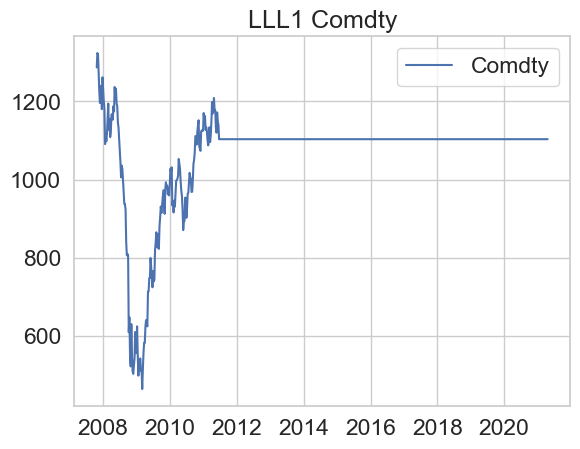

In [3]:
plt.plot(data['LLL1 Comdty'], label='Comdty')
plt.legend()
plt.title('LLL1 Comdty')
plt.show()

In [4]:
from sklearn.linear_model import LinearRegression

train = data.iloc[:196].dropna()
X_train = train.drop(columns='LLL1 Comdty')
y_train = train['LLL1 Comdty']

model_LR = LinearRegression().fit(X_train, y_train)

X_predict = data.iloc[196:].drop(columns='LLL1 Comdty')
predicted_values = model_LR.predict(X_predict)
data_copy = data.copy()
data_copy.iloc[196:, data.columns.get_loc('LLL1 Comdty')] = predicted_values

data['LLL1 Comdty'].iloc[196:] = data_copy['LLL1 Comdty'].iloc[196:]



C:\Users\Francesco\AppData\Local\Temp\ipykernel_34296\3309285451.py:14: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data['LLL1 Comdty'].iloc[196:] = data_copy['LLL1 Comdty'].iloc[196:]


Visualize LLL1 comdty for completition

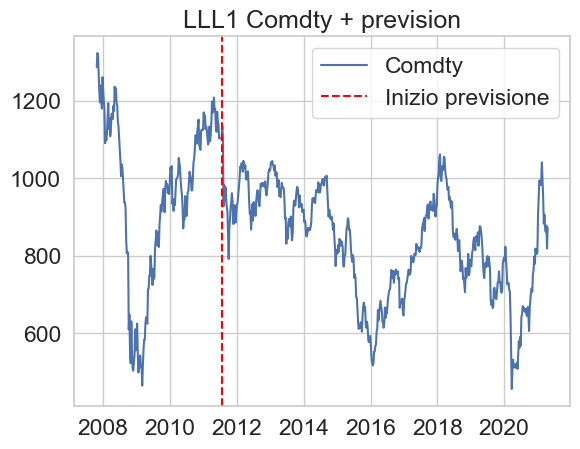

In [5]:


plt.plot(data['LLL1 Comdty'], label='Comdty')
plt.axvline(data.index[196], color='red', linestyle='--', label='Inizio previsione')
plt.legend()
plt.title('LLL1 Comdty + prevision')
plt.show()


# **Data Exploration**

Let's analyze the potential replication targets to understand their characteristics.



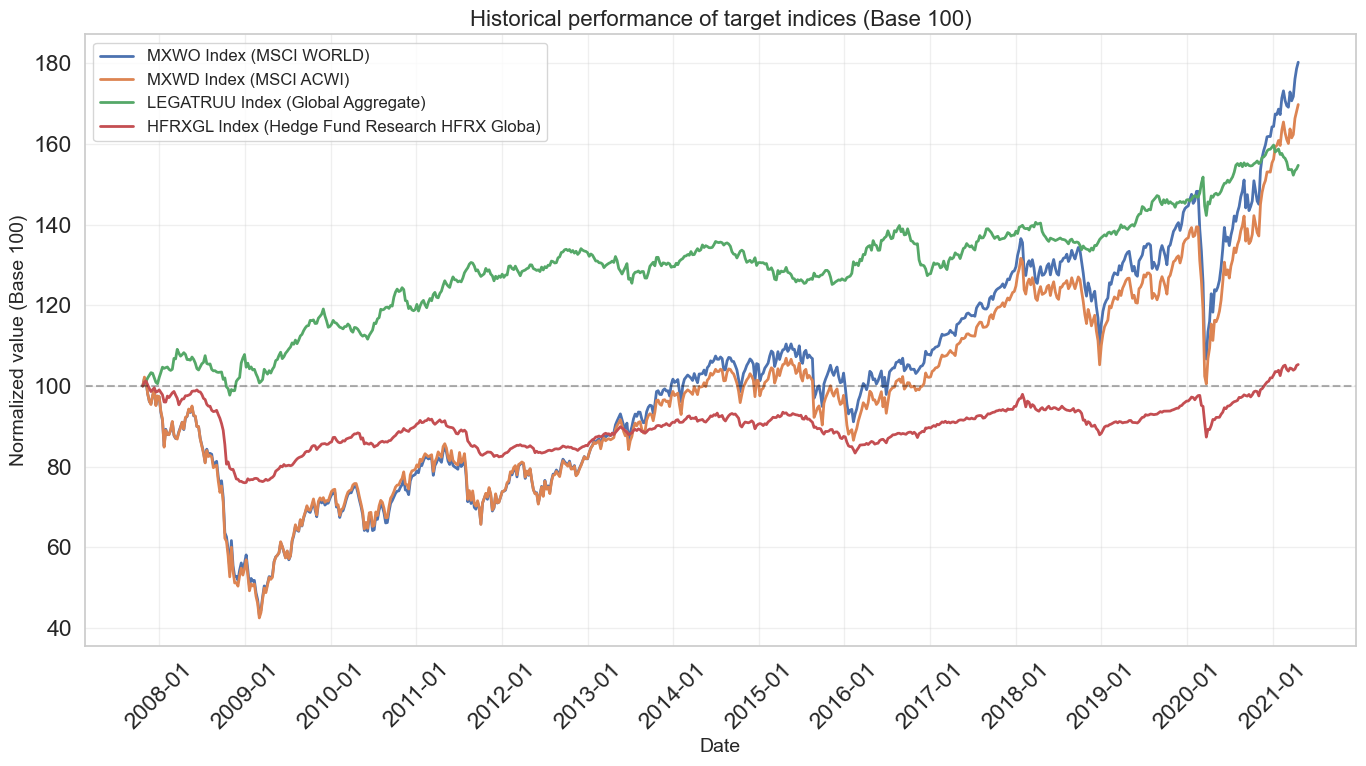


Return statistics for target indices:


,Annualized Return,Annualized Volatility,Sharpe Ratio,Max Drawdown,Skewness,Kurtosis
MXWO Index,5.90%,17.52%,0.336955,-57.61%,-0.682289,4.357034
MXWD Index,5.51%,17.78%,0.309683,-58.39%,-0.641270,4.663275
LEGATRUU Index,3.37%,5.34%,0.630472,-10.41%,-0.329675,4.118169
HFRXGL Index,0.50%,4.78%,0.104156,-24.91%,-2.301318,13.702270


In [6]:
# Target indices to explore
target_indices = ['MXWO Index', 'MXWD Index', 'LEGATRUU Index', 'HFRXGL Index']

# Create a figure for the historical price series
plt.figure(figsize=(14, 8))

# Plot each index
for idx in target_indices:
    # Normalize to 100 at the beginning for comparison
    normalized_series = data[idx] / data[idx].iloc[0] * 100
    plt.plot(normalized_series.index, normalized_series, linewidth=2, label=f"{idx} ({variable_info.get(idx, idx)})")

# Format the plot
plt.title('Historical performance of target indices (Base 100)', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Normalized value (Base 100)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(loc='best', fontsize=12)

# Format the x-axis to show dates nicely
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.xticks(rotation=45)

# Add a horizontal line at y=100
plt.axhline(y=100, color='black', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate and display statistics for all indices
print("\nReturn statistics for target indices:")
# Calculate returns
returns = data[target_indices].pct_change().dropna()

# Calculate annualized statistics (assuming weekly data)
annual_factor = 52  # For weekly data (52 weeks = 1 year)

# Format as percentage with 2 decimal places
def format_pct(x):
    return f"{x*100:.2f}%"

stats = pd.DataFrame({
    'Annualized Return': returns.mean() * annual_factor,
    'Annualized Volatility': returns.std() * np.sqrt(annual_factor),
    'Sharpe Ratio': (returns.mean() * annual_factor) / (returns.std() * np.sqrt(annual_factor)),
    'Max Drawdown': returns.apply(lambda x: (1 + x).cumprod().div((1 + x).cumprod().cummax()) - 1).min(),
    'Skewness': returns.skew(),
    'Kurtosis': returns.kurtosis()
})

# Convert some columns to percentage format for better readability
for col in ['Annualized Return', 'Annualized Volatility', 'Max Drawdown']:
    stats[col] = stats[col].apply(format_pct)

display(stats)

### Correlation & probability distribution analysis
Understanding the shape and the relationships between different indices helps us understanding the behavior of our ingredients and identify potential replication components.

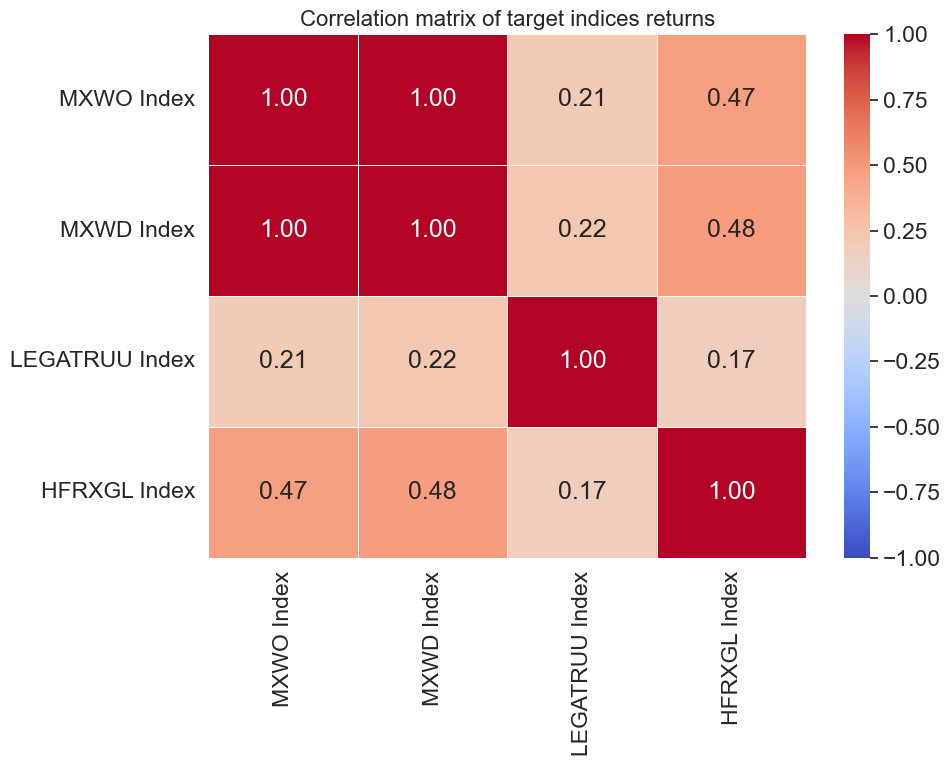

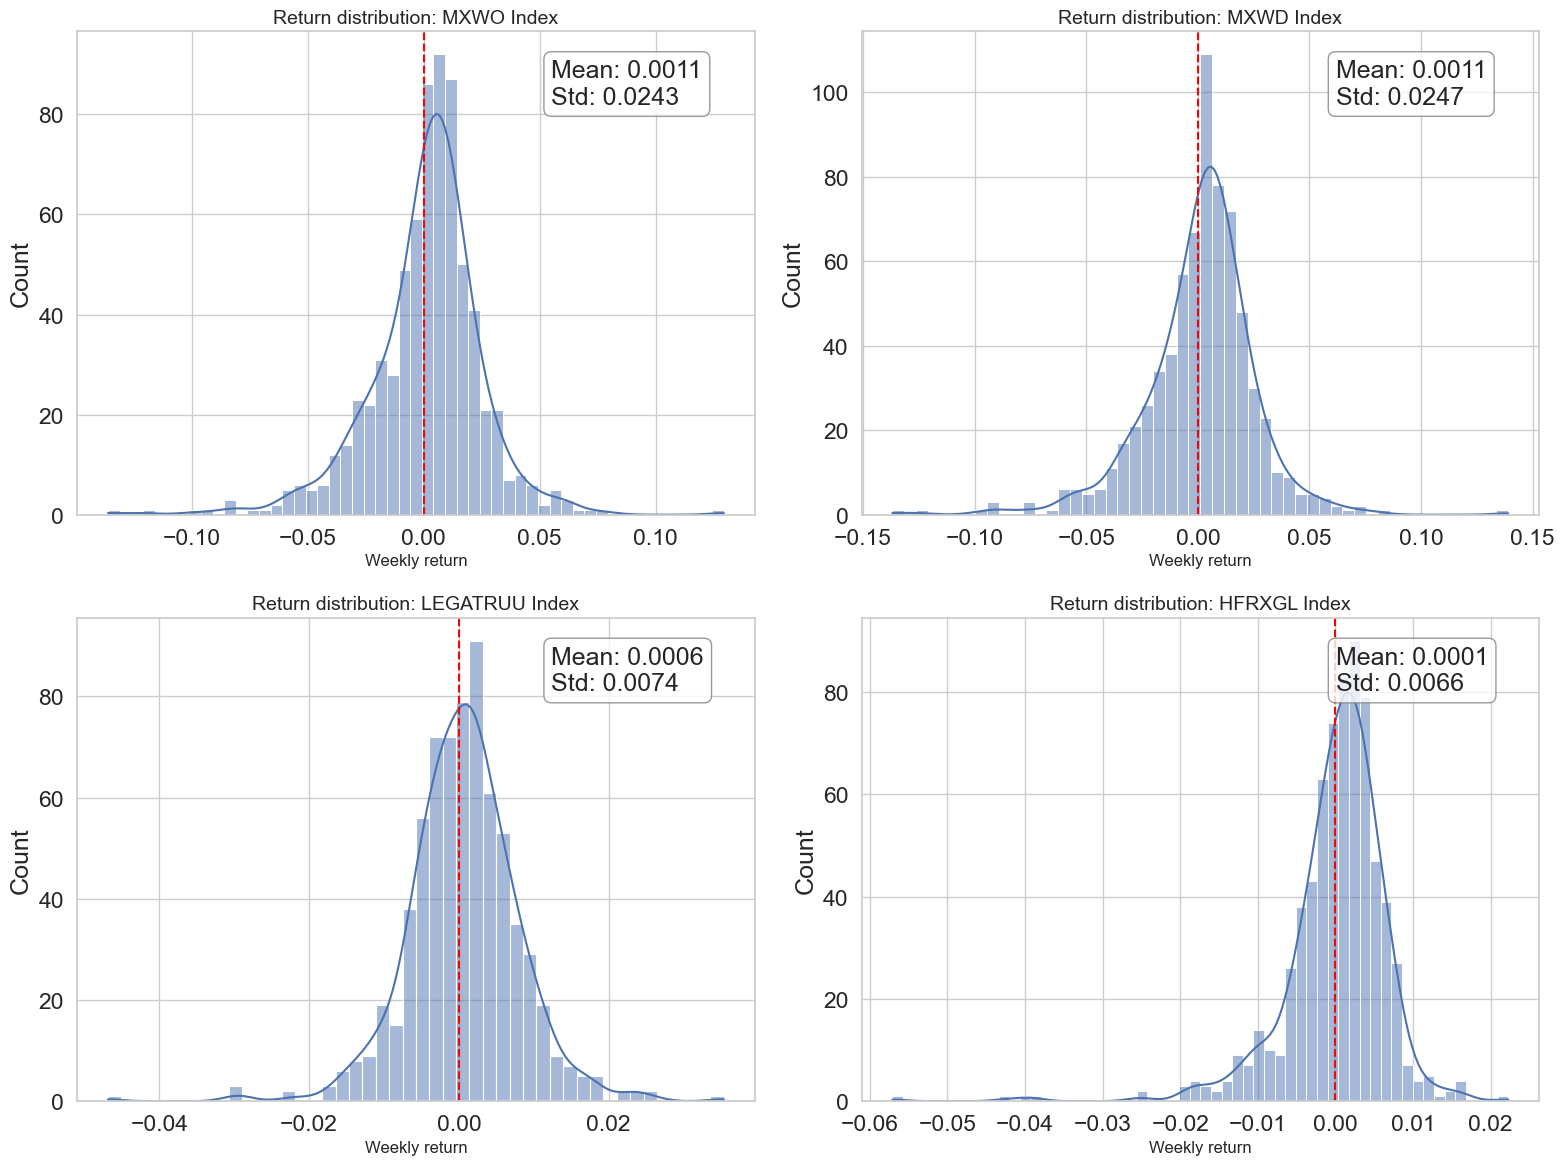

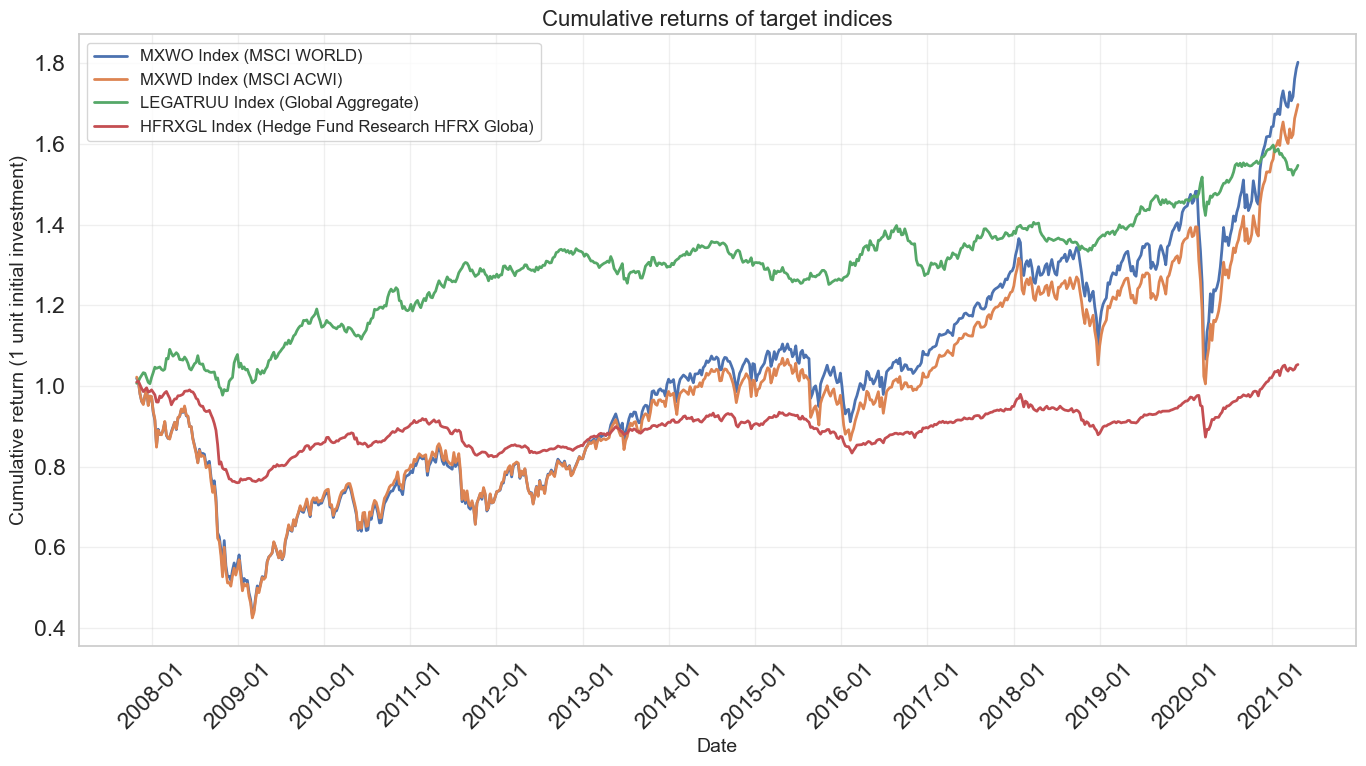

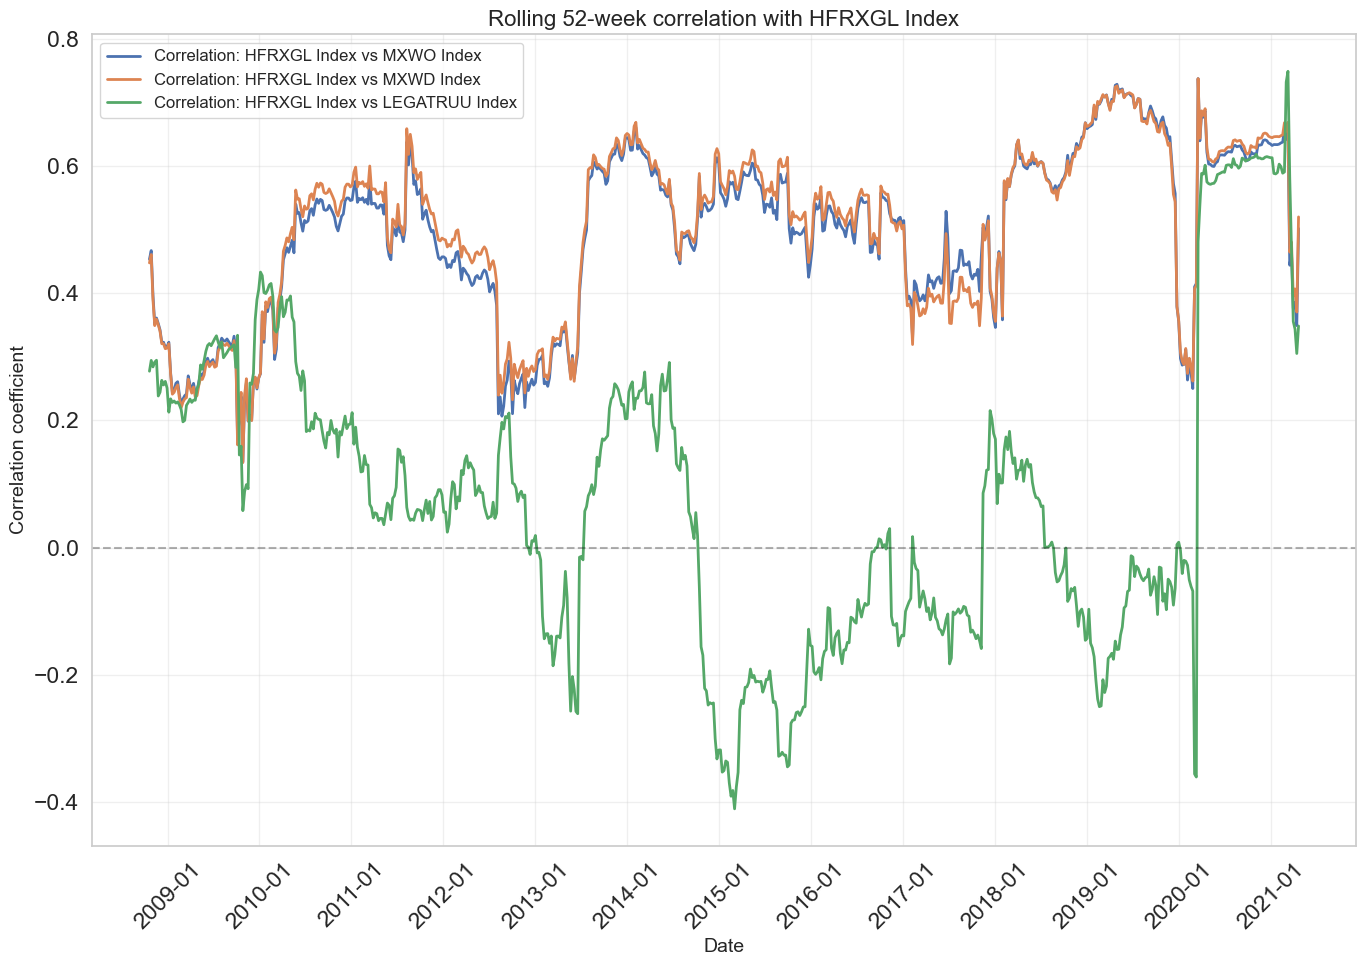

In [7]:


# Create a correlation heatmap for the target indices
plt.figure(figsize=(10, 8))
correlation_matrix = returns[target_indices].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, fmt='.2f')
plt.title('Correlation matrix of target indices returns', fontsize=16)
plt.tight_layout()
plt.show()

# Plot returns distribution
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, idx in enumerate(target_indices):
    sns.histplot(returns[idx], kde=True, ax=axes[i])
    axes[i].set_title(f'Return distribution: {idx}', fontsize=14)
    axes[i].set_xlabel('Weekly return', fontsize=12)
    axes[i].axvline(x=0, color='red', linestyle='--')
    # Add mean and std annotations
    mean = returns[idx].mean()
    std = returns[idx].std()
    axes[i].annotate(f'Mean: {mean:.4f}\nStd: {std:.4f}',
                     xy=(0.7, 0.85), xycoords='axes fraction',
                     bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

plt.tight_layout()
plt.show()

# Compute cumulative returns for visualization
cumulative_returns = (1 + returns).cumprod()

# Plot cumulative returns
plt.figure(figsize=(14, 8))
for idx in target_indices:
    plt.plot(cumulative_returns.index, cumulative_returns[idx], linewidth=2,
             label=f"{idx} ({variable_info.get(idx, idx)})")

plt.title('Cumulative returns of target indices', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Cumulative return (1 unit initial investment)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(loc='best', fontsize=12)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot rolling correlations over time (12-month window)
rolling_window = 52  # 52 weeks ≈ 1 year
plt.figure(figsize=(14, 10))

# Base correlation against HFRXGL (Hedge Fund Index)
base_idx = 'HFRXGL Index'
for idx in [i for i in target_indices if i != base_idx]:
    roll_corr = returns[[base_idx, idx]].rolling(rolling_window).corr().unstack()[base_idx][idx]
    plt.plot(roll_corr.index, roll_corr, linewidth=2,
             label=f"Correlation: {base_idx} vs {idx}")

plt.title(f'Rolling {rolling_window}-week correlation with {base_idx}', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Correlation coefficient', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(loc='best', fontsize=12)
plt.axhline(y=0, color='black', linestyle='--', alpha=0.3)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


<br>

Let's examine the statistical properties of our target indices.


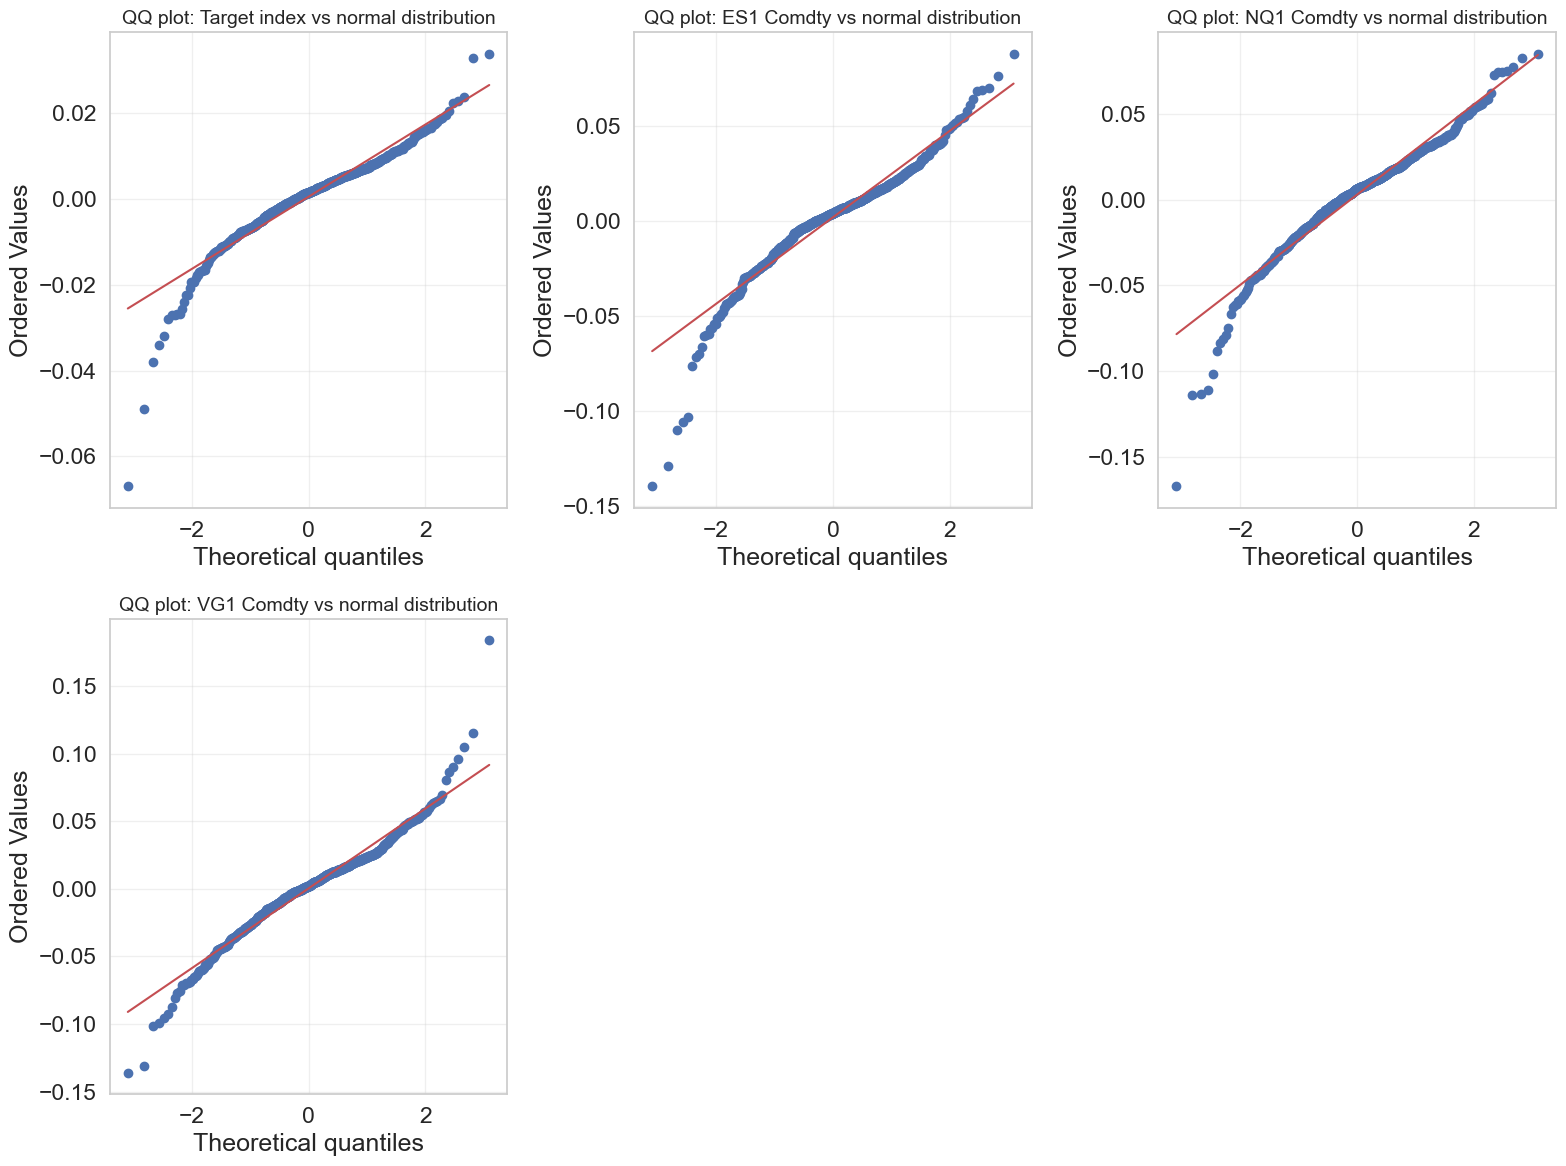

In [8]:
import scipy.stats as stats
from statsmodels.graphics.gofplots import qqplot
import warnings

# Some QQ plots for key variables


# Suppress specific boring RuntimeWarnings
warnings.filterwarnings("ignore", category=RuntimeWarning, message="invalid value encountered in divide")

# Define the components of our target index with their weights
# You can be creative, this is just an example
# Monster Index (a crazy combination of large indexes)
index_components = {
    'HFRXGL Index': 0.50,   # Hedge Fund Index - 50%
    'MXWO Index': 0.25,     # MSCI World - 25%
    'LEGATRUU Index': 0.25  # Global Aggregate Bond - 25%
}

# Calculate returns for each component
component_returns = data[list(index_components.keys())].pct_change().dropna()

# Create the target index using weighted returns
weighted_returns = pd.DataFrame(index=component_returns.index)
for component, weight in index_components.items():
    weighted_returns[component] = component_returns[component] * weight

# Sum the weighted returns to get the target index returns
target_returns = weighted_returns.sum(axis=1)
target_returns.name = 'Target_Index'

# Define the futures contracts we'll use for replication
futures_contracts = [
    'RX1 Comdty', 'TY1 Comdty', 'GC1 Comdty', 'CO1 Comdty',
    'ES1 Comdty', 'VG1 Comdty', 'NQ1 Comdty', 'LLL1 Comdty',
    'TP1 Comdty', 'DU1 Comdty', 'TU2 Comdty'
]

# Calculate returns for futures contracts
futures_returns = data[futures_contracts].pct_change().dropna()

# Ensure we're using the same date range for both target and futures
common_dates = futures_returns.index.intersection(target_returns.index)
futures_returns = futures_returns.loc[common_dates]
target_returns_aligned = target_returns.loc[common_dates]

# Calculate correlations between target index and futures contracts using pandas method
# which handles NaN values better than np.corrcoef
correlations = pd.DataFrame(index=futures_contracts,
                           columns=['Correlation with target index'])

for contract in futures_contracts:
    correlations.loc[contract] = target_returns_aligned.corr(futures_returns[contract])

# Sort by absolute correlation value
correlations['Abs correlation'] = correlations['Correlation with target index'].abs()
correlations = correlations.sort_values('Abs correlation', ascending=False)
correlations = correlations.drop('Abs correlation', axis=1)

# Now create the QQ plots
plt.figure(figsize=(16, 12))

# Plot QQ plot for the target index
plt.subplot(2, 3, 1)
stats.probplot(target_returns_aligned.dropna(), dist="norm", plot=plt)
plt.title(f'QQ plot: Target index vs normal distribution', fontsize=14)
plt.grid(True, alpha=0.3)

# Select a few key futures contracts (top 3 by correlation with target)
top_futures = correlations.index[:3].tolist()

# Create QQ plots for top futures
for i, contract in enumerate(top_futures):
    plt.subplot(2, 3, i+2)

    # Get returns data for this contract
    returns_data = futures_returns[contract].dropna()

    # Create QQ plot
    stats.probplot(returns_data, dist="norm", plot=plt)

    # Add title and improve appearance
    plt.title(f'QQ plot: {contract} vs normal distribution', fontsize=14)
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



In [9]:
# Print the top correlated futures, just for reference
print("Top futures contracts by correlation with target index:")
display(correlations.head())

Top futures contracts by correlation with target index:


,Correlation with target index
ES1 Comdty,0.837925
NQ1 Comdty,0.746908
VG1 Comdty,0.730608
LLL1 Comdty,0.695488
TP1 Comdty,0.598764


<br>

We'll analyze the **autocorrelation** properties of our target indices to understand their time series behavior. It is possible to take this into account in modelling, and in any case it is better to know what the situation is.

<br>

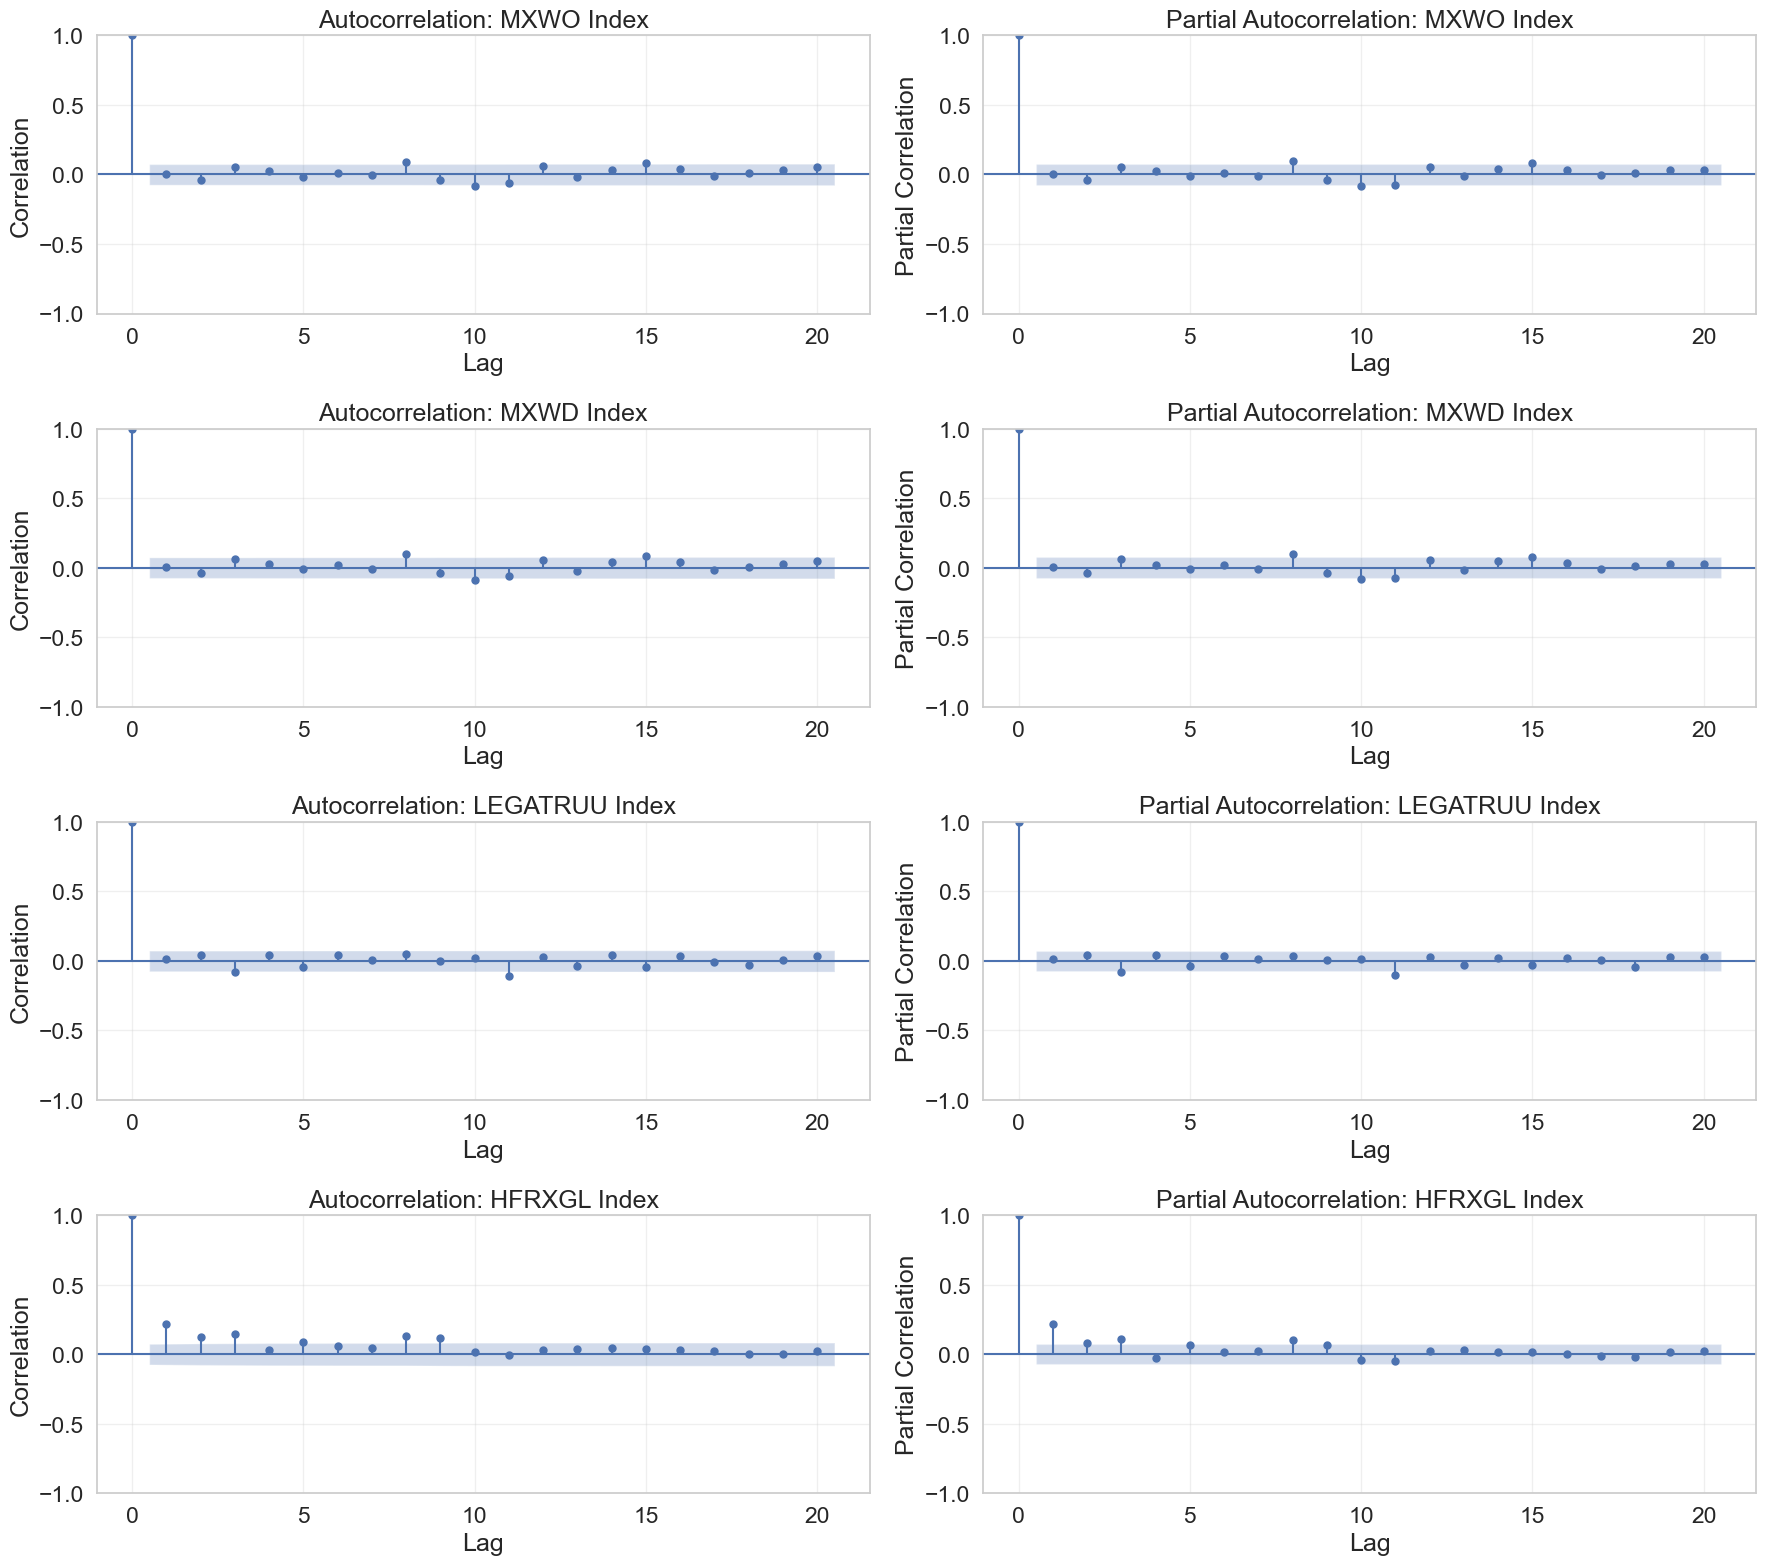

In [10]:
# Autocorrelation and Partial Autocorrelation analysis
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Define the maximum number of lags to analyze
max_lags = 20

# Create a figure for ACF and PACF plots
fig, axes = plt.subplots(len(target_indices), 2, figsize=(18, 4*len(target_indices)))

# For each target index
for i, idx in enumerate(target_indices):
    # Get returns data for this index
    returns_data = returns[idx].dropna()

    # Plot ACF (Autocorrelation Function)
    plot_acf(returns_data,
             lags=max_lags,
             ax=axes[i, 0],
             title=f'Autocorrelation: {idx}',
             alpha=0.05)  # 95% confidence intervals

    axes[i, 0].set_xlabel('Lag')
    axes[i, 0].set_ylabel('Correlation')
    axes[i, 0].grid(True, alpha=0.3)

    # Plot PACF (Partial Autocorrelation Function)
    plot_pacf(returns_data,
              lags=max_lags,
              ax=axes[i, 1],
              title=f'Partial Autocorrelation: {idx}',
              alpha=0.05)  # 95% confidence intervals

    axes[i, 1].set_xlabel('Lag')
    axes[i, 1].set_ylabel('Partial Correlation')
    axes[i, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Some **statistical tests for Autocorrelation**:
Let's perform formal statistical tests to check for autocorrelation in our return series.

In [11]:
from statsmodels.stats.diagnostic import acorr_ljungbox
# Ljung-Box test for autocorrelation

print("\nLjung-Box test for Autocorrelation (H0: No autocorrelation)")
for idx in target_indices:
    # Get returns data for this index
    returns_data = returns[idx].dropna()

    # Perform Ljung-Box test for different lags
    lb_test = acorr_ljungbox(returns_data, lags=[5, 10, 15, 20])

    print(f"\n{idx}:")
    print(f"  Lag 5:  Test Statistic = {lb_test.iloc[0, 0]:.4f}, p-value = {lb_test.iloc[0, 1]:.4f}")
    print(f"  Lag 10: Test Statistic = {lb_test.iloc[1, 0]:.4f}, p-value = {lb_test.iloc[1, 1]:.4f}")
    print(f"  Lag 15: Test Statistic = {lb_test.iloc[2, 0]:.4f}, p-value = {lb_test.iloc[2, 1]:.4f}")
    print(f"  Lag 20: Test Statistic = {lb_test.iloc[3, 0]:.4f}, p-value = {lb_test.iloc[3, 1]:.4f}")



Ljung-Box test for Autocorrelation (H0: No autocorrelation)

MXWO Index:
  Lag 5:  Test Statistic = 3.7194, p-value = 0.5905
  Lag 10: Test Statistic = 16.3144, p-value = 0.0910
  Lag 15: Test Statistic = 27.3792, p-value = 0.0258
  Lag 20: Test Statistic = 31.2372, p-value = 0.0521

MXWD Index:
  Lag 5:  Test Statistic = 4.0704, p-value = 0.5393
  Lag 10: Test Statistic = 17.4323, p-value = 0.0653
  Lag 15: Test Statistic = 28.4624, p-value = 0.0188
  Lag 20: Test Statistic = 32.0118, p-value = 0.0432

LEGATRUU Index:
  Lag 5:  Test Statistic = 8.3823, p-value = 0.1364
  Lag 10: Test Statistic = 11.6799, p-value = 0.3071
  Lag 15: Test Statistic = 23.8265, p-value = 0.0681
  Lag 20: Test Statistic = 26.5486, p-value = 0.1484

HFRXGL Index:
  Lag 5:  Test Statistic = 63.9540, p-value = 0.0000
  Lag 10: Test Statistic = 90.7371, p-value = 0.0000
  Lag 15: Test Statistic = 94.7913, p-value = 0.0000
  Lag 20: Test Statistic = 96.3138, p-value = 0.0000


<br>

**Volatility Clustering Analysis**: Financial returns often exhibit volatility clustering - periods of high volatility tend to be followed by similar high volatility periods. We'll examine this phenomenon: as before, it is possible to take this into account in the modelling, and in any case it is better to know what the situation is.

<br>

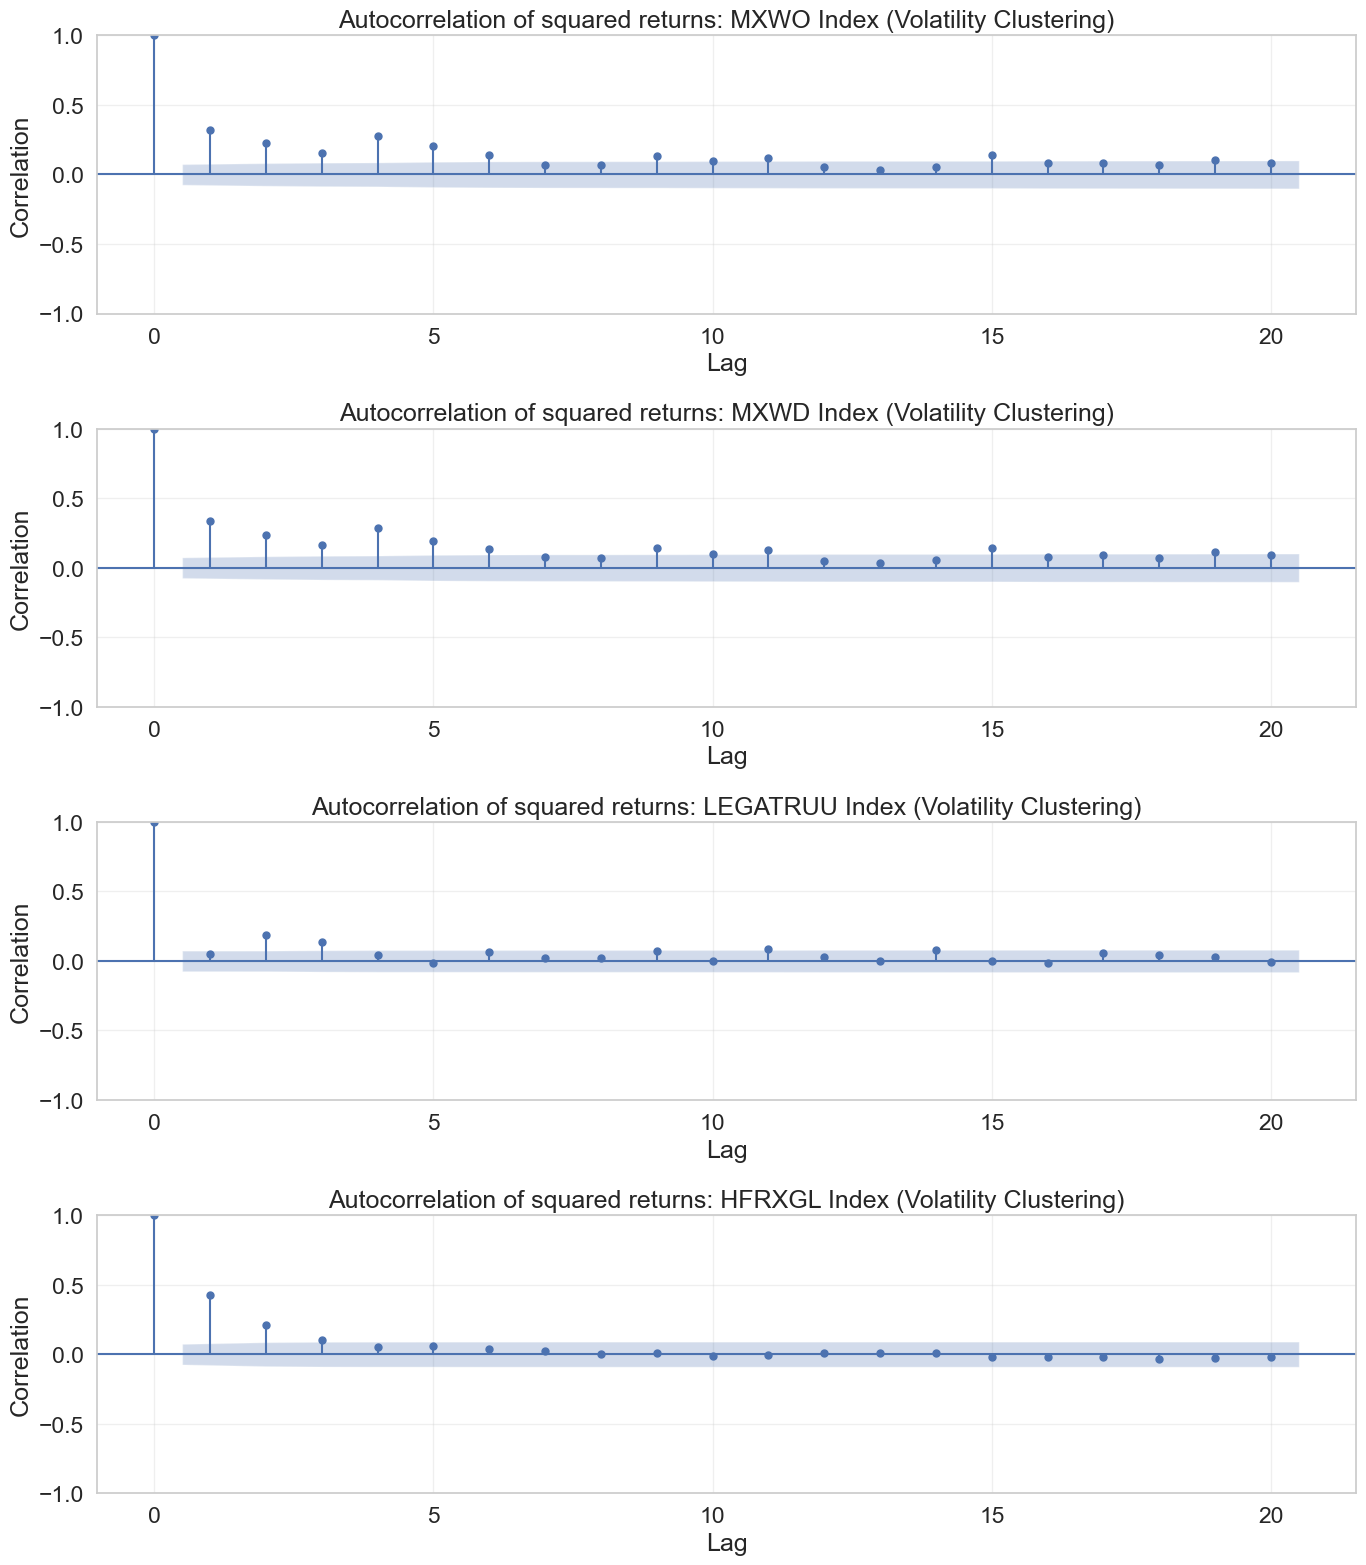

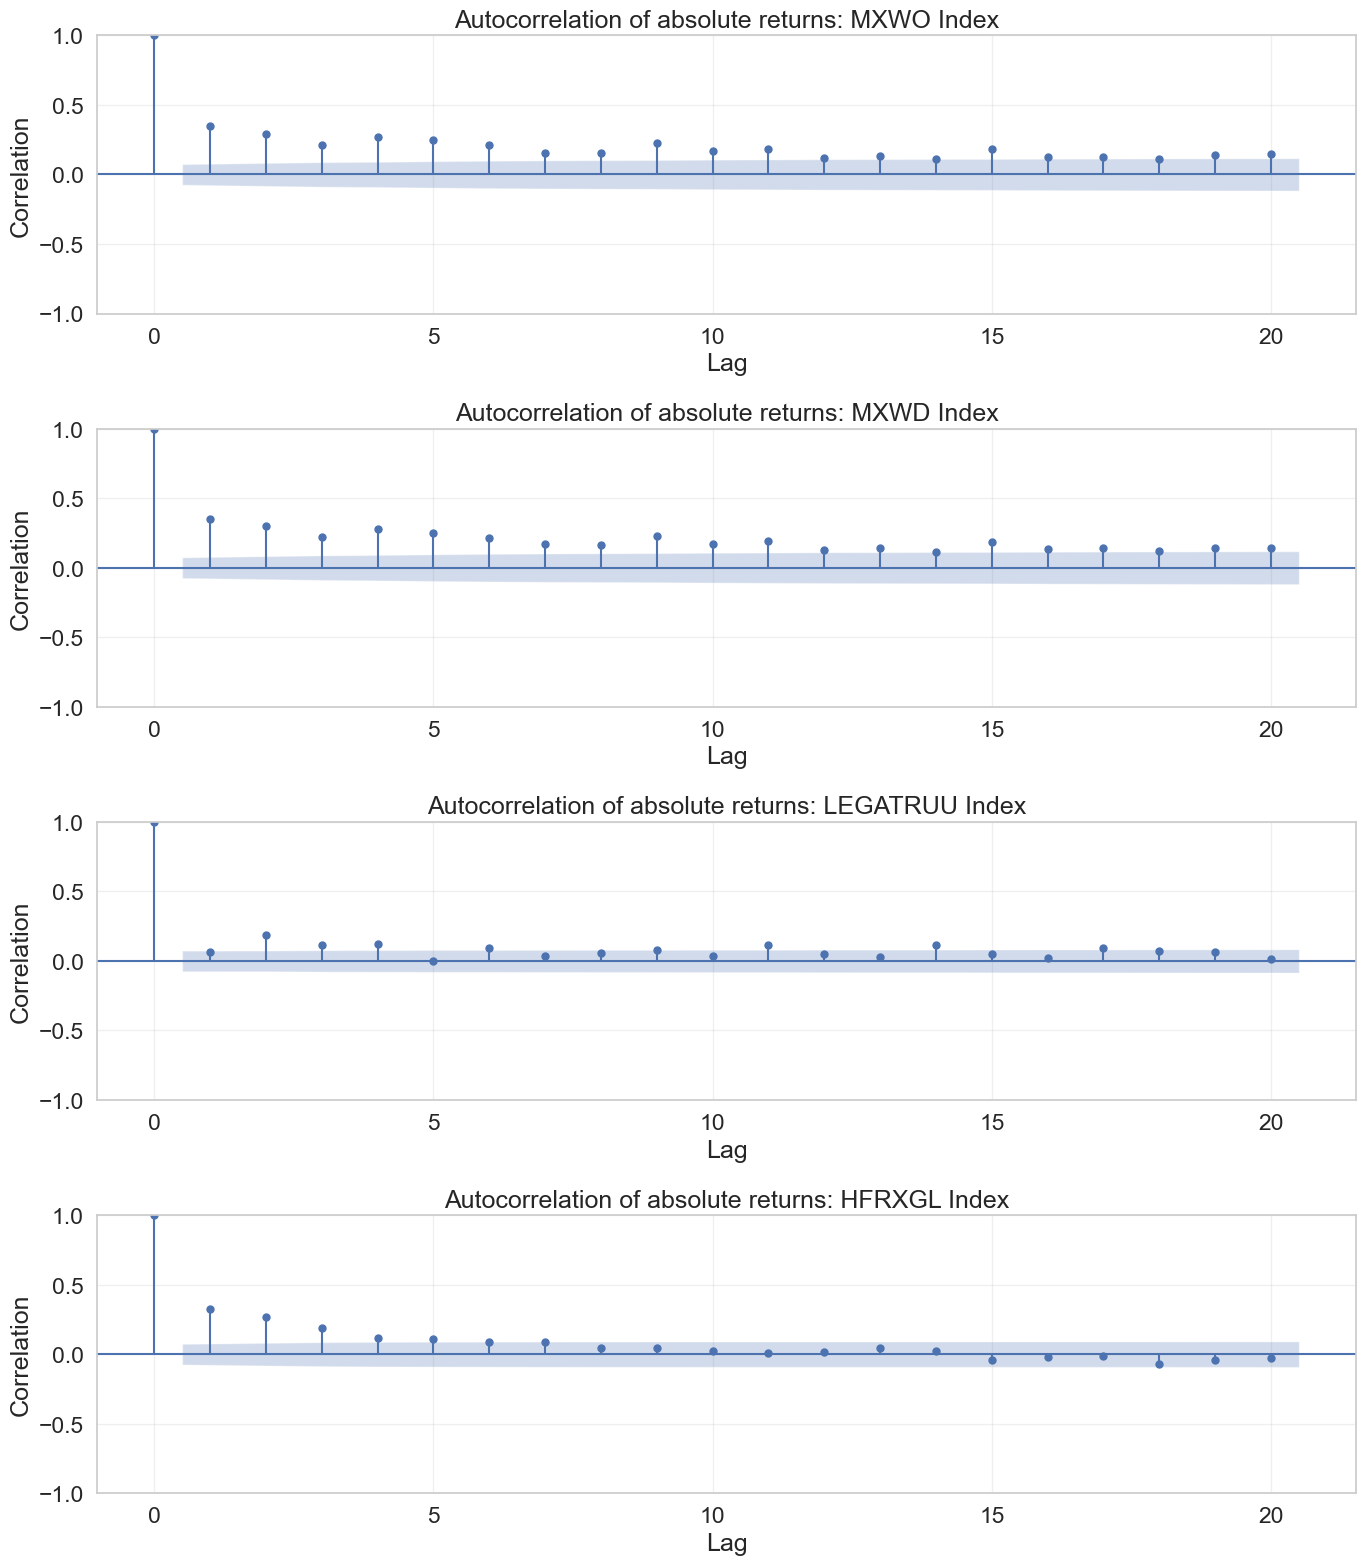

In [12]:
# Create a figure for squared returns ACF (volatility clustering)
fig, axes = plt.subplots(len(target_indices), 1, figsize=(14, 4*len(target_indices)))

# For each target index
for i, idx in enumerate(target_indices):
    # Get squared returns data for this index (for volatility clustering, ie GARC-like situations)
    squared_returns = returns[idx].dropna() ** 2

    # Plot ACF of squared returns
    plot_acf(squared_returns,
             lags=max_lags,
             ax=axes[i] if len(target_indices) > 1 else axes,
             title=f'Autocorrelation of squared returns: {idx} (Volatility Clustering)',
             alpha=0.05)  # 95% confidence intervals

    if len(target_indices) > 1:
        axes[i].set_xlabel('Lag')
        axes[i].set_ylabel('Correlation')
        axes[i].grid(True, alpha=0.3)
    else:
        axes.set_xlabel('Lag')
        axes.set_ylabel('Correlation')
        axes.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Create a figure for absolute returns ACF (another measure of volatility clustering)
fig, axes = plt.subplots(len(target_indices), 1, figsize=(14, 4*len(target_indices)))

# For each target index
for i, idx in enumerate(target_indices):
    # Get absolute returns data for this index
    abs_returns = abs(returns[idx].dropna())

    # Plot ACF of absolute returns
    plot_acf(abs_returns,
             lags=max_lags,
             ax=axes[i] if len(target_indices) > 1 else axes,
             title=f'Autocorrelation of absolute returns: {idx}',
             alpha=0.05)  # 95% confidence intervals

    if len(target_indices) > 1:
        axes[i].set_xlabel('Lag')
        axes[i].set_ylabel('Correlation')
        axes[i].grid(True, alpha=0.3)
    else:
        axes.set_xlabel('Lag')
        axes.set_ylabel('Correlation')
        axes.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


<br>

Now let's analyze our constructed target index, the Monster Index, and Futures contracts that are candidates to replicate it in more detail to understand its characteristics before attempting replication.

<br>

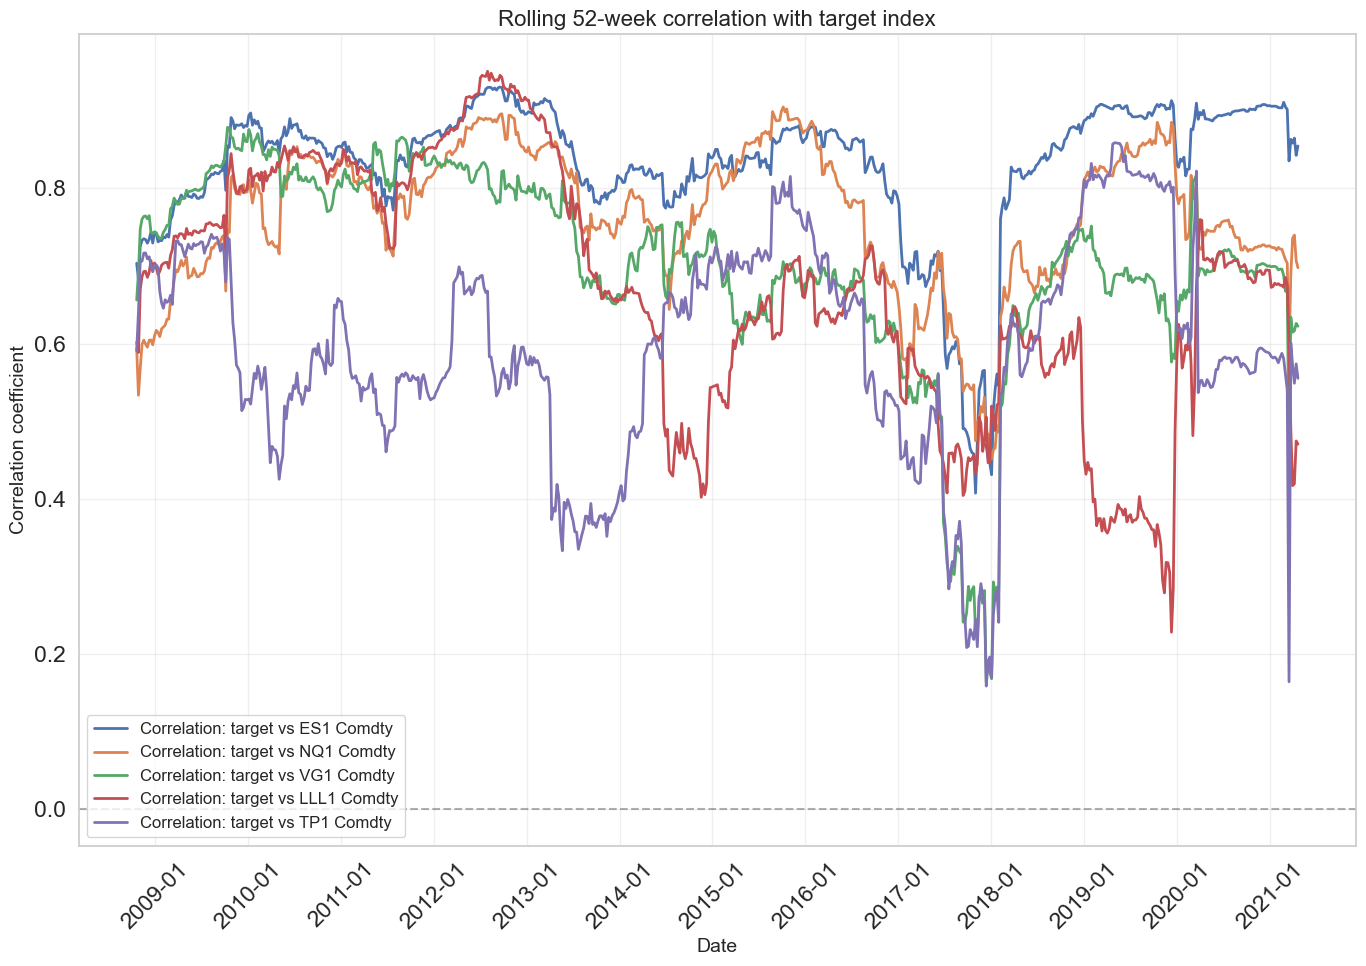

In [13]:
# Plot rolling correlations between target index and Futures contracts
rolling_window = 52  # 52 weeks ≈ 1 year
plt.figure(figsize=(14, 10))

# Select top 5 futures by correlation (absolute value)
top_futures = correlations.index[:5].tolist()

for contract in top_futures:
    # Calculate rolling correlation
    combined_df = pd.DataFrame({
        'Target': target_returns_aligned,  # Fixed variable name
        'Future': futures_returns[contract]
    })
    rolling_corr = combined_df['Target'].rolling(rolling_window).corr(combined_df['Future'])

    # Plot
    plt.plot(rolling_corr.index, rolling_corr, linewidth=2,
             label=f"Correlation: target vs {contract}")

plt.title(f'Rolling {rolling_window}-week correlation with target index', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Correlation coefficient', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(loc='best', fontsize=12)
plt.axhline(y=0, color='black', linestyle='--', alpha=0.3)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


If you look at the time series and their correlations with the target, they have heterogeneous paths, so it's intuitive that they can be of help, if we want to replicate complex assets, such as our "Monster Index".

In [14]:
# Calculate and display target index statistics
print("\nTarget index statistics:")
annual_factor = 52  # For weekly data

# Calculate statistics
mean_return = target_returns_aligned.mean() * annual_factor
volatility = target_returns_aligned.std() * np.sqrt(annual_factor)
sharpe_ratio = mean_return / volatility
cumulative_returns = (1 + target_returns_aligned).cumprod()
drawdowns = 1 - cumulative_returns / cumulative_returns.cummax()
max_drawdown = drawdowns.max()
skewness = target_returns_aligned.skew()
kurtosis = target_returns_aligned.kurtosis()

# Display statistics
stats_df = pd.DataFrame({
    'Statistic': ['Annualized return', 'Annualized volatility', 'Sharpe ratio',
                  'Max Drawdown', 'Skewness', 'Kurtosis'],
    'Value': [f"{mean_return*100:.2f}%",
              f"{volatility*100:.2f}%",
              f"{sharpe_ratio:.2f}",
              f"{max_drawdown*100:.2f}%",
              f"{skewness:.2f}",
              f"{kurtosis:.2f}"]
})

display(stats_df)

# Also calculate and display monthly returns statistics
if len(target_returns_aligned) >= 12:  # Ensure we have enough data
    # Resample to monthly returns using 'ME' (month end) frequency - more robust
    monthly_returns = target_returns_aligned.resample('ME').apply(
        lambda x: (1 + x).prod() - 1)

    # Calculate monthly statistics
    monthly_mean = monthly_returns.mean() * 12
    monthly_vol = monthly_returns.std() * np.sqrt(12)
    monthly_sharpe = monthly_mean / monthly_vol if monthly_vol > 0 else 0

    # Display monthly statistics
    print("\nMonthly return statistics:")
    monthly_stats = pd.DataFrame({
        'Statistic': ['Annualized return (monthly)',
                     'Annualized volatility (monthly)',
                     'Sharpe ratio (monthly)'],
        'Value': [f"{monthly_mean*100:.2f}%",
                 f"{monthly_vol*100:.2f}%",
                 f"{monthly_sharpe:.2f}"]
    })

    display(monthly_stats)



Target index statistics:


,Statistic,Value
0,Annualized return,2.57%
1,Annualized volatility,6.33%
2,Sharpe ratio,0.41
3,Max Drawdown,29.01%
4,Skewness,-1.35
5,Kurtosis,7.64



Monthly return statistics:


,Statistic,Value
0,Annualized return (monthly),2.65%
1,Annualized volatility (monthly),7.55%
2,Sharpe ratio (monthly),0.35


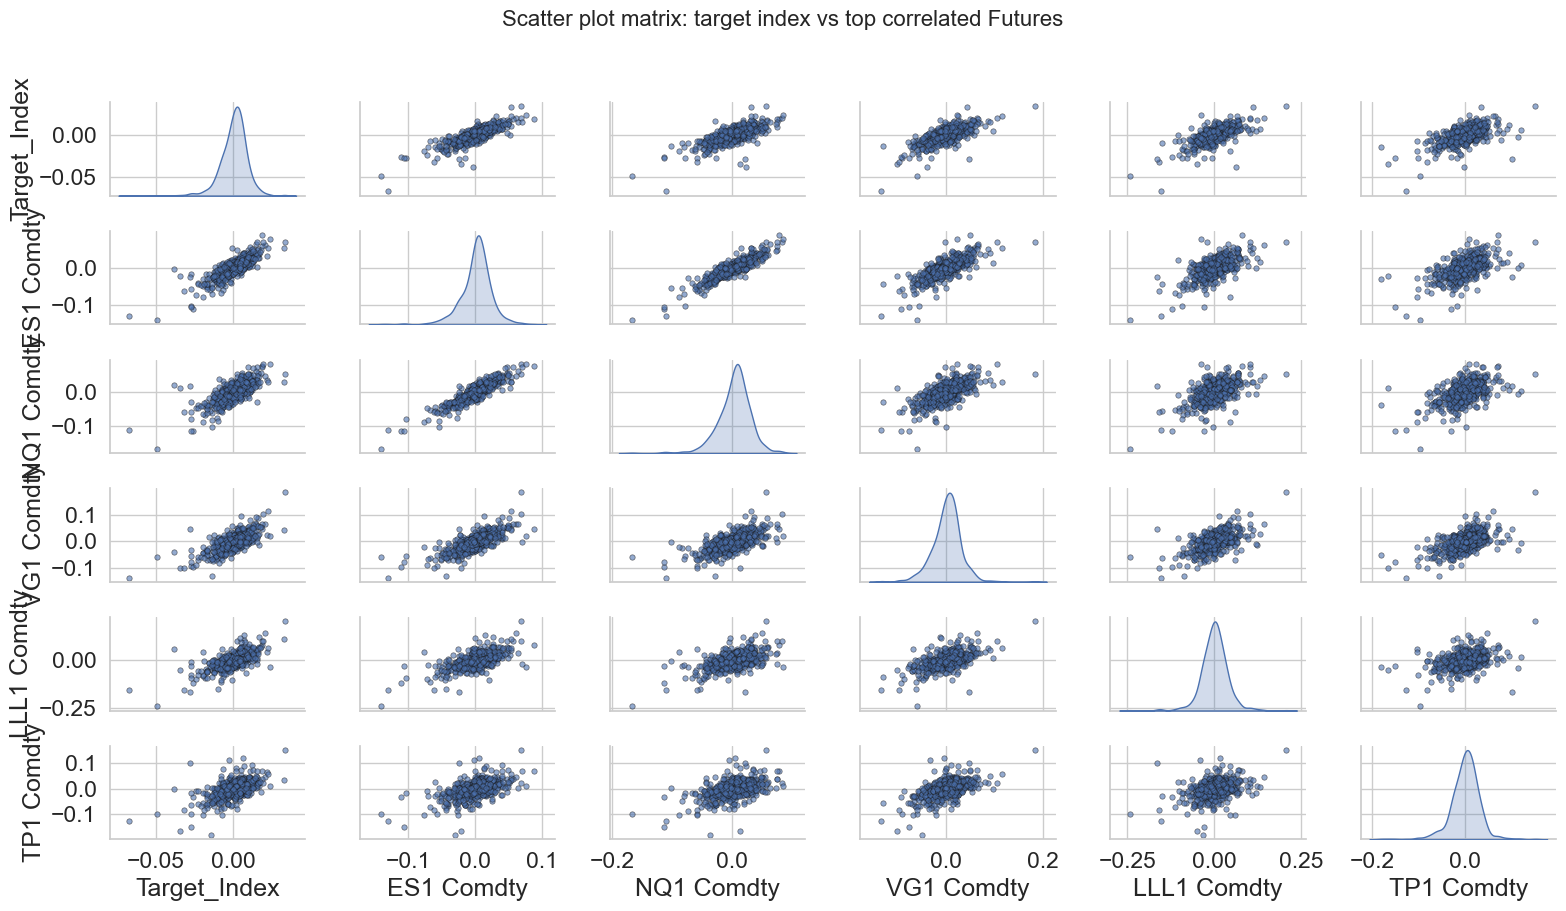

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Combine target index and top correlated futures into one DataFrame
top_futures_plus_target = ['Target_Index'] + top_futures
scatter_data = pd.concat([target_returns_aligned.rename('Target_Index'),
                          futures_returns[top_futures]], axis=1)

# Create the pair plot
g = sns.pairplot(scatter_data, kind='scatter', diag_kind='kde',
                 plot_kws={'alpha': 0.6, 's': 15, 'edgecolor': 'k', 'linewidth': 0.5})

# Set figure size to 16:9 aspect ratio
g.fig.set_size_inches(16, 9)

# Add title and adjust layout
g.fig.suptitle('Scatter plot matrix: target index vs top correlated Futures',
               fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


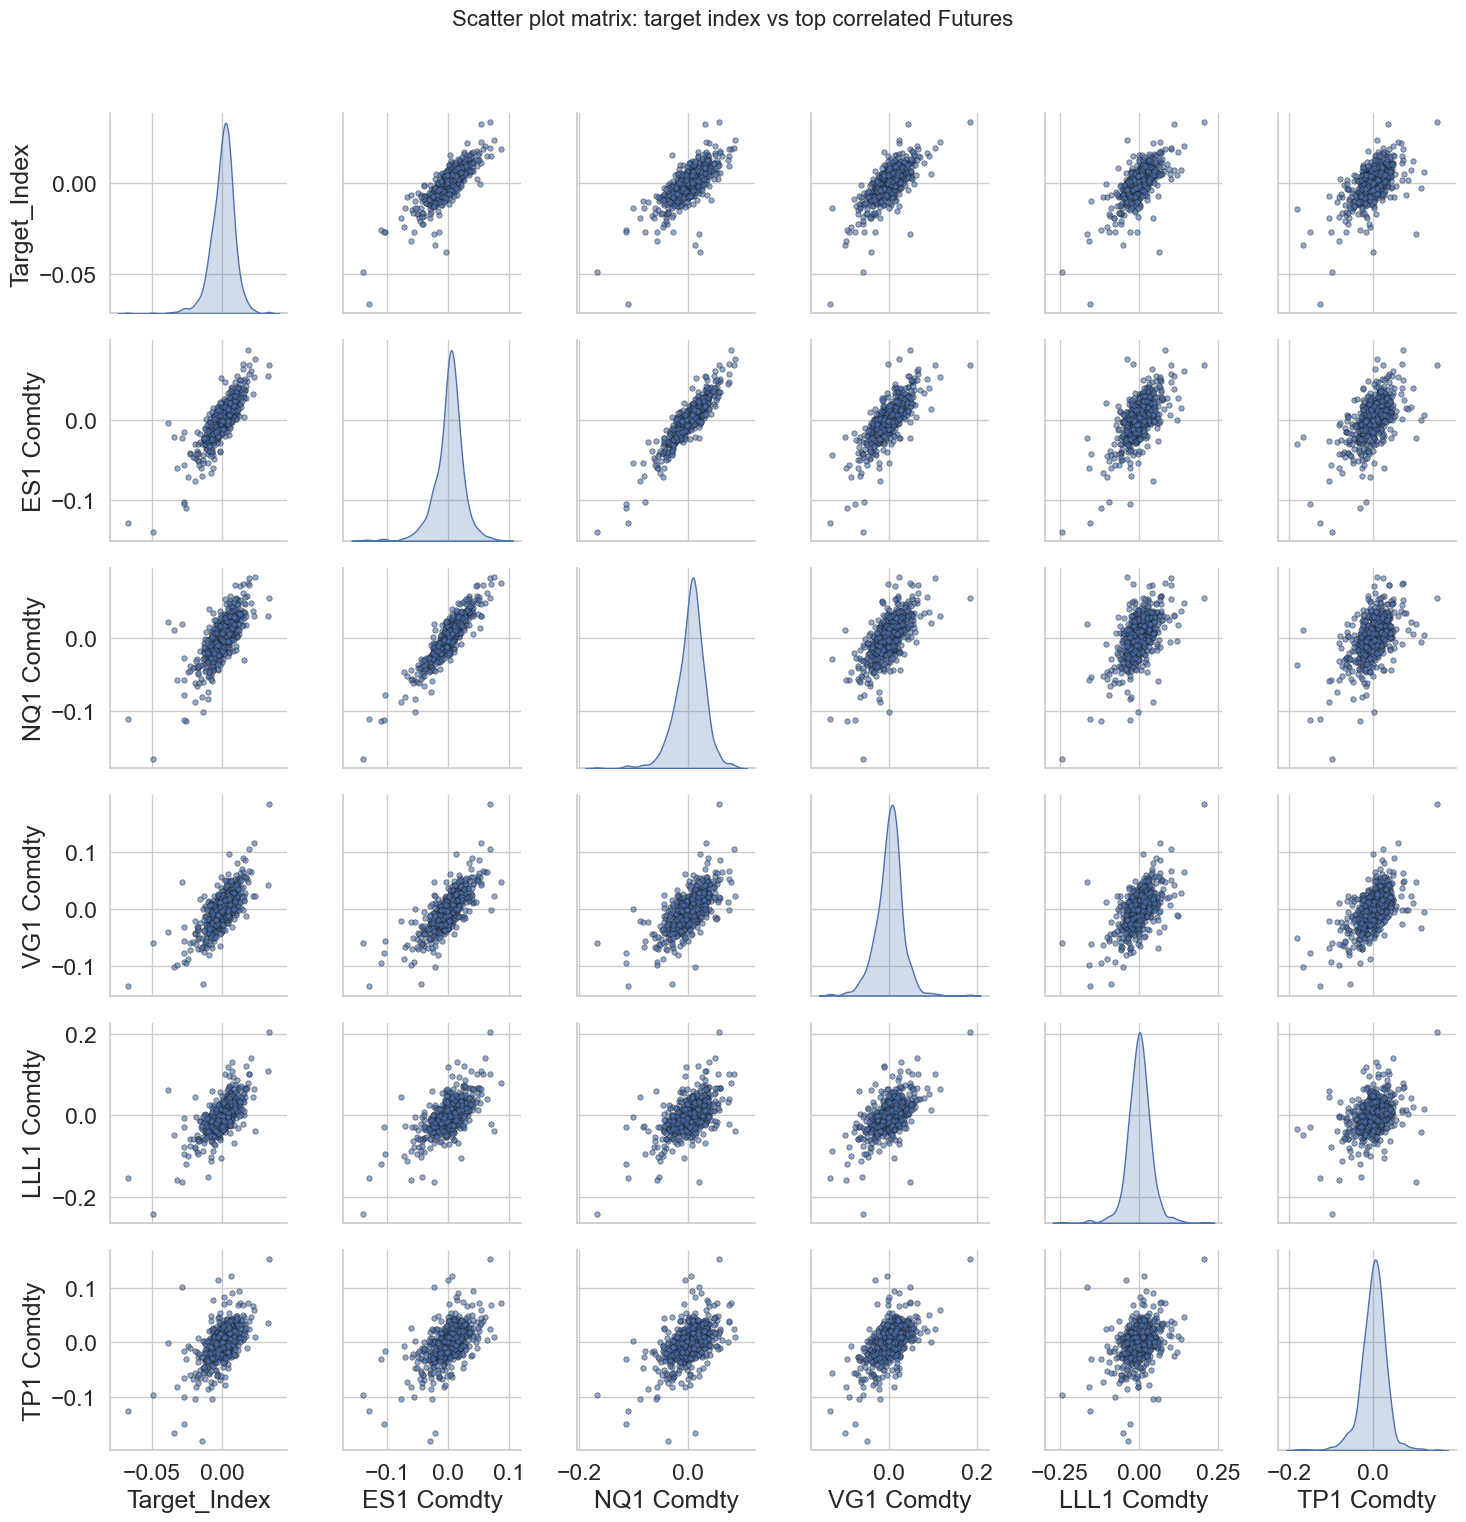

In [16]:
# Create a scatter plot matrix for the target index and top correlated futures
top_futures_plus_target = ['Target_Index'] + top_futures
scatter_data = pd.concat([target_returns_aligned.rename('Target_Index'),
                          futures_returns[top_futures]], axis=1)

# Create a pair plot
sns.pairplot(scatter_data, kind='scatter', diag_kind='kde',
             plot_kws={'alpha': 0.6, 's': 15, 'edgecolor': 'k', 'linewidth': 0.5})
plt.suptitle('Scatter plot matrix: target index vs top correlated Futures',
             fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


# ANOMALY DETECTION

In [17]:
def detect_crashes(cumulative_returns, window=5, threshold=0.02):
    """
    Identifies crashes in cumulative returns by comparing the average of past values with that of future values.

    Parameters:
    - cumulative_returns: pd.Series with time-indexed cumulative returns.
    - window: int, number of periods to consider for past and future averages.
    - threshold: float, percentage threshold to identify a crash.

    Returns:
    - crash_labels: pd.Series of 0s and 1s, where 1 indicates a crash.
    """
    # Compute past and future averages
    past_mean = cumulative_returns.shift(1).rolling(window=window).mean()
    future_mean = cumulative_returns.shift(-window).rolling(window=window).mean()

    # Crash identification
    crash_labels = ((past_mean - future_mean) > (past_mean * threshold)).astype(int)

    # Handling NaN values
    crash_labels = crash_labels.fillna(0)

    return crash_labels


In [18]:
crash_labels = detect_crashes(cumulative_returns, window=5, threshold=0.02)

# Visualize first 10 results
print(crash_labels.head(10))

Date
2007-10-30    0
2007-11-06    0
2007-11-13    0
2007-11-20    0
2007-11-27    0
2007-12-04    0
2007-12-11    0
2007-12-18    0
2007-12-25    0
2008-01-01    1
Name: Target_Index, dtype: int64


In [19]:
np.sum(crash_labels==1)+np.sum(crash_labels==0)

np.int64(704)

In [20]:

crash_labels.name = "Crash"

crash_labels.to_csv("crash_labels.csv", header=True)


In [21]:
crash_df = pd.read_csv("crash_labels.csv")
crash_df['Date'] = pd.to_datetime(crash_df['Date'])

In [22]:

data_df = data.merge(crash_df, on='Date', how='left')
data_df['Crash'].fillna(0, inplace=True) 

# Set time index
data_df = data_df.set_index('Date')


C:\Users\Francesco\AppData\Local\Temp\ipykernel_34296\2584385225.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data_df['Crash'].fillna(0, inplace=True)


Data shape: (705, 15)
Time period: from 2007-10-23 to 2021-04-20
Number of variables: 15
Number of crash periods: 81 (11.49%)


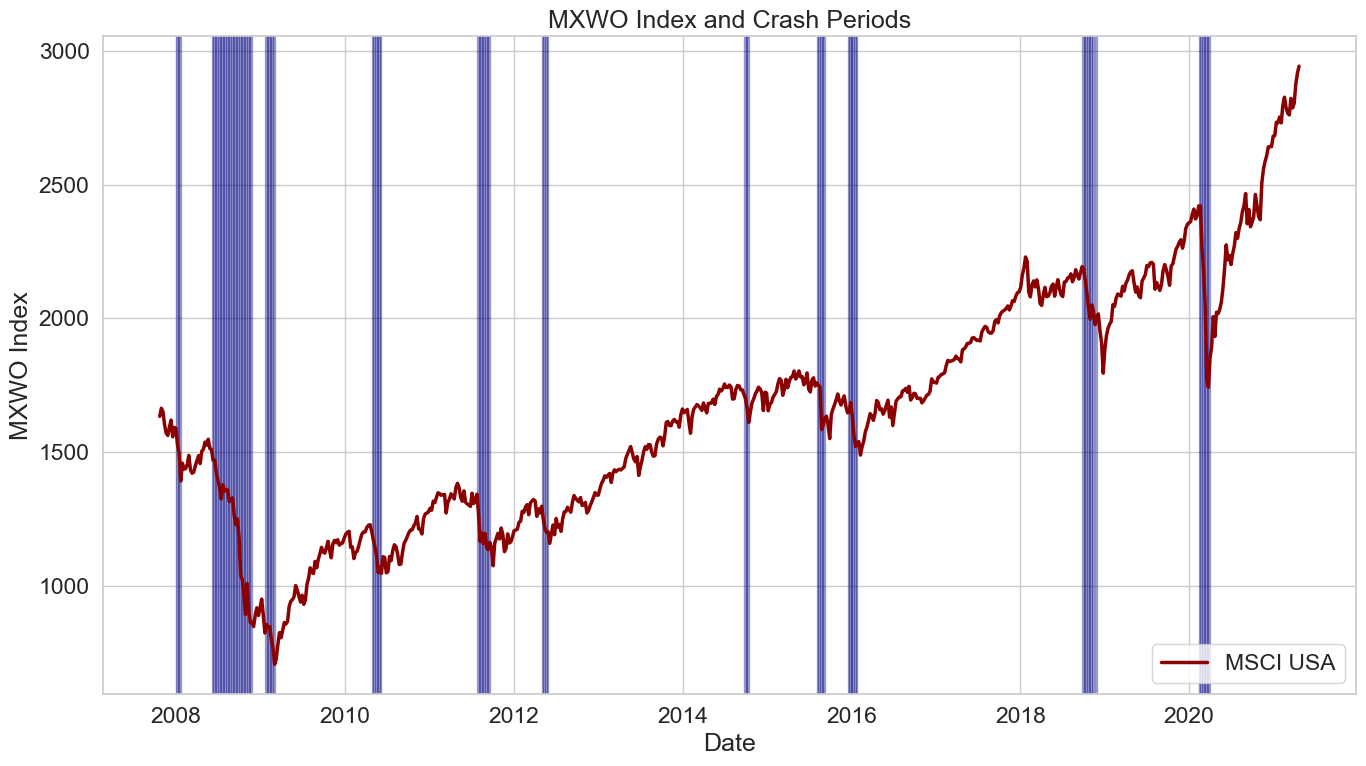

In [23]:
# Split X and y
X_df = data_df.drop('Crash', axis=1)
y = data_df['Crash'].values

# Base info
print(f"Data shape: {X_df.shape}")
print(f"Time period: from {X_df.index.min().date()} to {X_df.index.max().date()}")
print(f"Number of variables: {X_df.shape[1]}")
print(f"Number of crash periods: {np.sum(y == 1)} ({np.mean(y == 1) * 100:.2f}%)")

# Plot: MXUS + Crash
if 'MXWO Index' in X_df.columns:
    fig, ax = plt.subplots(figsize=(14, 8))

    ax.plot(X_df.index, X_df['MXWO Index'], color='darkred', linewidth=2.5, label='MSCI USA')
    y_min, y_max = ax.get_ylim()

    for i, (date, is_crash) in enumerate(zip(X_df.index, y)):
        if is_crash == 1:
            ax.axvspan(date, date + pd.Timedelta(days=7), alpha=0.3, color='navy', label='Crash' if i == 0 else "")

    ax.set_xlabel('Date')
    ax.set_ylabel('MXWO Index')
    ax.set_title('MXWO Index and Crash Periods')

    # Legend
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='best')

    plt.tight_layout()
    plt.show()
else:
    print("La colonna 'MXWO Index' non è presente nel file di dati.")

# REGRESSION MODEL

In [24]:
# Ensure data is properly aligned
Y = target_returns_aligned  # Target index returns
C = futures_returns.loc[Y.index]  # Futures returns aligned with target

# Data dimension
T = Y.shape[0]
N = C.shape[1]

## BASELINE MODEL

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge

# Fit modello
model = LinearRegression().fit(C.values, Y.values.ravel())

weights_baseline = pd.Series(model.coef_, index=C.columns, name="weight")
weights_baseline_df = pd.DataFrame(
    [weights_baseline.values] * len(Y),  
    index=Y.index,                       
    columns=weights_baseline.index      
)
# Previsione
y_pred_baseline = model.predict(C.values)

# DataFrame risultato
Y_pred_baseline = pd.DataFrame(y_pred_baseline, index=Y.index, columns=['baseline_prediction'])

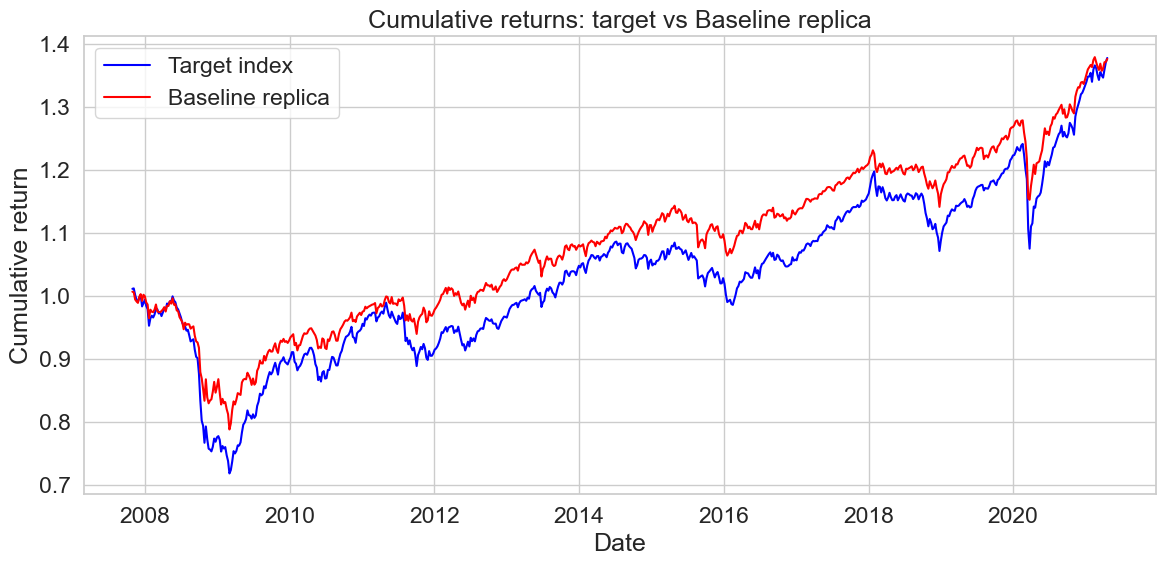

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

In [26]:
baseline_returns = (weights_baseline_df * C).sum(axis=1)
cumulative_target = (1 + Y).cumprod()
cumulative_baseline = (1 + baseline_returns).cumprod()
plt.figure(figsize=(12, 6))
plt.plot(cumulative_target, label='Target index', color='blue')
plt.plot(cumulative_baseline, label='Baseline replica', color='red')
plt.title('Cumulative returns: target vs Baseline replica')
plt.xlabel('Date')
plt.ylabel('Cumulative return')
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()
plt.figure(figsize=(12, 6))


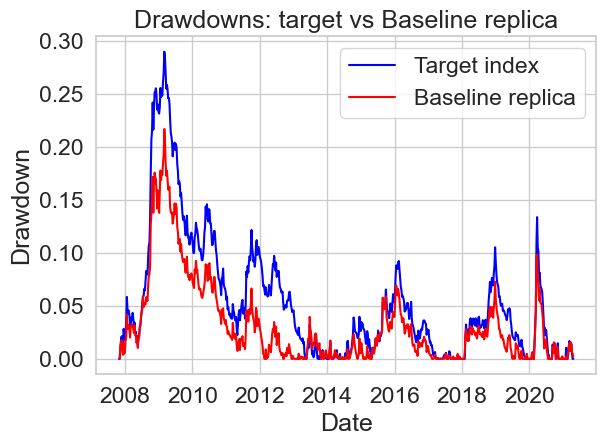

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

In [27]:
target_drawdown = 1 - cumulative_target / cumulative_target.cummax()
baseline_drawdown = 1 - cumulative_baseline / cumulative_baseline.cummax()
plt.plot(target_drawdown, label='Target index', color='blue')
plt.plot(baseline_drawdown, label='Baseline replica', color='red')
plt.title('Drawdowns: target vs Baseline replica')
plt.xlabel('Date')
plt.ylabel('Drawdown')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 6))


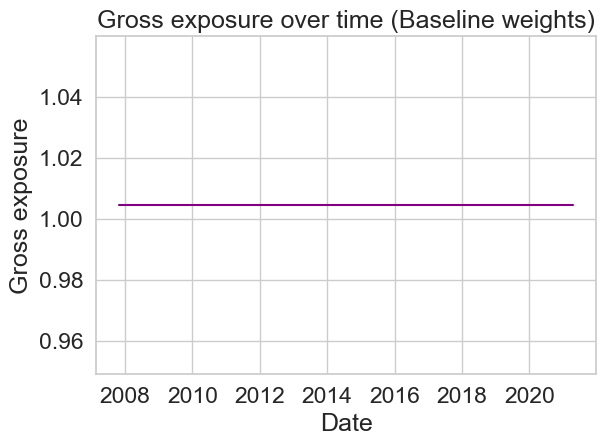

In [28]:
gross_exposure_series = weights_baseline_df.abs().sum(axis=1)
plt.plot(gross_exposure_series, color='purple')
plt.title('Gross exposure over time (Baseline weights)')
plt.xlabel('Date')
plt.ylabel('Gross exposure')
plt.grid(True)
plt.tight_layout()
plt.show()


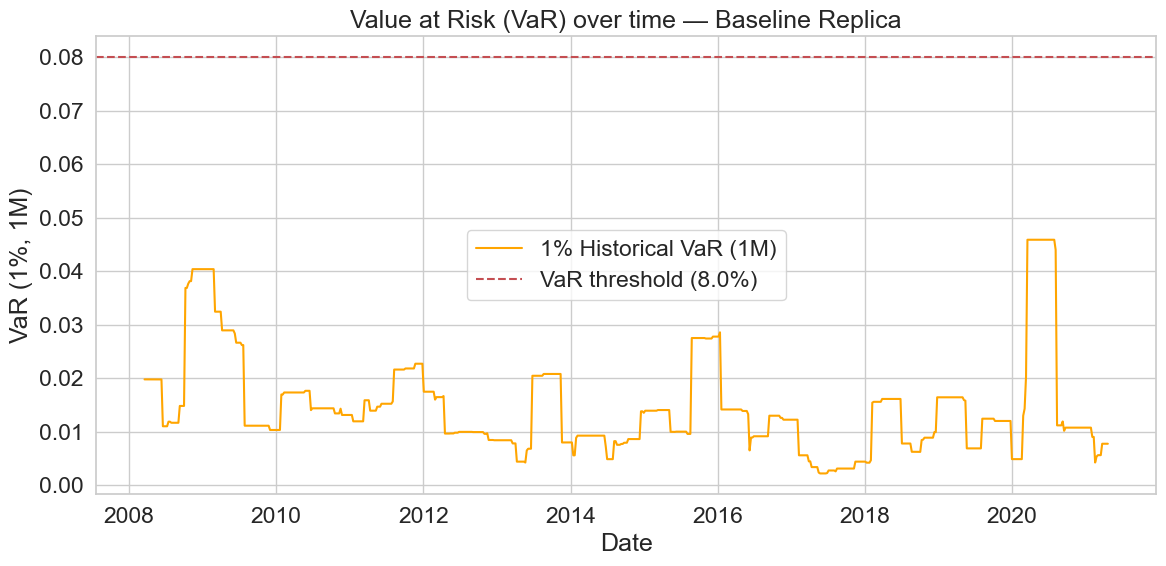

In [29]:
# Historical (non-parametric) VaR at 1% level using 1-month window (21 trading days)
var_window = 21  # 1 month of daily returns
confidence_level = 0.01

var_series = baseline_returns.rolling(window=var_window).quantile(confidence_level)

# Compute rolling 1% historical VaR (make it positive for plotting)
var_series = -baseline_returns.rolling(window=21).quantile(0.01)  # Absolute value

# Threshold: 0.8% as a positive number
max_var_threshold = 0.08  

# Plot
plt.figure(figsize=(12, 6))
plt.plot(var_series, color='orange', label='1% Historical VaR (1M)')
plt.axhline(y=max_var_threshold, color='r', linestyle='--', label=f'VaR threshold ({max_var_threshold*100:.1f}%)')
plt.title('Value at Risk (VaR) over time — Baseline Replica')
plt.xlabel('Date')
plt.ylabel('VaR (1%, 1M)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
def transaction_costs(weights_new, weights_old, cost_per_trade=0.0005):
    return cost_per_trade * np.sum(np.abs(weights_new - weights_old))

weights_baseline = weights_baseline_df.values

total_cost_baseline = 0
for t in range(0, T-1):
    cost = transaction_costs(weights_baseline[t], weights_baseline[t-1])
    total_cost_baseline += cost
total_cost_baseline

import numpy as np

def annualized_return(r, freq=52):
    return (1 + r.mean())**freq - 1

def annualized_volatility(r, freq=52):
    return r.std() * np.sqrt(freq)

def sharpe_ratio(r, rf=0, freq=52):
    return (r.mean() - rf) / r.std() * np.sqrt(freq)

def max_drawdown(cumulative_returns):
    running_max = cumulative_returns.cummax()
    drawdown = 1 - cumulative_returns / running_max
    return drawdown.max()

def tracking_error(r1, r2):
    return np.std(r1 - r2) * np.sqrt(52)

def information_ratio(r1, r2):
    diff = r1 - r2
    return diff.mean() / diff.std() * np.sqrt(52)

def average_gross_exposure(weights):
    return weights.abs().sum(axis=1).mean()

# Metrics
target_ret = annualized_return(Y)
target_vol = annualized_volatility(Y)
target_sharpe = sharpe_ratio(Y)
target_drawdown = max_drawdown(cumulative_target)

baseline_ret = annualized_return(baseline_returns)
baseline_vol = annualized_volatility(baseline_returns)
baseline_sharpe = sharpe_ratio(baseline_returns)
baseline_drawdown = max_drawdown(cumulative_baseline)
te = tracking_error(baseline_returns, Y)
ir = information_ratio(baseline_returns, Y)
corr = np.corrcoef(baseline_returns, Y)[0,1]
gross_exp = average_gross_exposure(weights_baseline_df)

metrics_baseline = pd.DataFrame({
    'Metric': ['Annualized return', 'Annualized volatility', 'Sharpe ratio',
               'Max Drawdown', 'Tracking Error', 'Information ratio',
               'Correlation', 'Average gross exposure', 'Average VaR (1%, 1M)'],
    'Target': [f"{target_ret*100:.2f}%",
               f"{target_vol*100:.2f}%",
               f"{target_sharpe:.2f}",
               f"{target_drawdown*100:.2f}%",
               "N/A", "N/A", "N/A", "N/A", "N/A"],
    'Baseline': [f"{baseline_ret*100:.2f}%",
                 f"{baseline_vol*100:.2f}%",
                 f"{baseline_sharpe:.2f}",
                 f"{baseline_drawdown*100:.2f}%",
                 f"{te*100:.2f}%",
                 f"{ir:.2f}",
                 f"{corr:.4f}",
                 f"{gross_exp:.4f}",
                 "N/A"]
})

print("\nMetrics for Baseline Portfolio:")
display(metrics_baseline)




Metrics for Baseline Portfolio:


,Metric,Target,Baseline
0,Annualized return,2.60%,2.55%
1,Annualized volatility,6.33%,5.69%
2,Sharpe ratio,0.41,0.44
3,Max Drawdown,29.01%,21.71%
4,Tracking Error,N/A,2.77%
5,Information ratio,N/A,-0.02
6,Correlation,N/A,0.8992
7,Average gross exposure,N/A,1.0044
8,"Average VaR (1%, 1M)",N/A,N/A


## KALMAN FILTER + TRANSACTIONJ COST + OPTUNA

In [31]:
import numpy as np
from sklearn.linear_model import Ridge

class KalmanPortfolioReplicator:
    def __init__(self, Q_std_regimes={0: 0.01, 1: 0.05, 2: 0.02}, R_std_regimes={0: 0.01, 1: 0.02, 2: 0.015}, transaction_cost=0.001):
        self.Q_std_regimes = Q_std_regimes
        self.R_std_regimes = R_std_regimes
        self.transaction_cost = transaction_cost
        self.is_fitted = False

    def fit(self, Y, C, regime, ridge_alpha=1.0):
        T, N = C.shape
        self.N = N
        self.x_filtered = np.zeros((T, N))
        self.x_predicted = np.zeros((T, N))
        self.y_hat = np.zeros(T)
        self.transaction_costs = np.zeros(T)

        # Initial Ridge estimate
        ridge = Ridge(alpha=ridge_alpha, fit_intercept=False)
        ridge.fit(C[:10], Y[:10])
        x_prev = ridge.coef_
        P_prev = np.eye(N) * 0.1

        for t in range(T):
            reg = regime[t]
            Q = np.eye(N) * self.Q_std_regimes.get(reg, 0.01)**2
            R = self.R_std_regimes.get(reg, 0.01)**2

            Ct = C[t].reshape(1, -1)
            y_t = Y[t]

            # Prediction
            x_pred = x_prev
            P_pred = P_prev + Q

            # Kalman gain
            S = Ct @ P_pred @ Ct.T + R
            K = (P_pred @ Ct.T) / S
            y_hat_t = Ct @ x_pred

            # Update
            x_new = x_pred + (K.flatten() * (y_t - y_hat_t)).flatten()
            P_new = (np.eye(N) - K @ Ct) @ P_pred

            # Calculate and apply transaction cost
            if t > 0:
                turnover = np.abs(x_new - x_prev).sum()
                tc = self.transaction_cost * turnover
                y_hat_t_adj = y_hat_t.item() - tc
                self.transaction_costs[t] = tc
            else:
                y_hat_t_adj = y_hat_t.item()

            # Store
            self.x_filtered[t] = x_new
            self.x_predicted[t] = x_pred
            self.y_hat[t] = y_hat_t_adj

            x_prev, P_prev = x_new, P_new

        self.weights_history = self.x_filtered.copy()  # <- This enables external access
        self.is_fitted = True

    def get_weights(self):
        return self.x_filtered

    def predict(self):
        return self.y_hat

    def get_transaction_costs(self):
        return self.transaction_costs


In [32]:
display(len(Y)==len(crash_labels))

True

In [33]:
import pandas as pd
from hmmlearn.hmm import GaussianHMM
import matplotlib.pyplot as plt

# Assuming Y is your target return series (Pandas Series)
returns = Y.dropna().values.reshape(-1, 1)

# Option A: Use raw returns (mean-based regimes)
X = returns

# Option B: Use rolling volatility (vol-based regimes)
# rolling_vol = Y.rolling(window=20).std().dropna()
# X = rolling_vol.values.reshape(-1, 1)

# Fit a 2-regime Gaussian HMM
model_HMM = GaussianHMM(n_components=3, covariance_type="full", n_iter=1000, random_state=42)
model_HMM.fit(X)

# Predict the regime at each time
hidden_states = model_HMM.predict(X)

# Add to DataFrame
Y_clean = Y.dropna()
regime_df = pd.DataFrame({
    "returns": Y_clean.values,
    "regime": hidden_states
}, index=Y_clean.index)

# Optional: sort regimes by average return for interpretation
regime_means = regime_df.groupby("regime")["returns"].mean().sort_values()
regime_map = {old: new for new, old in enumerate(regime_means.index)}
regime_df["regime"] = regime_df["regime"].map(regime_map)


Model is not converging.  Current: 2386.500523031817 is not greater than 2386.6826951954226. Delta is -0.18217216360562816


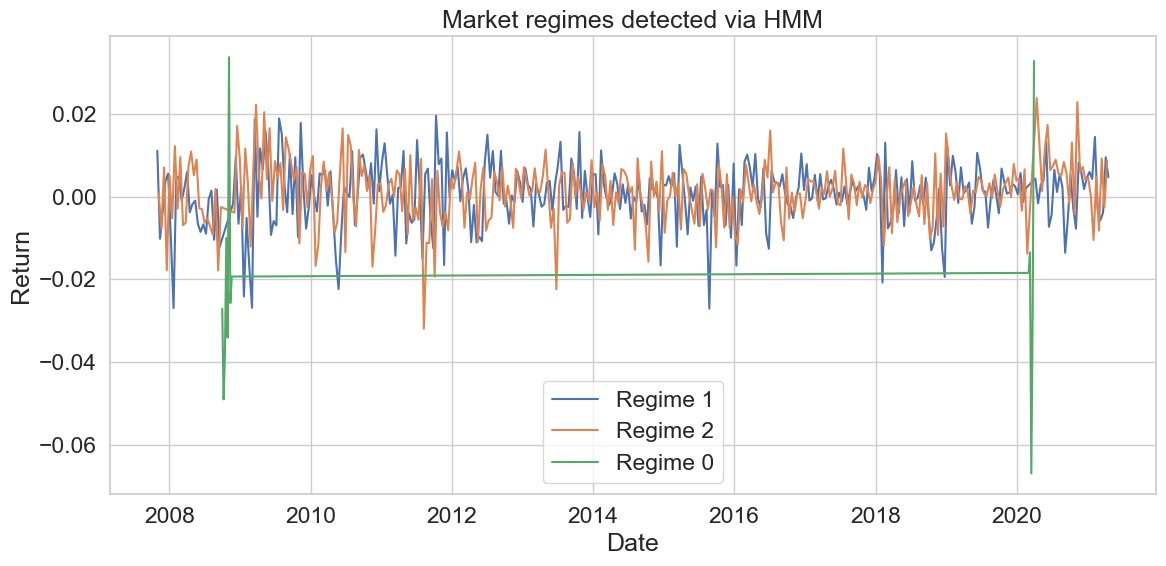

In [34]:
plt.figure(figsize=(12, 6))
for regime in regime_df["regime"].unique():
    mask = regime_df["regime"] == regime
    plt.plot(regime_df.index[mask], regime_df["returns"][mask], label=f"Regime {regime}")
plt.legend()
plt.title("Market regimes detected via HMM")
plt.xlabel("Date")
plt.ylabel("Return")
plt.grid(True)
plt.tight_layout()
plt.show()


In [35]:
import numpy as np

def cumulative_return_max_distance(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # Compute cumulative returns
    cum_true = np.cumprod(1 + y_true, axis=0)
    cum_pred = np.cumprod(1 + y_pred, axis=0)

    # Squared distance at each time point (T x N)
    squared_dist = (cum_true - cum_pred) ** 2

    # Max distance over time and assets
    return np.max(squared_dist)


In [36]:
def objective(trial):
    Q_std_regimes = {
        0: trial.suggest_float("Q_std_0", 1e-4, 0.2, log=True),
        1: trial.suggest_float("Q_std_1", 1e-4, 0.2, log=True),
        2: trial.suggest_float("Q_std_2", 1e-4, 0.2, log=True),
    }
    R_std_regimes = {
        0: trial.suggest_float("R_std_0", 1e-4, 0.2, log=True),
        1: trial.suggest_float("R_std_1", 1e-4, 0.2, log=True),
        2: trial.suggest_float("R_std_2", 1e-4, 0.2, log=True),
    }

    model_KF = KalmanPortfolioReplicator(Q_std_regimes=Q_std_regimes, R_std_regimes=R_std_regimes)
    model_KF.fit(Y.values, C.values, regime=regime_series.values)
    predicted_returns = model_KF.predict()

    return cumulative_return_max_distance(Y.values, predicted_returns)


In [37]:
import optuna

# Align regime vector with your Kalman inputs
regime_series = regime_df["regime"]
regime_series = regime_series.reindex(Y.index).ffill().bfill().astype(int)
# Run optimization
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=2000)

# Save best parameters to individual variables
Q_std_0 = study.best_params["Q_std_0"]
Q_std_1 = study.best_params["Q_std_1"]
Q_std_2 = study.best_params["Q_std_2"]
R_std_0 = study.best_params["R_std_0"]
R_std_1 = study.best_params["R_std_1"]
R_std_2 = study.best_params["R_std_2"]

print(f"Best Q_std: 0 → {Q_std_0:.5f}, 1 → {Q_std_1:.5f},  2 → {Q_std_2:.5f}")
print(f"Best R_std: 0 → {R_std_0:.5f}, 1 → {R_std_1:.5f},  2 → {R_std_2:.5f}")


[I 2025-06-22 00:33:04,687] A new study created in memory with name: no-name-f1ae0666-5e0e-4ed3-b4a1-d723f8f2cbaf
[I 2025-06-22 00:33:04,728] Trial 0 finished with value: 0.024021647606341047 and parameters: {'Q_std_0': 0.013626081987514993, 'Q_std_1': 0.0002840476777965683, 'Q_std_2': 0.001738031038421575, 'R_std_0': 0.08784586629263763, 'R_std_1': 0.00920791166066931, 'R_std_2': 0.00039523422567783016}. Best is trial 0 with value: 0.024021647606341047.
[I 2025-06-22 00:33:04,763] Trial 1 finished with value: 0.17038143340628153 and parameters: {'Q_std_0': 0.001454278914066028, 'Q_std_1': 0.0003263596350815753, 'Q_std_2': 0.03034487221575281, 'R_std_0': 0.038206427899918495, 'R_std_1': 0.00014165105376470278, 'R_std_2': 0.0029551430215434354}. Best is trial 0 with value: 0.024021647606341047.
[I 2025-06-22 00:33:04,803] Trial 2 finished with value: 0.04017615389311511 and parameters: {'Q_std_0': 0.002255978346342768, 'Q_std_1': 0.07428112686792705, 'Q_std_2': 0.05121797747377464, 'R_s

Best Q_std: 0 → 0.15677, 1 → 0.00015,  2 → 0.00013
Best R_std: 0 → 0.00090, 1 → 0.15275,  2 → 0.00780


In [38]:
# Fit Kalman with real regime detection

model_KPF = KalmanPortfolioReplicator(
    Q_std_regimes={0: Q_std_0, 1: Q_std_1, 2: Q_std_2},
    R_std_regimes={0: R_std_0, 1: R_std_1, 2: Q_std_2},
)
model_KPF.fit(Y.values, C.values, regime=regime_series.values)


weights = model_KPF.get_weights()   
predicted_returns = model_KPF.predict()


In [39]:
def transaction_costs(weights_new, weights_old, cost_per_trade=0.0005):
    return cost_per_trade * np.sum(np.abs(weights_new - weights_old))

total_cost = 0
for t in range(0, T-1):
    cost = transaction_costs(weights[t], weights[t-1])
    total_cost += cost
total_cost

np.float64(0.0917608897413563)

In [40]:
weights = model_KPF.get_weights() 

# Convert to DataFrame with original dates
weights_df = pd.DataFrame(weights, index=Y.index, columns=C.columns)

# Replica portfolio returns (daily): dot product of weights and returns
replica_returns = (weights_df * C).sum(axis=1)


cumulative_target = (1 + Y).cumprod()
cumulative_replica = (1 + replica_returns).cumprod()


In [41]:
import numpy as np

def annualized_return(r, freq=52):
    return (1 + r.mean())**freq - 1

def annualized_volatility(r, freq=52):
    return r.std() * np.sqrt(freq)

def sharpe_ratio(r, rf=0, freq=52):
    return (r.mean() - rf) / r.std() * np.sqrt(freq)

def max_drawdown(cumulative_returns):
    running_max = cumulative_returns.cummax()
    drawdown = 1 - cumulative_returns / running_max
    return drawdown.max()

def tracking_error(r1, r2):
    return np.std(r1 - r2) * np.sqrt(52)

def information_ratio(r1, r2):
    diff = r1 - r2
    return diff.mean() / diff.std() * np.sqrt(52)

def average_gross_exposure(weights):
    return weights.abs().sum(axis=1).mean()

# Metrics
target_ret = annualized_return(Y)
target_vol = annualized_volatility(Y)
target_sharpe = sharpe_ratio(Y)
target_drawdown = max_drawdown(cumulative_target)

replica_ret = annualized_return(replica_returns)
replica_vol = annualized_volatility(replica_returns)
replica_sharpe = sharpe_ratio(replica_returns)
replica_drawdown = max_drawdown(cumulative_replica)
te = tracking_error(replica_returns, Y)
ir = information_ratio(replica_returns, Y)
corr = np.corrcoef(replica_returns, Y)[0,1]
gross_exp = average_gross_exposure(weights_df)


In [42]:
ir

np.float64(-0.12150086953770954)

In [43]:
metrics_kalman = pd.DataFrame({
    'Metric': ['Annualized return', 'Annualized volatility', 'Sharpe ratio',
               'Max Drawdown', 'Tracking Error', 'Information ratio',
               'Correlation', 'Average gross exposure', 'Average VaR (1%, 1M)'],
    'Target': [f"{target_ret*100:.2f}%",
               f"{target_vol*100:.2f}%",
               f"{target_sharpe:.2f}",
               f"{target_drawdown*100:.2f}%",
               "N/A", "N/A", "N/A", "N/A", "N/A"],
    'Replica': [f"{replica_ret*100:.2f}%",
                f"{replica_vol*100:.2f}%",
                f"{replica_sharpe:.2f}",
                f"{replica_drawdown*100:.2f}%",
                f"{te*100:.2f}%",
                f"{ir:.2f}",
                f"{corr:.4f}",
                f"{gross_exp:.4f}",
                "N/A"]
})

print("\nMetrics for Kalman Filter Portfolio:")
display(metrics_kalman)



Metrics for Kalman Filter Portfolio:


,Metric,Target,Replica
0,Annualized return,2.60%,1.89%
1,Annualized volatility,6.33%,7.60%
2,Sharpe ratio,0.41,0.25
3,Max Drawdown,29.01%,27.43%
4,Tracking Error,N/A,5.74%
5,Information ratio,N/A,-0.12
6,Correlation,N/A,0.6739
7,Average gross exposure,N/A,1.7444
8,"Average VaR (1%, 1M)",N/A,N/A


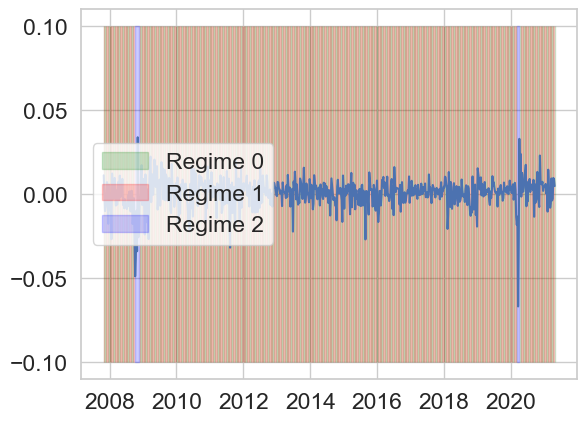

In [44]:
plt.plot(target_returns.index, target_returns)
plt.fill_between(target_returns.index, -0.1, 0.1, where=(hidden_states==0), color='green', alpha=0.2, label='Regime 0')
plt.fill_between(target_returns.index, -0.1, 0.1, where=(hidden_states==1), color='red', alpha=0.2, label='Regime 1')
plt.fill_between(target_returns.index, -0.1, 0.1, where=(hidden_states==2), color='blue', alpha=0.2, label='Regime 2')
plt.legend()


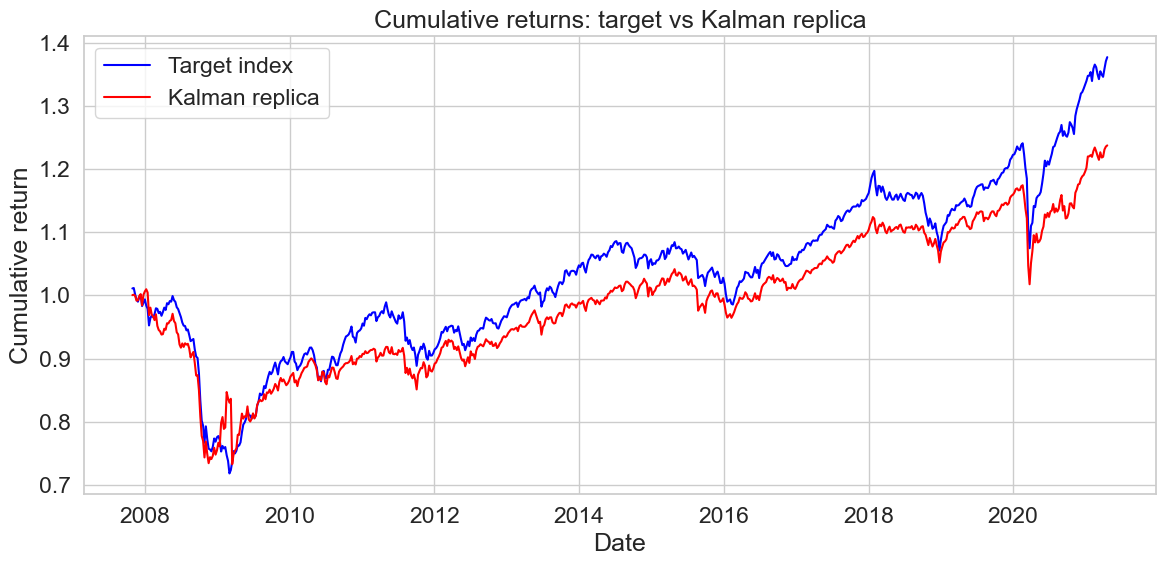

In [45]:
replica_returns = (weights_df * C).sum(axis=1)
cumulative_target = (1 + Y).cumprod()
cumulative_replica = (1 + replica_returns).cumprod()
plt.figure(figsize=(12, 6))
plt.plot(cumulative_target, label='Target index', color='blue')
plt.plot(cumulative_replica, label='Kalman replica', color='red')
plt.title('Cumulative returns: target vs Kalman replica')
plt.xlabel('Date')
plt.ylabel('Cumulative return')
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()




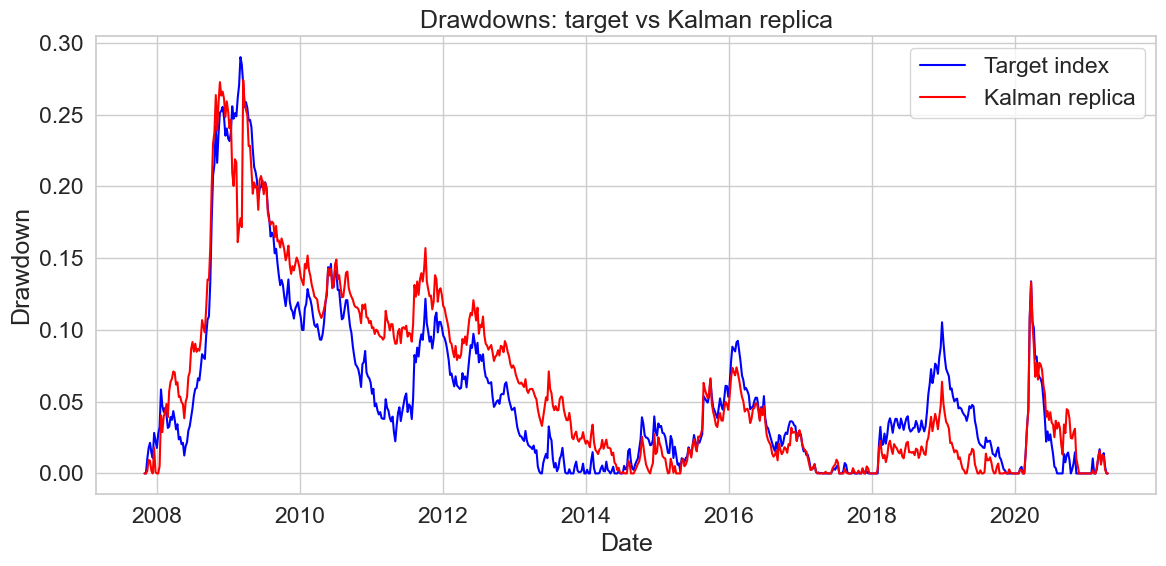

In [46]:
plt.figure(figsize=(12, 6))
target_drawdown = 1 - cumulative_target / cumulative_target.cummax()
replica_drawdown = 1 - cumulative_replica / cumulative_replica.cummax()
plt.plot(target_drawdown, label='Target index', color='blue')
plt.plot(replica_drawdown, label='Kalman replica', color='red')
plt.title('Drawdowns: target vs Kalman replica')
plt.xlabel('Date')
plt.ylabel('Drawdown')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


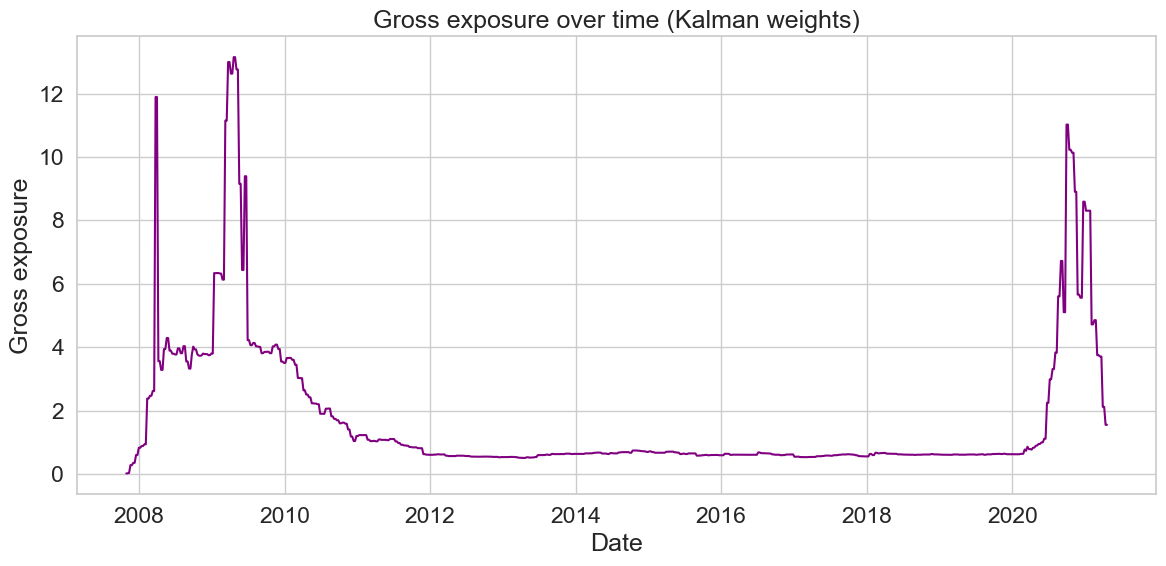

In [47]:
plt.figure(figsize=(12, 6))
gross_exposure_series = weights_df.abs().sum(axis=1)
plt.plot(gross_exposure_series, color='purple')
plt.title('Gross exposure over time (Kalman weights)')
plt.xlabel('Date')
plt.ylabel('Gross exposure')
plt.grid(True)
plt.tight_layout()
plt.show()


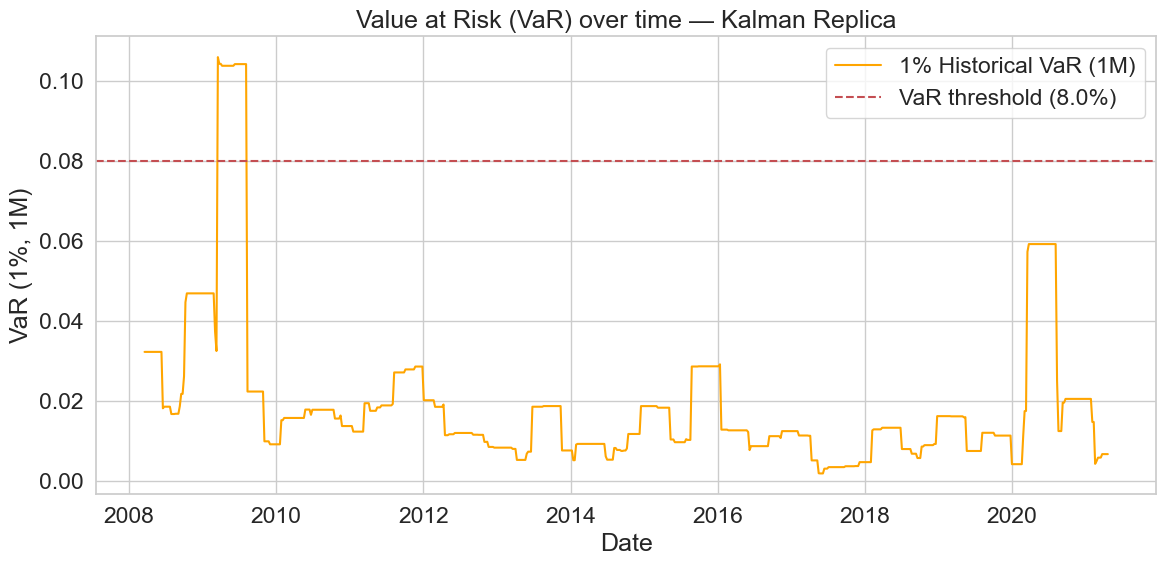

In [48]:
# Historical (non-parametric) VaR at 1% level using 1-month window (21 trading days)
var_window = 21  # 1 month of daily returns
confidence_level = 0.01

var_series = replica_returns.rolling(window=var_window).quantile(confidence_level)

# Compute rolling 1% historical VaR (make it positive for plotting)
var_series = -replica_returns.rolling(window=21).quantile(0.01)  # Absolute value

# Threshold: 0.8% as a positive number
max_var_threshold = 0.08  

# Plot
plt.figure(figsize=(12, 6))
plt.plot(var_series, color='orange', label='1% Historical VaR (1M)')
plt.axhline(y=max_var_threshold, color='r', linestyle='--', label=f'VaR threshold ({max_var_threshold*100:.1f}%)')
plt.title('Value at Risk (VaR) over time — Kalman Replica')
plt.xlabel('Date')
plt.ylabel('VaR (1%, 1M)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 🧩 From Regression Coefficients to Portfolio Weights

Once we fit a regression model, we **interpret the resulting coefficients as portfolio weights**.

### Why This Makes Sense

- The target variable (e.g., HFRX index returns or whatever) is modeled as a **linear combination** of asset returns.
- The fitted coefficients $beta_j$ represent the **contribution** of each asset to the replicated return.
- Therefore, we can treat them as **portfolio weights**.

$
\hat{r}_{\text{replica}} = \sum_j \beta_j \cdot r_j
$

---

#### Long and Short Positions

Because we are using **Futures contracts**, we can allow:
- **Positive weights** → long positions
- **Negative weights** → short positions

There is no need to constrain the model to long-only — the futures framework supports full long/short flexibility.

---

#### ⚠️ Risk Constraint: Monthly VaR

To control the portfolio's risk, we apply a **Value-at-Risk (VaR)** constraint (EU Law):
- **Horizon**: 1 month
- **Confidence level**: 99%
- **Maximum allowed VaR**: 20%

If the estimated VaR exceeds this threshold, or a lower prudential threshold, we **rescale the portfolio weights** to bring risk under control.

> This allows us to exploit long/short opportunities while maintaining a cap on downside risk.


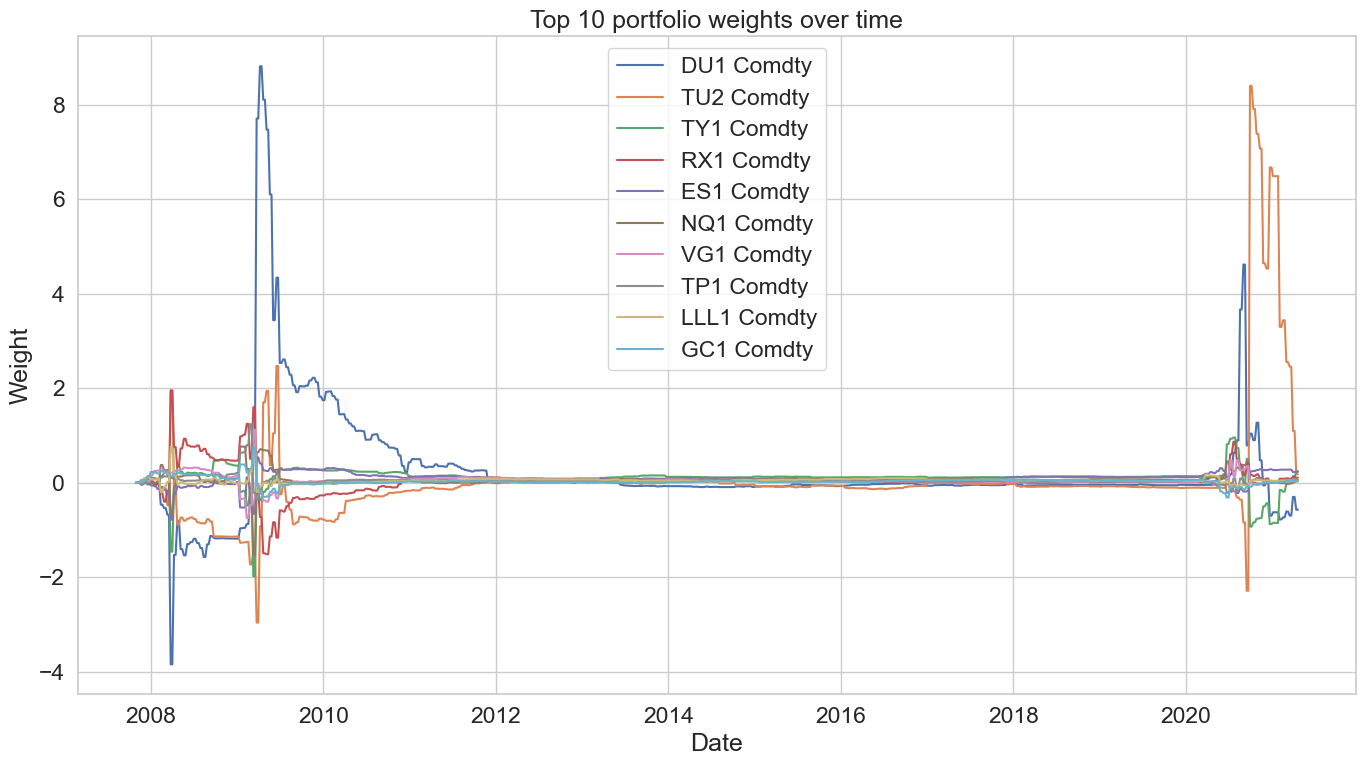

In [49]:
# Extract weights as DataFrame
weights_df = pd.DataFrame(model_KPF.weights_history, index=Y.index)
weights_df.columns = C.columns  # Use same order as predictors

# Plot top 10 weights by average absolute value
top_weights = weights_df.abs().mean().sort_values(ascending=False).head(10).index

plt.figure(figsize=(14, 8))
for col in top_weights:
    plt.plot(weights_df[col], label=col)

plt.title('Top 10 portfolio weights over time')
plt.xlabel('Date')
plt.ylabel('Weight')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# EARLY WARNING SYSTEM

## Coping with stationarity

### Stationarity Transformation

Unless we are using **cointegration** techniques, we need the data to be **stationary**. For an introduction to the idea of cointegration see  [Cointegration](https://en.wikipedia.org/wiki/Cointegration).

This means that the **joint distribution** of the features must be stable over time.

The rationale is intuitive:

- We want to use historical data to infer patterns related to systemic risk.
- If the underlying structure shifts over time, any model based on past behavior becomes unreliable.

> A non-stationary model is not just inaccurate — it’s structurally **wrong**.

---

#### How we transform the data

- **Indices and currencies**: log-differenced (they are strictly positive).
- **Interest rates and yields**: first differences (they can be negative or close to zero).
- **Economic surprise index**: left as is (already roughly stationary). Note: Do not take this as a rule for macroeconomic variables; many are non-stationary, sometimes they need to be differentiated TWICE (sic).


Only the **features** are transformed — not the labels, i.e., our vector Y.

> For **more background** (that many ML tutorials skip entirely):  
> - [Forecasting: Principles and Practice – Stationarity](https://otexts.com/fpp3/stationarity.html)  
> - [Cointegration and ECMs – Sørensen](https://www.uh.edu/~bsorense/coint.pdf)

<br>

In [50]:
# Adatta le variabili in base ai tuoi ticker reali
indices_currencies = [col for col in X_df.columns if col in ['MXWO Index', 'MXWD Index','GC1 Comdty', 'CO1 Comdty', 'TP1 Comdty', 'ES1 Comdty', 'VG1 Comdty', 'NQ1 Comdty', 'LLL1 Comdty',]]
interest_rates = [col for col in X_df.columns if col in ['RX1 Comdty', 'TY1 Comdty', 'DU1 Comdty', 'TU2 Comdty', 'LEGATRUU Index']]

# Dati stazionari
stationary_df = pd.DataFrame(index=X_df.index[1:])

for col in indices_currencies:
    if col in X_df.columns:
        stationary_df[col] = np.diff(np.log(X_df[col]))

for col in interest_rates:
    if col in X_df.columns:
        stationary_df[col] = np.diff(X_df[col])

stationary_df['HFRXGL Index'] = X_df['HFRXGL Index']

# Etichette allineate
if y is not None:
    y_stationary = y[1:]
else:
    y_stationary = None


## LSTM AUTOENCODER

In [51]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

# Fix random seeds
torch.manual_seed(42)
np.random.seed(42)

we preserve the index since we will need to reorder data later

In [52]:
import numpy as np
import pandas as pd
from sklearn.utils import shuffle
from sklearn.preprocessing import StandardScaler

# Your original DataFrame and labels
X = stationary_df.values
y = y_stationary
original_indexes = stationary_df.index.values  # Keep original time/index

# Step 1: Shuffle data but keep indexes together
data_with_idx = list(zip(original_indexes, X, y))
np.random.seed(42)
np.random.shuffle(data_with_idx)

# Unzip after shuffle
shuffled_indexes, X_shuffled, y_shuffled = zip(*data_with_idx)
shuffled_indexes = np.array(shuffled_indexes)
X_shuffled = np.array(X_shuffled)
y_shuffled = np.array(y_shuffled)

# Separate normal and anomalous examples
normal_mask = (y_shuffled == 0)
anomaly_mask = (y_shuffled == 1)

X_normal = X_shuffled[normal_mask]
idx_normal = shuffled_indexes[normal_mask]

X_anomaly = X_shuffled[anomaly_mask]
idx_anomaly = shuffled_indexes[anomaly_mask]

n_normal = X_normal.shape[0]
n_anomaly = X_anomaly.shape[0]

# Training set: 80% of normal examples
train_size = int(0.8 * n_normal)
X_train = X_normal[:train_size]
idx_train = idx_normal[:train_size]
y_train = np.zeros(train_size, dtype=int)  # all normal in train

# Cross-validation set: 10% of normal examples and 50% of anomalies
cv_normal_size = int(0.1 * n_normal)
cv_anomaly_size = int(0.5 * n_anomaly)

X_cv_normal = X_normal[train_size:train_size + cv_normal_size]
idx_cv_normal = idx_normal[train_size:train_size + cv_normal_size]
y_cv_normal = np.zeros(cv_normal_size, dtype=int)

X_cv_anomaly = X_anomaly[:cv_anomaly_size]
idx_cv_anomaly = idx_anomaly[:cv_anomaly_size]
y_cv_anomaly = np.ones(cv_anomaly_size, dtype=int)

X_cross_val = np.vstack((X_cv_normal, X_cv_anomaly))
idx_cross_val = np.hstack((idx_cv_normal, idx_cv_anomaly))
y_cross_val = np.hstack((y_cv_normal, y_cv_anomaly))

# Test set: 10% of normal examples and 50% of anomalies
X_test_normal = X_normal[train_size + cv_normal_size:]
idx_test_normal = idx_normal[train_size + cv_normal_size:]
y_test_normal = np.zeros(len(X_test_normal), dtype=int)

X_test_anomaly = X_anomaly[cv_anomaly_size:]
idx_test_anomaly = idx_anomaly[cv_anomaly_size:]
y_test_anomaly = np.ones(len(X_test_anomaly), dtype=int)

X_test = np.vstack((X_test_normal, X_test_anomaly))
idx_test = np.hstack((idx_test_normal, idx_test_anomaly))
y_test = np.hstack((y_test_normal, y_test_anomaly))
# Standardize data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_cross_val = scaler.transform(X_cross_val)
X_test = scaler.transform(X_test)

# Print sizes summary
print(f"Training set size: {X_train.shape[0]} (all normal)")
print(f"Cross-validation set size: {X_cross_val.shape[0]} ({cv_normal_size} normal, {cv_anomaly_size} anomalies)")
print(f"Test set size: {X_test.shape[0]} ({len(X_test_normal)} normal, {len(X_test_anomaly)} anomalies)")





Training set size: 498 (all normal)
Cross-validation set size: 102 (62 normal, 40 anomalies)
Test set size: 104 (63 normal, 41 anomalies)


In [53]:
SEQ_LEN = 10  # length of LSTM input sequences
BATCH_SIZE = 64
EPOCHS = 200
LR = 1e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Normalize data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_cv_scaled = scaler.transform(X_cross_val)
X_test_scaled = scaler.transform(X_test)

# Function to create sliding windows
def create_sequences(data, seq_len):
    seqs = []
    for i in range(len(data) - seq_len):
        seq = data[i:i+seq_len]
        seqs.append(seq)
    return np.array(seqs)

train_seq = create_sequences(X_train_scaled, SEQ_LEN)
cv_seq = create_sequences(X_cv_scaled, SEQ_LEN)
test_seq = create_sequences(X_test_scaled, SEQ_LEN)

# Adjust labels to match sequences
y_cv_seq = y_cross_val[SEQ_LEN:]
y_test_seq = y_test[SEQ_LEN:]

In [54]:
class SequenceDataset(Dataset):
    def __init__(self, sequences):
        self.sequences = torch.tensor(sequences, dtype=torch.float32)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx]

train_loader = DataLoader(SequenceDataset(train_seq), batch_size=BATCH_SIZE, shuffle=True)
cv_loader = DataLoader(SequenceDataset(cv_seq), batch_size=1, shuffle=False)
test_loader = DataLoader(SequenceDataset(test_seq), batch_size=1, shuffle=False)


In [55]:
class LSTMAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=32):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.encoder = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.decoder = nn.LSTM(hidden_dim, input_dim, batch_first=True)

    def forward(self, x):
        _, (hidden, _) = self.encoder(x)
        repeated_hidden = hidden.repeat(x.size(1), 1, 1).permute(1, 0, 2)
        out, _ = self.decoder(repeated_hidden)
        return out

    def encode(self, x):
        _, (hidden, _) = self.encoder(x)
        return hidden.squeeze(0)


model_LSTM = LSTMAutoencoder(input_dim=X_train.shape[1]).to(DEVICE)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_LSTM.parameters(), lr=LR)

In [56]:
model_LSTM.train()
for epoch in range(EPOCHS):
    losses = []
    for batch in train_loader:
        batch = batch.to(DEVICE)
        output = model_LSTM(batch)
        loss = criterion(output, batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    print(f"Epoch {epoch+1}/{EPOCHS}, Loss: {np.mean(losses):.5f}")


Epoch 1/200, Loss: 1.00435
Epoch 2/200, Loss: 0.99741
Epoch 3/200, Loss: 0.99182
Epoch 4/200, Loss: 0.98692
Epoch 5/200, Loss: 0.97961
Epoch 6/200, Loss: 0.97240
Epoch 7/200, Loss: 0.96241
Epoch 8/200, Loss: 0.95647
Epoch 9/200, Loss: 0.95122
Epoch 10/200, Loss: 0.94251
Epoch 11/200, Loss: 0.93944
Epoch 12/200, Loss: 0.92706
Epoch 13/200, Loss: 0.92718
Epoch 14/200, Loss: 0.92937
Epoch 15/200, Loss: 0.92600
Epoch 16/200, Loss: 0.92254
Epoch 17/200, Loss: 0.92058
Epoch 18/200, Loss: 0.91808
Epoch 19/200, Loss: 0.91848
Epoch 20/200, Loss: 0.91371
Epoch 21/200, Loss: 0.91049
Epoch 22/200, Loss: 0.91382
Epoch 23/200, Loss: 0.91080
Epoch 24/200, Loss: 0.90708
Epoch 25/200, Loss: 0.91005
Epoch 26/200, Loss: 0.90315
Epoch 27/200, Loss: 0.90422
Epoch 28/200, Loss: 0.90070
Epoch 29/200, Loss: 0.89735
Epoch 30/200, Loss: 0.89700
Epoch 31/200, Loss: 0.89266
Epoch 32/200, Loss: 0.89312
Epoch 33/200, Loss: 0.89144
Epoch 34/200, Loss: 0.88916
Epoch 35/200, Loss: 0.88620
Epoch 36/200, Loss: 0.88535
E

Anomaly threshold: 1.4744056
Cross-validation results:
              precision    recall  f1-score   support

           0     0.8125    1.0000    0.8966        52
           1     1.0000    0.7000    0.8235        40

    accuracy                         0.8696        92
   macro avg     0.9062    0.8500    0.8600        92
weighted avg     0.8940    0.8696    0.8648        92

Test results:
              precision    recall  f1-score   support

           0     0.8413    1.0000    0.9138        53
           1     1.0000    0.7561    0.8611        41

    accuracy                         0.8936        94
   macro avg     0.9206    0.8780    0.8875        94
weighted avg     0.9105    0.8936    0.8908        94



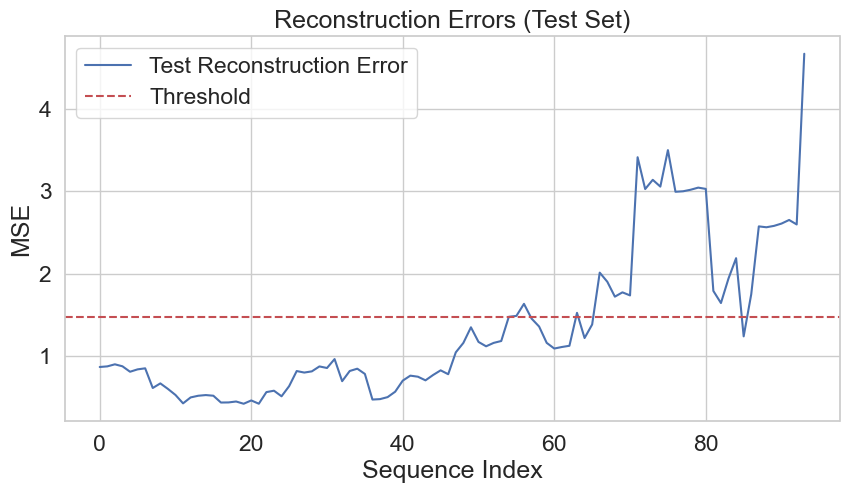

In [57]:
def compute_reconstruction_errors(data_loader):
    model_LSTM.eval()
    errors = []
    with torch.no_grad():
        for batch in data_loader:
            batch = batch.to(DEVICE)
            output = model_LSTM(batch)
            loss = torch.mean((batch - output)**2, dim=(1, 2))
            errors.extend(loss.cpu().numpy())
    return np.array(errors)

cv_errors = compute_reconstruction_errors(cv_loader)
test_errors = compute_reconstruction_errors(test_loader)

# Set anomaly threshold using CV set (95th percentile)
threshold = np.percentile(cv_errors, 70)
print("Anomaly threshold:", threshold)

# Detect anomalies
y_cv_pred = (cv_errors > threshold).astype(int)
y_test_pred = (test_errors > threshold).astype(int)

from sklearn.metrics import classification_report

print("Cross-validation results:")
print(classification_report(y_cv_seq, y_cv_pred, digits=4))

print("Test results:")
print(classification_report(y_test_seq, y_test_pred, digits=4))

# =========================
# Plot reconstruction error
# =========================
plt.figure(figsize=(10,5))
plt.plot(test_errors, label="Test Reconstruction Error")
plt.axhline(threshold, color='r', linestyle='--', label="Threshold")
plt.title("Reconstruction Errors (Test Set)")
plt.xlabel("Sequence Index")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [58]:
from sklearn.metrics import f1_score

def find_best_threshold(errors, true_labels, thresholds=np.linspace(0.001, 1.0, 500)):
    best_f1 = 0
    best_threshold = thresholds[0]
    
    for thresh in thresholds:
        preds = (errors > thresh).astype(int)
        score = f1_score(true_labels, preds, zero_division=0)
        if score > best_f1:
            best_f1 = score
            best_threshold = thresh

    return best_threshold, best_f1


In [59]:
threshold_range = np.linspace(min(test_errors), max(test_errors), 500)
best_threshold, best_f1 = find_best_threshold(test_errors, y_test_seq, threshold_range)

# Get final predictions based on best threshold
y_test_pred = (test_errors > best_threshold).astype(int)

In [60]:
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc

# Evaluate the autoencoder model
def evaluate_autoencoder(y_true, y_pred, reconstruction_errors, threshold):
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print("\nAutoencoder performance:")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Normal', 'Anomaly'],
                yticklabels=['Normal', 'Anomaly'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix - Autoencoder')
    plt.tight_layout()
    plt.show()

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_true, reconstruction_errors)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC curve - Autoencoder')
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    # Visualize reconstruction error distribution
    plt.figure(figsize=(10, 6))
    plt.scatter(range(len(reconstruction_errors)),
                reconstruction_errors,
                c=['blue' if label == 0 else 'red' for label in y_true],
                alpha=0.5)
    plt.axhline(y=threshold, color='green', linestyle='--', label=f'Threshold: {threshold:.4f}')
    plt.title('Reconstruction error for test set')
    plt.xlabel('Sample index')
    plt.ylabel('Reconstruction error')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return precision, recall, f1, roc_auc


from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

def visualize_autoencoder_pca(X, y_true, y_pred, reconstruction_errors, threshold, model, X_seq_tensor):
    model.eval()
    
    with torch.no_grad():
        latent_vectors = model.encode(X_seq_tensor).cpu()

    # Check if 2D
    if latent_vectors.ndim == 1:
        latent_vectors = latent_vectors.unsqueeze(0)

    print("latent_vectors.shape:", latent_vectors.shape)

    # Apply PCA if needed
    if latent_vectors.shape[1] > 2:
        pca = PCA(n_components=2)
        latent_2d = pca.fit_transform(latent_vectors)
    else:
        latent_2d = latent_vectors.numpy()

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # First plot: Ground truth
    axes[0].scatter(latent_2d[:, 0], latent_2d[:, 1], c=y_true, cmap='coolwarm', alpha=0.7)
    axes[0].set_title("Latent Space Projection (Ground Truth)")
    axes[0].set_xlabel("PC1")
    axes[0].set_ylabel("PC2")

    # Second plot: Predicted as anomalies
    axes[1].scatter(latent_2d[:, 0], latent_2d[:, 1], c=y_pred, cmap='coolwarm', alpha=0.7)
    axes[1].set_title("Latent Space Projection (Predicted Anomalies)")
    axes[1].set_xlabel("PC1")
    axes[1].set_ylabel("PC2")

    plt.tight_layout()
    plt.show()

    # Plot: reconstruction error
    plt.figure(figsize=(10, 5))
    plt.scatter(range(len(reconstruction_errors)), reconstruction_errors, c=y_true, cmap='coolwarm', alpha=0.6)
    plt.axhline(threshold, color='red', linestyle='--', label="Threshold")
    plt.title("Reconstruction Error by Sequence")
    plt.xlabel("Sequence Index")
    plt.ylabel("Reconstruction Error")
    plt.legend()
    plt.show()



Autoencoder performance:
Precision: 0.8913
Recall: 1.0000
F1 Score: 0.9425


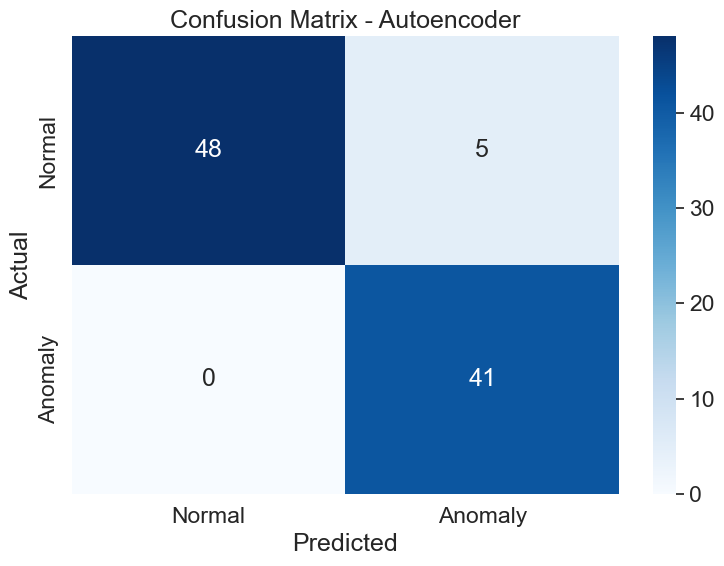

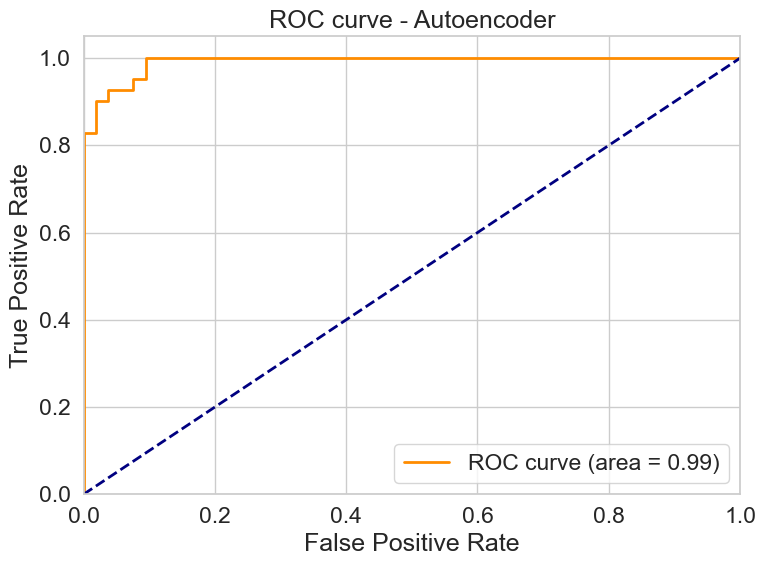

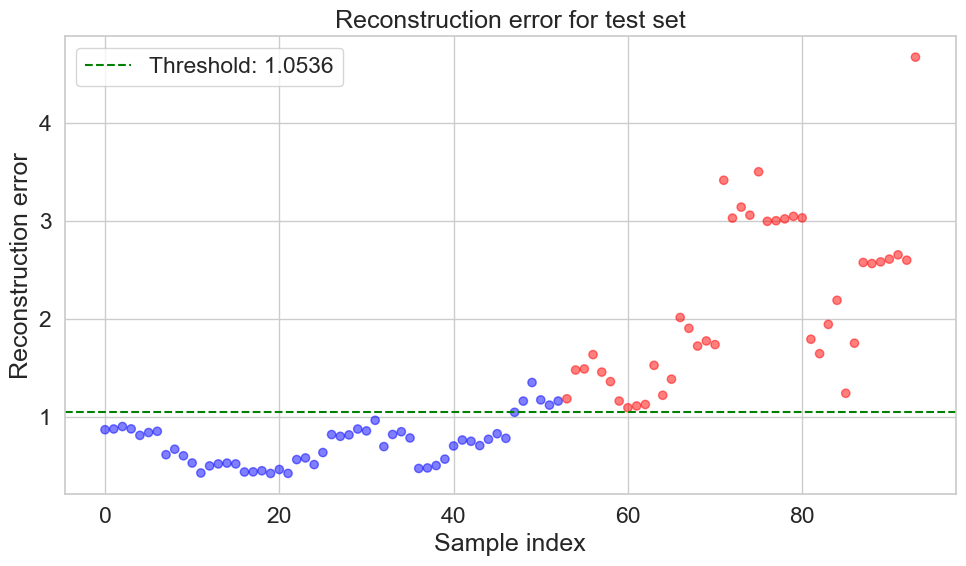

latent_vectors.shape: torch.Size([94, 32])


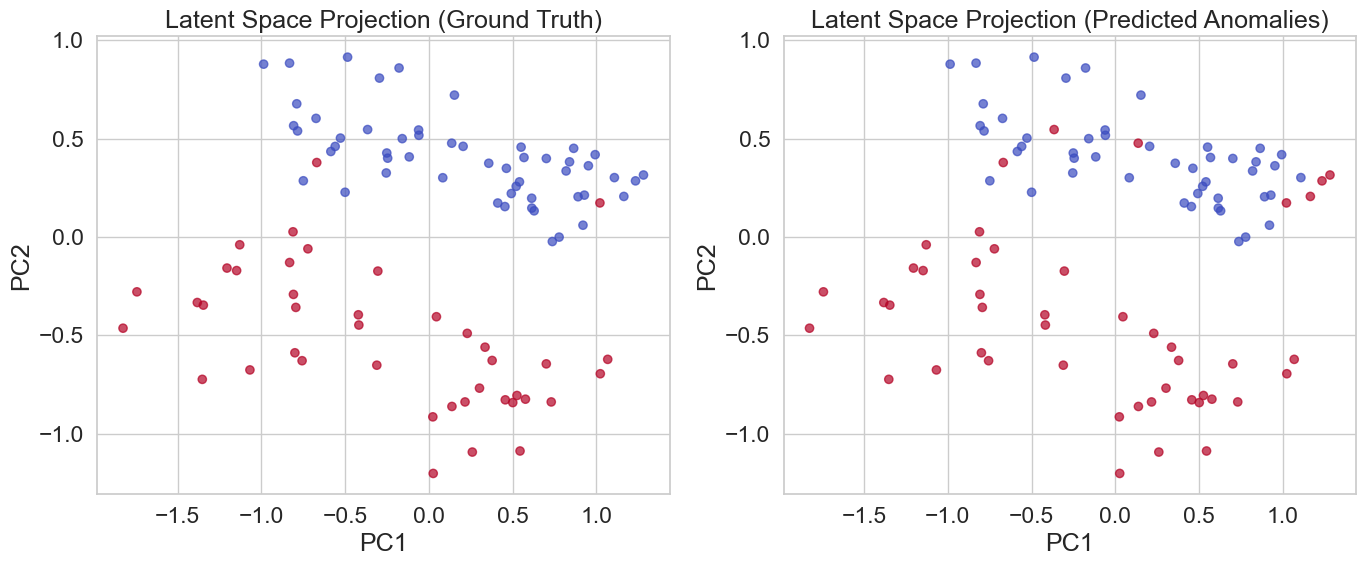

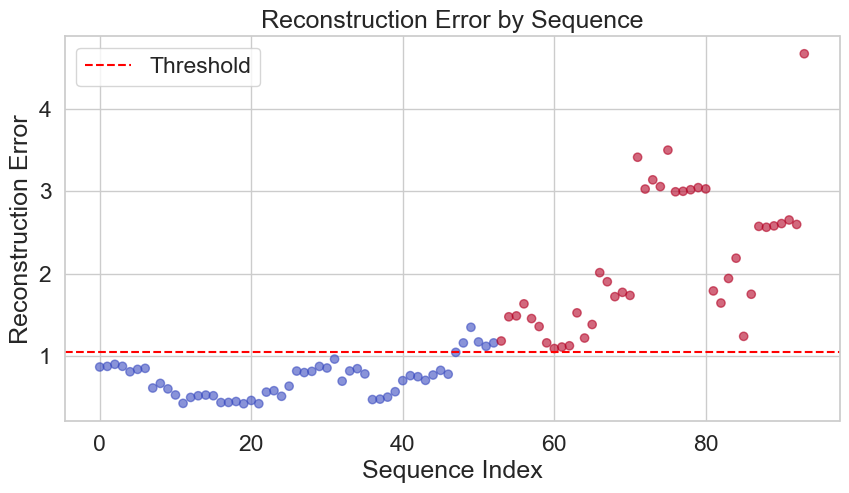

In [61]:
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.metrics import roc_curve, auc
y_pred_vect = {}
ae_metrics = evaluate_autoencoder(
    y_true=y_test_seq,
    y_pred=y_test_pred,
    reconstruction_errors=test_errors,
    threshold=best_threshold
)

y_pred_vect["LSTM autoencoder"] = y_test_pred

X_seq_tensor = torch.tensor(test_seq, dtype=torch.float32).to(DEVICE)

visualize_autoencoder_pca(
    X=X_test_scaled[SEQ_LEN:],  # optional, here it's not used
    y_true=y_test_seq,
    y_pred=y_test_pred,
    reconstruction_errors=test_errors,
    threshold=best_threshold,
    model=model_LSTM,
    X_seq_tensor=X_seq_tensor
)


## CBIGAN

In [62]:
# 3.  Deep Learning methods: Autoencoder
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Latent space size
z_dim = 32
# Convert data to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train_scaled).to(device)
X_cv_tensor = torch.FloatTensor(X_cv_scaled).to(device)
X_test_tensor = torch.FloatTensor(X_test_scaled).to(device)
input_dim = X_train_tensor.shape[1]

Using device: cpu


In [63]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve, roc_auc_score, classification_report
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ==== Parameters ====
SEQ_LEN = 10           # sequence length
INPUT_DIM = 15         # number of features per timestep
LATENT_DIM = 10        # dimensionality of latent space
HIDDEN_DIM = 64        # hidden dimension for LSTMs
NUM_LAYERS = 1         # number of LSTM layers
LR = 1e-4
EPOCHS = 80
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==== Dummy Data Placeholder (replace with real data) ====
# X_train, X_cross_val, X_test = ...
# y_cross_val, y_test = ...



def create_sequences(data, seq_len):
    return np.array([data[i:i+seq_len] for i in range(len(data)-seq_len)])

train_seq = create_sequences(X_train_scaled, SEQ_LEN)
cv_seq = create_sequences(X_cv_scaled, SEQ_LEN)
test_seq = create_sequences(X_test_scaled, SEQ_LEN)
y_cv_seq = y_cross_val[SEQ_LEN:]
y_test_seq = y_test[SEQ_LEN:]

# ==== Dataset Class ====
class SequenceDataset(Dataset):
    def __init__(self, sequences):
        self.sequences = torch.tensor(sequences, dtype=torch.float32)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], torch.tensor(0)  


train_loader = DataLoader(SequenceDataset(train_seq), batch_size=BATCH_SIZE, shuffle=True)

# ==== CBIGAN Components ====
import torch
import torch.nn as nn

class LSTMEncoder(nn.Module):
    def __init__(self, input_dim, latent_dim, hidden_dim=64, num_layers=1):
        super(LSTMEncoder, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        z = self.fc(h_n[-1])  
        return z

class LSTMGenerator(nn.Module):
    def __init__(self, latent_dim, output_dim, seq_len=10, hidden_dim=64, num_layers=1):
        super(LSTMGenerator, self).__init__()
        self.seq_len = seq_len
        self.fc = nn.Linear(latent_dim, hidden_dim)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, num_layers, batch_first=True)
        self.output_layer = nn.Linear(hidden_dim, output_dim)

    def forward(self, z):
        h = self.fc(z)  
        h_seq = h.unsqueeze(1).repeat(1, self.seq_len, 1)  
        lstm_out, _ = self.lstm(h_seq)
        return self.output_layer(lstm_out)  

class LSTMDiscriminator(nn.Module):
    def __init__(self, input_dim, latent_dim, hidden_dim=64):
        super(LSTMDiscriminator, self).__init__()
        self.lstm_x = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.fc_z = nn.Linear(latent_dim, hidden_dim)
        self.final = nn.Linear(2 * hidden_dim, 1)

    def forward(self, x, z):
        _, (h_x, _) = self.lstm_x(x) 
        h_x = h_x[-1]  
        h_z = self.fc_z(z)  
        h = torch.cat([h_x, h_z], dim=1)  
        return self.final(h)  



# ==== Initialize Models ====
input_dim = X_train.shape[1]
E = LSTMEncoder(INPUT_DIM, LATENT_DIM, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS).to(DEVICE)
G = LSTMGenerator(LATENT_DIM, INPUT_DIM, seq_len=SEQ_LEN, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS).to(DEVICE)
D = LSTMDiscriminator(INPUT_DIM, LATENT_DIM, hidden_dim=HIDDEN_DIM).to(DEVICE)


optimizer_E = torch.optim.Adam(E.parameters(), lr=LR)
optimizer_G = torch.optim.Adam(G.parameters(), lr=LR)
optimizer_D = torch.optim.Adam(D.parameters(), lr=LR)

# ==== Training Loop ====
def train_cbigan():
    E.train(); G.train(); D.train()
    for epoch in range(EPOCHS):
        for batch in train_loader:
            x_real, _ = batch
            x_real = x_real.to(DEVICE)
            batch_size = x_real.size(0)

            # Train Discriminator
            z_fake = torch.randn(batch_size, LATENT_DIM).to(DEVICE)
            x_fake = G(z_fake).detach()
            z_real = E(x_real).detach()

            d_real = D(x_real, z_real)
            d_fake = D(x_fake, z_fake)
            d_loss = -(torch.mean(d_real) - torch.mean(d_fake))

            optimizer_D.zero_grad()
            d_loss.backward()
            optimizer_D.step()

            # Train Generator and Encoder
            z_fake = torch.randn(batch_size, LATENT_DIM).to(DEVICE)
            x_fake = G(z_fake)
            d_fake = D(x_fake, z_fake)

            z_real = E(x_real)
            d_real = D(x_real, z_real)

            x_recon = G(z_real)
            z_recon = E(x_recon)

            g_loss = -torch.mean(d_fake)
            e_loss = -torch.mean(d_real)

            consistency_loss = torch.mean((z_real - z_recon) ** 2)
            recon_loss = torch.mean((x_real - x_recon) ** 2)

            total_loss = g_loss + e_loss + 10.0 * consistency_loss + 10.0 * recon_loss

            optimizer_G.zero_grad()
            optimizer_E.zero_grad()
            total_loss.backward()
            optimizer_G.step()
            optimizer_E.step()

        print(f"Epoch [{epoch+1}/{EPOCHS}], D Loss: {d_loss.item():.4f}, G Loss: {g_loss.item():.4f}, Recon: {recon_loss.item():.4f}")

train_cbigan()

# === Inference ===
def compute_anomaly_scores(data_seq):
    E.eval(); G.eval()
    scores = []
    with torch.no_grad():
        for i in range(len(data_seq)):
            x = torch.tensor(data_seq[i:i+1], dtype=torch.float32).to(DEVICE)
            z = E(x)
            x_recon = G(z)
            score = torch.mean((x - x_recon) ** 2).item()
            scores.append(score)
    return np.array(scores)

cv_scores = compute_anomaly_scores(cv_seq)
test_scores = compute_anomaly_scores(test_seq)

# === Threshold Selection ===
precision, recall, thresholds = precision_recall_curve(y_cv_seq, cv_scores)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_idx = np.argmax(f1_scores)
best_thresh = thresholds[best_idx]

# === Final Prediction and Report ===
y_test_pred = (test_scores > best_thresh).astype(int)
print("\nTest Classification Report:")
print(classification_report(y_test_seq, y_test_pred))


Using device: cpu
Epoch [1/80], D Loss: -0.0085, G Loss: 0.0126, Recon: 1.0261
Epoch [2/80], D Loss: -0.0229, G Loss: 0.0208, Recon: 0.8807
Epoch [3/80], D Loss: -0.0245, G Loss: 0.0529, Recon: 1.0147
Epoch [4/80], D Loss: -0.0163, G Loss: 0.0317, Recon: 0.9464
Epoch [5/80], D Loss: -0.0258, G Loss: 0.0315, Recon: 0.9966
Epoch [6/80], D Loss: -0.0126, G Loss: 0.0435, Recon: 0.9551
Epoch [7/80], D Loss: -0.0736, G Loss: 0.0571, Recon: 1.0397
Epoch [8/80], D Loss: -0.0294, G Loss: 0.0091, Recon: 0.9541
Epoch [9/80], D Loss: -0.0666, G Loss: 0.0012, Recon: 1.0456
Epoch [10/80], D Loss: -0.1074, G Loss: -0.0006, Recon: 0.9528
Epoch [11/80], D Loss: -0.0332, G Loss: 0.0435, Recon: 0.9770
Epoch [12/80], D Loss: -0.1125, G Loss: 0.0768, Recon: 0.9682
Epoch [13/80], D Loss: -0.1668, G Loss: 0.0818, Recon: 0.9658
Epoch [14/80], D Loss: -0.1168, G Loss: 0.0878, Recon: 1.0451
Epoch [15/80], D Loss: -0.1252, G Loss: 0.1198, Recon: 0.9664
Epoch [16/80], D Loss: -0.1786, G Loss: 0.1271, Recon: 0.903

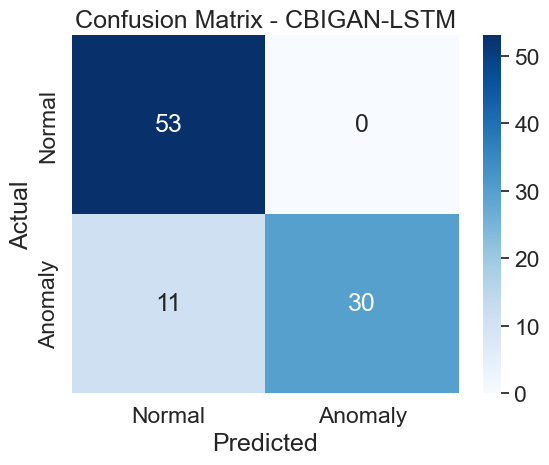

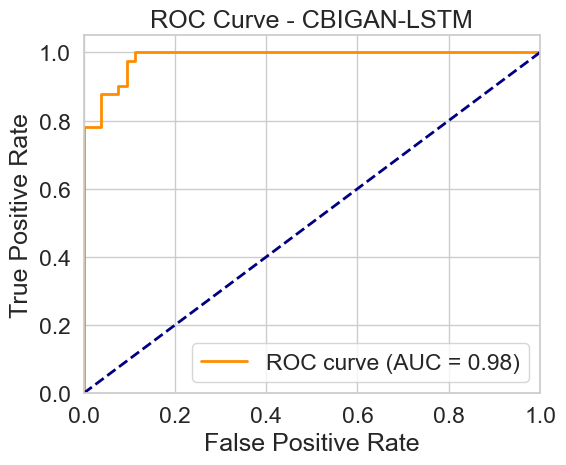

In [64]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, auc
import seaborn as sns
import numpy as np

# ---- These variables must already be defined ----
# y_test_seq       : ground truth labels for the test set
# y_test_pred      : binary predictions from the model
# anomaly_scores   : anomaly scores (higher = more anomalous)
# -------------------------------------------------
y_pred_vect["LSTM + CBiGAN"] = y_test_pred
# Confusion Matrix
cm = confusion_matrix(y_test_seq, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Anomaly'],
            yticklabels=['Normal', 'Anomaly'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - CBIGAN-LSTM')
plt.tight_layout()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test_seq, test_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - CBIGAN-LSTM')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


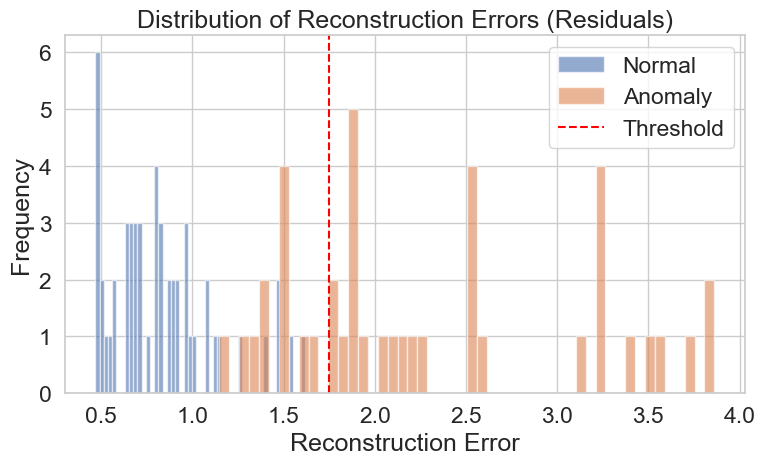

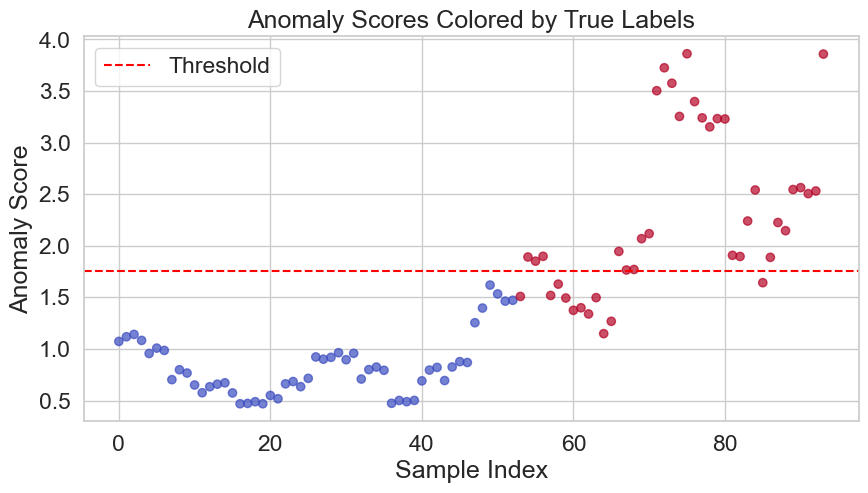

In [65]:
# Plot Reconstruction Errors (Residuals) Distribution
plt.figure(figsize=(8, 5))
plt.hist(test_scores[y_test_seq == 0], bins=50, alpha=0.6, label='Normal')
plt.hist(test_scores[y_test_seq == 1], bins=50, alpha=0.6, label='Anomaly')
plt.axvline(best_thresh, color='red', linestyle='--', label='Threshold')
plt.xlabel('Reconstruction Error')
plt.ylabel('Frequency')
plt.title('Distribution of Reconstruction Errors (Residuals)')
plt.legend()
plt.tight_layout()
plt.show()


# Scatter plot of anomaly scores colored by true class and predicted class
plt.figure(figsize=(10, 5))

# True class color
plt.scatter(range(len(test_scores)), test_scores, c=y_test_seq, cmap='coolwarm', alpha=0.7)
plt.axhline(best_thresh, color='red', linestyle='--', label='Threshold')
plt.title('Anomaly Scores Colored by True Labels')
plt.xlabel('Sample Index')
plt.ylabel('Anomaly Score')
plt.legend()

# # Predicted class color
# plt.subplot(1, 2, 2)
# plt.scatter(range(len(test_scores)), test_scores, c=y_test_pred, cmap='coolwarm', alpha=0.7)
# plt.axhline(best_thresh, color='red', linestyle='--', label='Threshold')
# plt.title('Anomaly Scores Colored by Predicted Labels')
# plt.xlabel('Sample Index')
# plt.ylabel('Anomaly Score')
# plt.legend()

# plt.tight_layout()
# plt.show()


# TAILORED STRATEGY FOR PORTFOLIO REPLICA

In [66]:
#Define low volatility assets and their weights

low_vol_weights = {
    'DU1 Comdty': 0.15,
    'TU2 Comdty': 0.10,
    'TY1 Comdty': 0.15,
    'RX1 Comdty': 0.15,
    'VG1 Comdty': 0.10,
    'GC1 Comdty': 0.25,
    'CO1 Comdty': 0.10
}


medium_vol_weights = {
    'NQ1 Comdty': 0.20,
    'LLL1 Comdty': 0.10,
    'ES1 Comdty': 0.10,
    'VG1 Comdty': 0.10,
    'RX1 Comdty': 0.15,
    'HFRXGL Index': 0.10,
    'GC1 Comdty': 0.05,
    'CO1 Comdty': 0.10,
    'MXWO Index': 0.10
    
}


## Code implementation

reorder the data

In [67]:

# Function to reconstruct predictions back to original DataFrame by index
def reconstruct_with_predictions(original_df, pred_indexes, pred_labels, pred_col_name="prediction"):
    """
    Join predictions to original DataFrame using stored indexes.
    pred_indexes: array-like of original indexes corresponding to predictions
    pred_labels: array-like of predicted labels (0/1)
    """
    # Create DataFrame with predictions and indexes
    pred_df = pd.DataFrame({pred_col_name: pred_labels}, index=pred_indexes)
    
    # Join with original DataFrame on index
    result = original_df.join(pred_df, how='left')
    
    # Fill NaNs with 0
    result[pred_col_name].fillna(0, inplace=True)
    
    return result


In [68]:
# Trim first SEQ_LEN indexes from idx_test to align with y_test_pred length
aligned_idx_test = idx_test[SEQ_LEN:]

# Now create final_df with aligned indexes and predictions
final_df = reconstruct_with_predictions(stationary_df, aligned_idx_test, y_test_pred, pred_col_name="CBiGAN_pred")

#print(final_df.head(50))


C:\Users\Francesco\AppData\Local\Temp\ipykernel_34296\634242136.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  result[pred_col_name].fillna(0, inplace=True)


creata data batch sequence

In [69]:
stationary_df

,MXWO Index,MXWD Index,GC1 Comdty,CO1 Comdty,ES1 Comdty,VG1 Comdty,NQ1 Comdty,LLL1 Comdty,TP1 Comdty,LEGATRUU Index,RX1 Comdty,TY1 Comdty,DU1 Comdty,TU2 Comdty,HFRXGL Index
Date,,,,,,,,,,,,,,,
2007-10-30,0.018470,0.021783,0.037242,0.053921,0.006859,0.018717,0.002596,0.028268,0.025151,2.3275,0.09,0.140625,0.025,0.093750,1356.53
2007-11-06,-0.007420,-0.008899,0.044198,0.064438,-0.007187,-0.011460,0.007077,-0.002950,-0.021972,1.6345,0.00,0.218750,0.000,0.234375,1360.20
2007-11-13,-0.030604,-0.032783,-0.030081,-0.048667,-0.027759,-0.023321,-0.077593,-0.037828,-0.089582,3.0459,0.56,0.843750,0.185,0.257812,1347.16
2007-11-20,-0.019587,-0.018496,-0.009557,0.072297,-0.025435,-0.006265,-0.015236,-0.036700,0.021971,2.2229,0.37,1.437500,0.205,0.640625,1335.21
2007-11-27,-0.005625,-0.008644,0.028157,-0.031597,-0.013577,-0.012885,-0.001475,-0.023954,0.008453,2.3205,0.36,0.796875,0.125,0.156250,1325.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-03-23,-0.012716,-0.013543,-0.003356,-0.117801,-0.015925,-0.020203,-0.011106,-0.039302,-0.000766,0.1468,0.14,-1.156250,0.040,0.003906,1401.39
2021-03-30,0.006111,0.004892,-0.024172,0.053643,0.012208,0.025901,-0.009890,-0.010515,0.009907,-4.8819,-0.92,-0.734375,-0.050,0.003906,1396.11
2021-04-06,0.025041,0.024456,0.033634,-0.022069,0.029035,0.012320,0.052322,0.018393,-0.011696,3.8343,0.68,0.500000,0.030,-0.105469,1400.07


In [70]:
class UnpackWrapper(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
    def __len__(self):
        return len(self.dataset)
    def __getitem__(self, idx):
        return self.dataset[idx][0]  # Unpack the first element from the tuple


In [71]:
import numpy as np
import pandas as pd

# Parameters
SEQ_LEN = 10  # length of sequence window


# 1) Convert DataFrame values to numpy array
X = stationary_df.values 
original_index = stationary_df.index.values  # datetime index array

# 2) Create sliding sequences from X, each sequence length = SEQ_LEN
#    Each sequence corresponds to SEQ_LEN consecutive rows in X
N = X.shape[0]
n_features = X.shape[1]
N_seq = N - SEQ_LEN + 1  # number of sequences

X_seq = np.zeros((N_seq, SEQ_LEN, n_features))
for i in range(N_seq):
    X_seq[i] = X[i:i+SEQ_LEN]

# 3) Build aligned index corresponding to last timestep in each sequence
aligned_idx = original_index[SEQ_LEN - 1:]

# 4) Compute anomaly scores and predictions for each sequence

X_seq_scaled = scaler.fit_transform(X_seq.reshape(-1, X_seq.shape[2])).reshape(X_seq.shape)

scores = compute_anomaly_scores(X_seq_scaled)

y_pred = (scores > best_thresh).astype(int)


X_loader = DataLoader(UnpackWrapper(SequenceDataset(X_seq_scaled)), batch_size=1, shuffle=False)
X_errors = compute_reconstruction_errors(X_loader)
y_pred_LSTM = (X_errors > best_threshold).astype(int)

import numpy as np
import pandas as pd

# Parameters
SEQ_LEN = 10  # length of sequence window

# 1) Convert DataFrame values to numpy array
X = stationary_df.values  
original_index = stationary_df.index.values  # datetime index array

# 2) Create sliding sequences from X, each sequence length = SEQ_LEN
#    Each sequence corresponds to SEQ_LEN consecutive rows in X
N = X.shape[0]
n_features = X.shape[1]
N_seq = N - SEQ_LEN + 1  # number of sequences

X_seq = np.zeros((N_seq, SEQ_LEN, n_features))
for i in range(N_seq):
    X_seq[i] = X[i:i+SEQ_LEN]

# 3) Build aligned index corresponding to last timestep in each sequence
aligned_idx = original_index[SEQ_LEN - 1:]

# 4) Compute anomaly scores and predictions for each sequence

X_seq_scaled = scaler.fit_transform(X_seq.reshape(-1, X_seq.shape[2])).reshape(X_seq.shape)

scores = compute_anomaly_scores(X_seq_scaled)

y_pred = (scores > best_thresh).astype(int)


X_loader = DataLoader(UnpackWrapper(SequenceDataset(X_seq_scaled)), batch_size=1, shuffle=False)
X_errors = compute_reconstruction_errors(X_loader)
y_pred_LSTM = (X_errors > best_threshold).astype(int)

# 5) Create DataFrames with predictions aligned by index
pred_df = pd.DataFrame({'CBiGAN_pred': y_pred}, index=aligned_idx)
pred_df_lstm = pd.DataFrame({'LSTM_pred': y_pred_LSTM}, index=aligned_idx)

# 6) Join both predictions back to the original DataFrame
final_df = stationary_df.join([pred_df, pred_df_lstm], how='left')

# 7) Fill NaNs in prediction columns with 0 (no prediction for first SEQ_LEN-1 rows)
final_df['CBiGAN_pred'].fillna(0, inplace=True)
final_df['LSTM_pred'].fillna(0, inplace=True)

# 8) Set last 10 predictions to zero (no anomaly in last 10 rows)
final_df.iloc[-10:, final_df.columns.get_loc('CBiGAN_pred')] = 0
final_df.iloc[-10:, final_df.columns.get_loc('LSTM_pred')] = 0

# Check final DataFrame
print(final_df.tail(20))




            MXWO Index  MXWD Index  GC1 Comdty  CO1 Comdty  ES1 Comdty  \
Date                                                                     
2020-12-08    0.012584    0.014142    0.030777    0.029506    0.011273   
2020-12-15    0.000639    0.000126   -0.009938    0.038559   -0.002028   
2020-12-22   -0.000253   -0.000379    0.007690   -0.013487   -0.004680   
2020-12-29    0.014693    0.014648    0.006994    0.019967    0.011558   
2021-01-05    0.000742    0.006140    0.038971    0.047960   -0.000471   
2021-01-12    0.018537    0.019425   -0.058038    0.054106    0.020300   
2021-01-19   -0.000702    0.002181   -0.002171   -0.012091   -0.001055   
2021-01-26    0.007888    0.007535    0.005798    0.000179    0.013625   
2021-02-02   -0.008082   -0.007716   -0.011083    0.027346   -0.006331   
2021-02-09    0.024086    0.023520    0.002619    0.061259    0.022594   
2021-02-16    0.010521    0.012278   -0.020978    0.036327    0.005681   
2021-02-23   -0.013864   -0.016232    

C:\Users\Francesco\AppData\Local\Temp\ipykernel_34296\2723596648.py:82: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_df['CBiGAN_pred'].fillna(0, inplace=True)
C:\Users\Francesco\AppData\Local\Temp\ipykernel_34296\2723596648.py:83: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

In [72]:

final_df = stationary_df.copy()
final_df['CBiGAN_pred'] = pred_df  
final_df['LSTM_pred'] = pred_df_lstm
# Now returns and prediction are columns in final_df


In [73]:
print(final_df['CBiGAN_pred'].value_counts())


CBiGAN_pred
0.0    634
1.0     61
Name: count, dtype: int64


In [74]:
print(final_df['LSTM_pred'].value_counts())

LSTM_pred
0.0    561
1.0    134
Name: count, dtype: int64


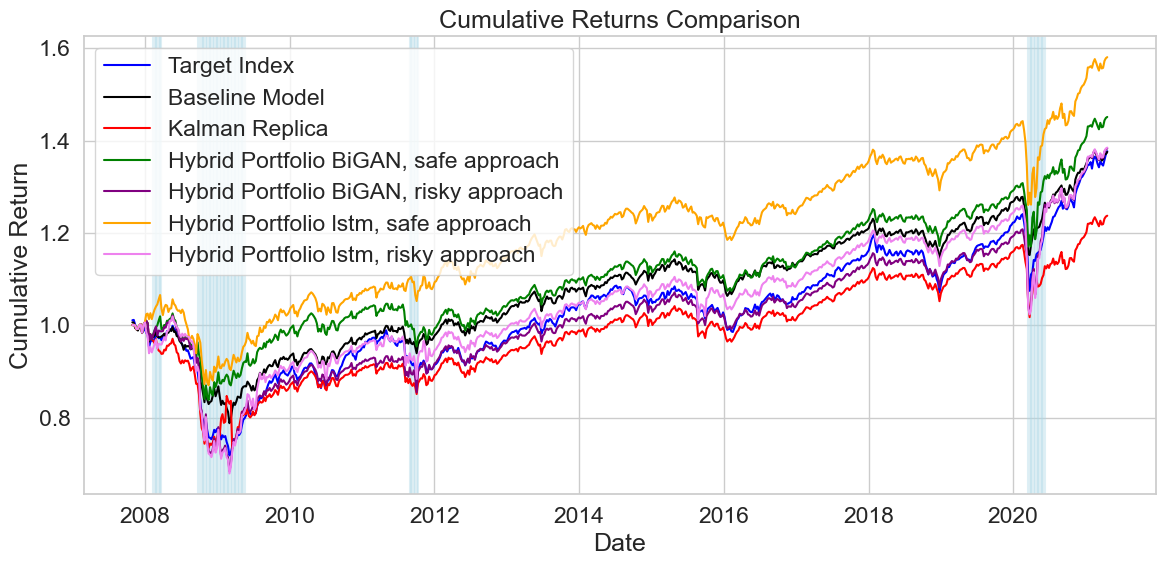

In [75]:
import matplotlib.pyplot as plt
import pandas as pd

pred_col = 'CBiGAN_pred' 

pred_col_2 = 'LSTM_pred'

# Calculate original Kalman replica cumulative returns
replica_returns = (weights_df * C).sum(axis=1)  # elementwise multiply weights by returns and sum per date
cumulative_target = (1 + Y).cumprod()          # original target index cumulative returns
cumulative_replica = (1 + replica_returns).cumprod()


safe_weights = pd.Series(0.0, index=weights_df.columns)
for ticker, w in low_vol_weights.items():
    if ticker in safe_weights.index:
        safe_weights[ticker] = w

risky_weights = pd.Series(0.0, index=weights_df.columns)
for ticker, w in medium_vol_weights.items():
    if ticker in risky_weights.index:
        risky_weights[ticker] = w

# Create hybrid weights DataFrame same shape as weights_df
hybrid_weights = pd.DataFrame(index=weights_df.index, columns=weights_df.columns, dtype=float)

hybrid_weights_risky = pd.DataFrame(index=weights_df.index, columns=weights_df.columns, dtype=float)

hybrid_weights_lstm = pd.DataFrame(index=weights_df.index, columns=weights_df.columns, dtype=float)

hybrid_weights_lstm_risky = pd.DataFrame(index=weights_df.index, columns=weights_df.columns, dtype=float)

# Align indices of final_df and weights_df
final_df_aligned = final_df.reindex(weights_df.index)

# Fill hybrid weights by switching to safe_weights on anomaly days (pred_label=1)
for date in weights_df.index:
    if final_df_aligned.loc[date, pred_col] == 1:
        hybrid_weights.loc[date] = safe_weights.values
    else:
        hybrid_weights.loc[date] = weights_df.loc[date].values

# Fill hybrid weights by switching to risky_weights on anomaly days (pred_label=1)
for date in weights_df.index:
    if final_df_aligned.loc[date, pred_col] == 1:
        hybrid_weights_risky.loc[date] = risky_weights.values
    else:
        hybrid_weights_risky.loc[date] = weights_df.loc[date].values

# Fill hybrid weights by switching to safe_weights on anomaly days (pred_label=1)
for date in weights_df.index:
    if final_df_aligned.loc[date, pred_col_2] == 1:
        hybrid_weights_lstm.loc[date] = safe_weights.values
    else:
        hybrid_weights_lstm.loc[date] = weights_df.loc[date].values

# Fill hybrid weights by switching to risky_weights on anomaly days (pred_label=1)
for date in weights_df.index:
    if final_df_aligned.loc[date, pred_col_2] == 1:
        hybrid_weights_lstm_risky.loc[date] = risky_weights.values
    else:
        hybrid_weights_lstm_risky.loc[date] = weights_df.loc[date].values

# Calculate hybrid portfolio returns and cumulative returns
hybrid_returns = (hybrid_weights * C.loc[hybrid_weights.index]).sum(axis=1)
cumulative_hybrid = (1 + hybrid_returns).cumprod()

# Calculate hybrid portfolio returns and cumulative returns
hybrid_returns_risky = (hybrid_weights_risky * C.loc[hybrid_weights_risky.index]).sum(axis=1)
cumulative_hybrid_risky = (1 + hybrid_returns_risky).cumprod()

# Calculate hybrid portfolio returns and cumulative returns
hybrid_returns_lstm = (hybrid_weights_lstm * C.loc[hybrid_weights_lstm.index]).sum(axis=1)
cumulative_hybrid_lstm = (1 + hybrid_returns_lstm).cumprod()

# Calculate hybrid portfolio returns and cumulative returns
hybrid_returns_lstm_risky = (hybrid_weights_lstm_risky * C.loc[hybrid_weights_lstm_risky.index]).sum(axis=1)
cumulative_hybrid_lstm_risky = (1 + hybrid_returns_lstm_risky).cumprod()



# Plot all cumulative returns
plt.figure(figsize=(12, 6))

# Add shaded anomaly periods (based on CBiGAN_pred)
anomaly_mask = (final_df[pred_col] == 1)
anomaly_dates = final_df.index[anomaly_mask]

for date in anomaly_dates:
    plt.axvline(x=date, color='lightblue', linestyle='-', alpha=0.4)  # Vertical line per anomaly date


plt.plot(cumulative_target.index, cumulative_target, label='Target Index', color='blue')
plt.plot(cumulative_baseline.index, cumulative_baseline, label='Baseline Model', color='black')
plt.plot(cumulative_replica.index, cumulative_replica, label='Kalman Replica', color='red')
plt.plot(cumulative_hybrid.index, cumulative_hybrid, label='Hybrid Portfolio BiGAN, safe approach', color='green')
plt.plot(cumulative_hybrid_risky.index, cumulative_hybrid_risky, label='Hybrid Portfolio BiGAN, risky approach', color='purple')
plt.plot(cumulative_hybrid_lstm.index, cumulative_hybrid_lstm, label='Hybrid Portfolio lstm, safe approach', color='orange')
plt.plot(cumulative_hybrid_lstm_risky.index, cumulative_hybrid_lstm_risky, label='Hybrid Portfolio lstm, risky approach', color='violet')
plt.title('Cumulative Returns Comparison')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


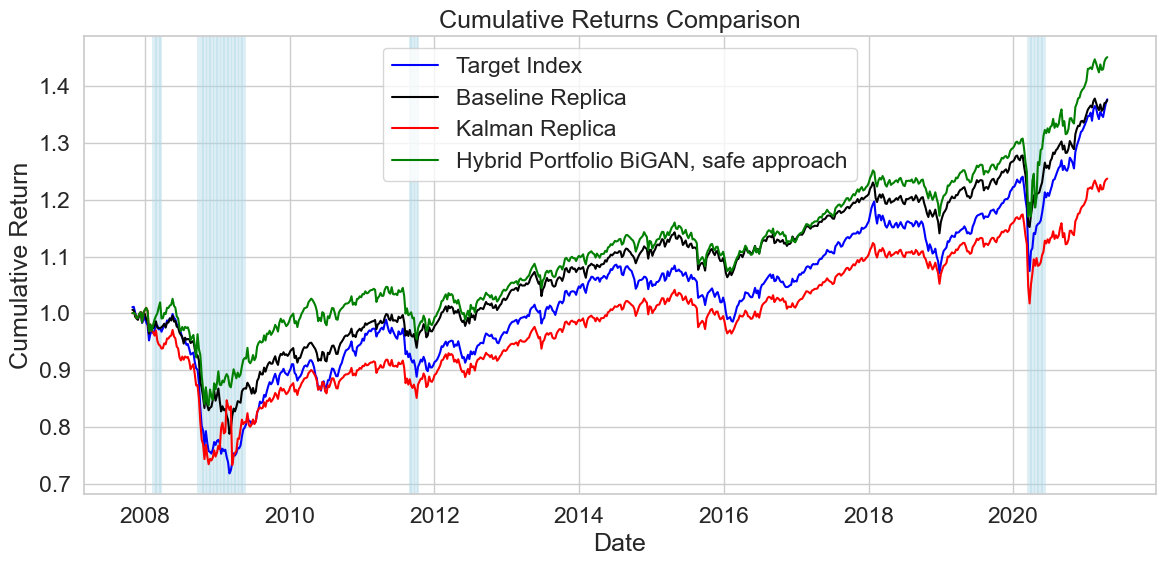

In [76]:
# Plot all cumulative returns
plt.figure(figsize=(12, 6))

# Add shaded anomaly periods (based on CBiGAN_pred)
anomaly_mask = (final_df[pred_col] == 1)
anomaly_dates = final_df.index[anomaly_mask]

for date in anomaly_dates:
    plt.axvline(x=date, color='lightblue', linestyle='-', alpha=0.4)  # Vertical line per anomaly date

plt.plot(cumulative_target.index, cumulative_target, label='Target Index', color='blue')
plt.plot(cumulative_baseline.index, cumulative_baseline, label='Baseline Replica', color='black')
plt.plot(cumulative_replica.index, cumulative_replica, label='Kalman Replica', color='red')
plt.plot(cumulative_hybrid.index, cumulative_hybrid, label='Hybrid Portfolio BiGAN, safe approach', color='green')
plt.title('Cumulative Returns Comparison')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

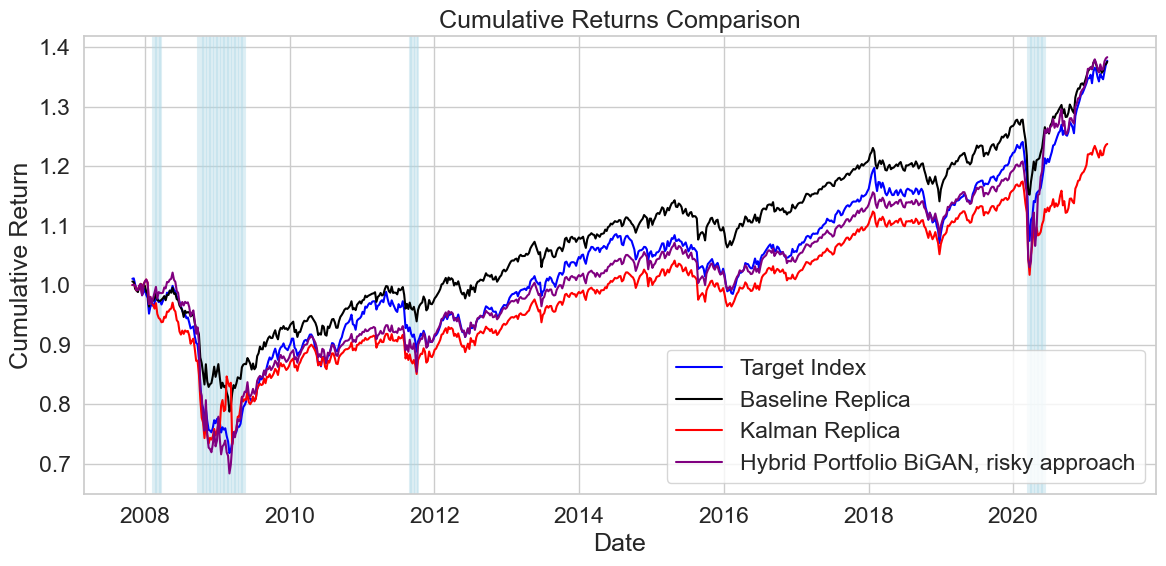

In [77]:
# Plot all cumulative returns
plt.figure(figsize=(12, 6))

# Add shaded anomaly periods (based on CBiGAN_pred)
anomaly_mask = (final_df[pred_col] == 1)
anomaly_dates = final_df.index[anomaly_mask]

for date in anomaly_dates:
    plt.axvline(x=date, color='lightblue', linestyle='-', alpha=0.4)  # Vertical line per anomaly date

plt.plot(cumulative_target.index, cumulative_target, label='Target Index', color='blue')
plt.plot(cumulative_baseline.index, cumulative_baseline, label='Baseline Replica', color='black')
plt.plot(cumulative_replica.index, cumulative_replica, label='Kalman Replica', color='red')
plt.plot(cumulative_hybrid_risky.index, cumulative_hybrid_risky, label='Hybrid Portfolio BiGAN, risky approach', color='purple')
plt.title('Cumulative Returns Comparison')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


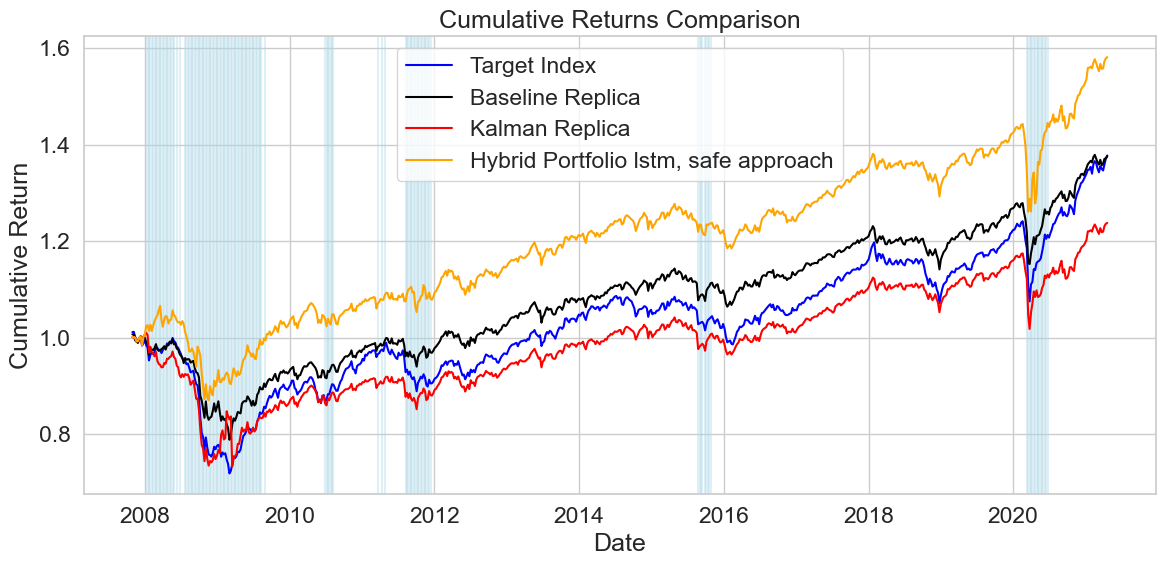

In [78]:
# Plot all cumulative returns
plt.figure(figsize=(12, 6))

# Add shaded anomaly periods (based on lstm)
anomaly_mask = (final_df[pred_col_2] == 1)
anomaly_dates = final_df.index[anomaly_mask]

for date in anomaly_dates:
    plt.axvline(x=date, color='lightblue', linestyle='-', alpha=0.4)  # Vertical line per anomaly date

plt.plot(cumulative_target.index, cumulative_target, label='Target Index', color='blue')
plt.plot(cumulative_baseline.index, cumulative_baseline, label='Baseline Replica', color='black')
plt.plot(cumulative_replica.index, cumulative_replica, label='Kalman Replica', color='red')
plt.plot(cumulative_hybrid_lstm.index, cumulative_hybrid_lstm, label='Hybrid Portfolio lstm, safe approach', color='orange')
plt.title('Cumulative Returns Comparison')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

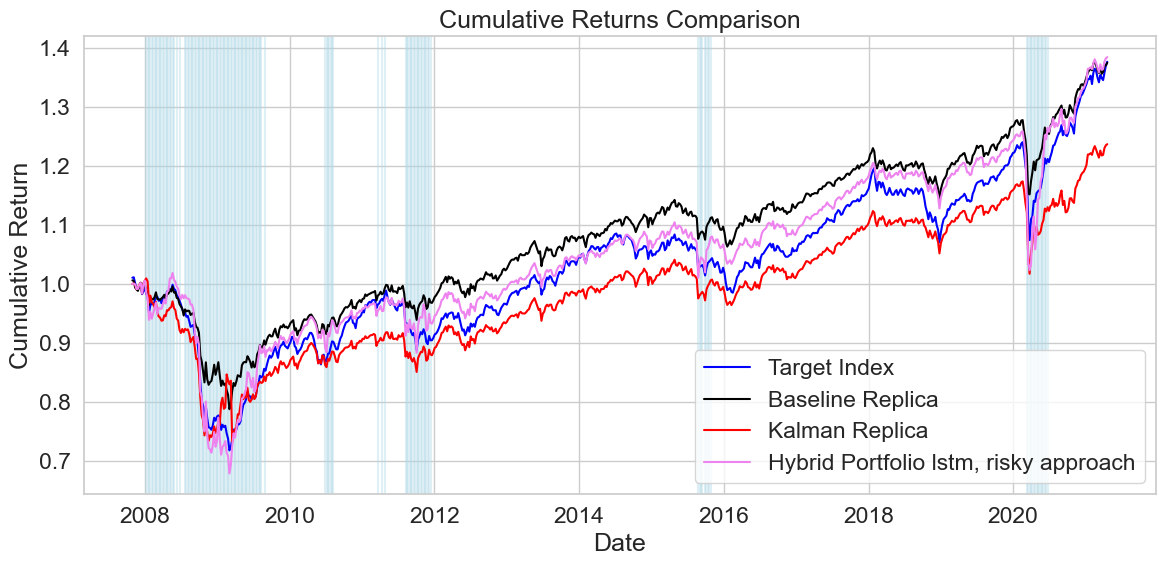

In [79]:
# Plot all cumulative returns
plt.figure(figsize=(12, 6))

# Add shaded anomaly periods (based on CBiGAN_pred)
anomaly_mask = (final_df[pred_col_2] == 1)
anomaly_dates = final_df.index[anomaly_mask]

for date in anomaly_dates:
    plt.axvline(x=date, color='lightblue', linestyle='-', alpha=0.4)  # Vertical line per anomaly date

plt.plot(cumulative_target.index, cumulative_target, label='Target Index', color='blue')
plt.plot(cumulative_baseline.index, cumulative_baseline, label='Baseline Replica', color='black')
plt.plot(cumulative_replica.index, cumulative_replica, label='Kalman Replica', color='red')
plt.plot(cumulative_hybrid_lstm_risky.index, cumulative_hybrid_lstm_risky, label='Hybrid Portfolio lstm, risky approach', color='violet')
plt.title('Cumulative Returns Comparison')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

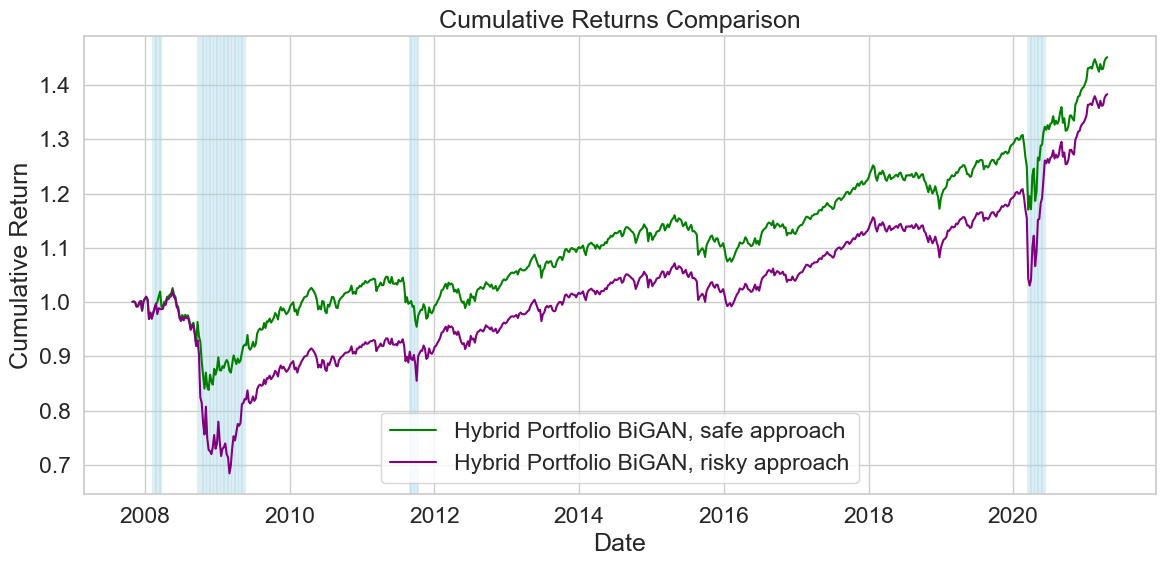

In [80]:
# Plot all cumulative returns
plt.figure(figsize=(12, 6))

anomaly_mask = (final_df[pred_col] == 1)
anomaly_dates = final_df.index[anomaly_mask]

for date in anomaly_dates:
    plt.axvline(x=date, color='lightblue', linestyle='-', alpha=0.4)  # Vertical line per anomaly date

plt.plot(cumulative_hybrid.index, cumulative_hybrid, label='Hybrid Portfolio BiGAN, safe approach', color='green')
plt.plot(cumulative_hybrid_risky.index, cumulative_hybrid_risky, label='Hybrid Portfolio BiGAN, risky approach', color='purple')
plt.title('Cumulative Returns Comparison')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

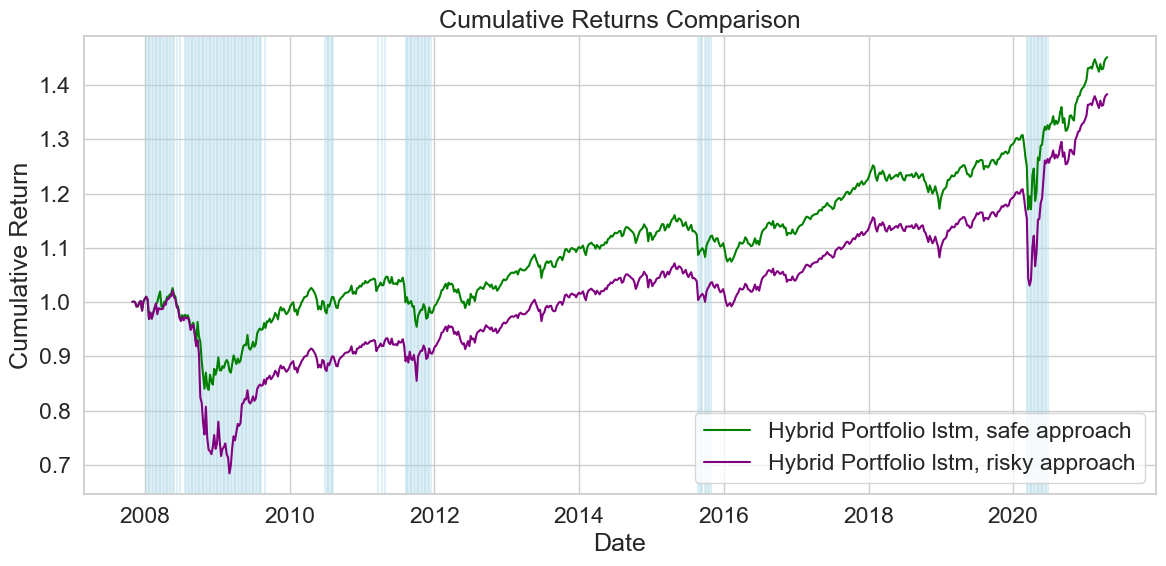

In [81]:
# Plot all cumulative returns
plt.figure(figsize=(12, 6))

anomaly_mask = (final_df[pred_col_2] == 1)
anomaly_dates = final_df.index[anomaly_mask]

for date in anomaly_dates:
    plt.axvline(x=date, color='lightblue', linestyle='-', alpha=0.4)  # Vertical line per anomaly date

plt.plot(cumulative_hybrid_lstm.index, cumulative_hybrid, label='Hybrid Portfolio lstm, safe approach', color='green')
plt.plot(cumulative_hybrid_lstm_risky.index, cumulative_hybrid_risky, label='Hybrid Portfolio lstm, risky approach', color='purple')
plt.title('Cumulative Returns Comparison')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## ADD TRANSACTIONS COST WHEN SWITCHING PORTFOLIO (anomaly period)

In [82]:
def compute_cumulative_with_transaction_costs(weights, returns, cost_per_unit=0.0005):
    # Calcolo dei ritorni giornalieri del portafoglio
    portfolio_returns = (weights * returns.loc[weights.index]).sum(axis=1)

    # Calcolo del turnover giornaliero
    turnover = (weights.diff().abs()).sum(axis=1)
    turnover.iloc[0] = 0.0  # Nessun costo il primo giorno

    # Calcolo dei costi di transazione
    transaction_costs = turnover * cost_per_unit

    # Ritorni netti dopo i costi
    net_returns = portfolio_returns - transaction_costs
    # Ritorni cumulati
    cumulative_net = (1 + net_returns).cumprod()

    return cumulative_net, net_returns, turnover

compute the cumulative returns with transaction cost

In [83]:
cumulative_hybrid_net, _, turnover_hybrid = compute_cumulative_with_transaction_costs(hybrid_weights, C)
cumulative_hybrid, _, turnover_hybrid = compute_cumulative_with_transaction_costs(hybrid_weights, C, 0)
cumulative_hybrid_risky_net, _, turnover_hybrid_risky = compute_cumulative_with_transaction_costs(hybrid_weights, C)
cumulative_hybrid_lstm_net, _, turnover_hybrid_lstm = compute_cumulative_with_transaction_costs(hybrid_weights_lstm, C)
cumulative_hybrid_lstm, _, turnover_hybrid_lstm = compute_cumulative_with_transaction_costs(hybrid_weights_lstm, C, 0)
cumulative_hybrid_lstm_risky_net, _, turnover_hybrid_lstm_risky = compute_cumulative_with_transaction_costs(hybrid_weights_lstm_risky, C)

some plots

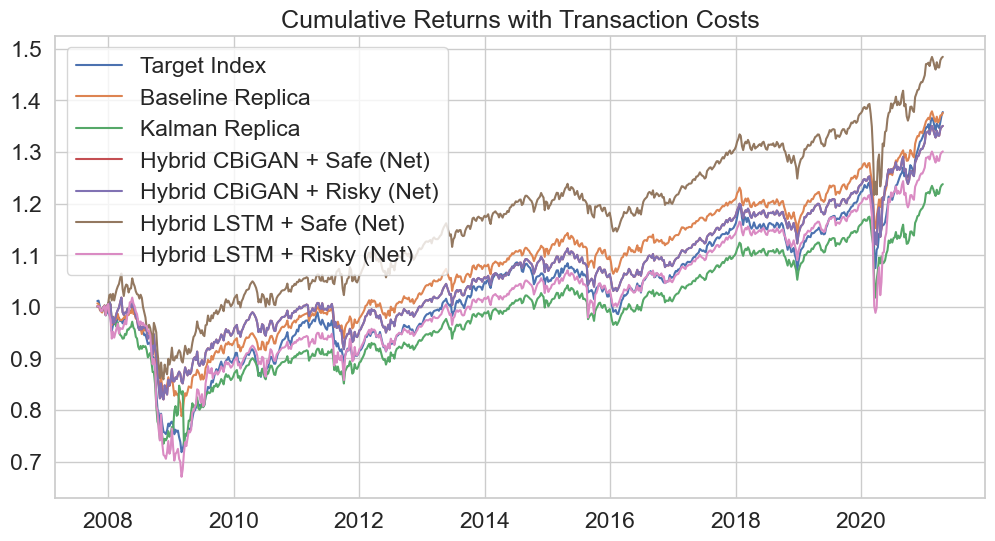

In [84]:
plt.figure(figsize=(12, 6))
plt.plot(cumulative_target, label='Target Index')
plt.plot(cumulative_baseline, label='Baseline Replica')
plt.plot(cumulative_replica, label='Kalman Replica')
plt.plot(cumulative_hybrid_net, label='Hybrid CBiGAN + Safe (Net)')
plt.plot(cumulative_hybrid_risky_net, label='Hybrid CBiGAN + Risky (Net)')
plt.plot(cumulative_hybrid_lstm_net, label='Hybrid LSTM + Safe (Net)')
plt.plot(cumulative_hybrid_lstm_risky_net, label='Hybrid LSTM + Risky (Net)')
plt.title("Cumulative Returns with Transaction Costs")
plt.legend()
plt.grid(True)
plt.show()

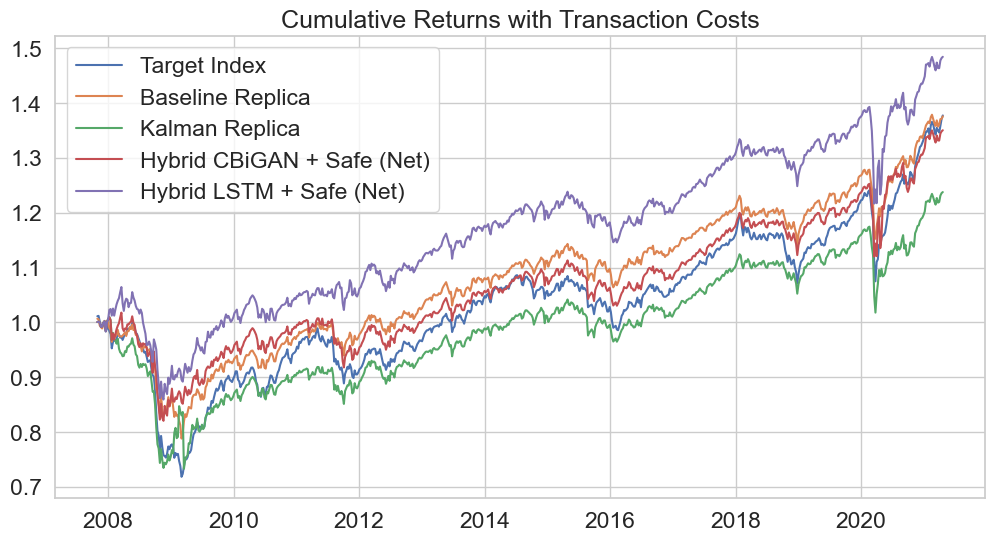

In [85]:
plt.figure(figsize=(12, 6))
plt.plot(cumulative_target, label='Target Index')
plt.plot(cumulative_baseline, label='Baseline Replica')
plt.plot(cumulative_replica, label='Kalman Replica')
plt.plot(cumulative_hybrid_net, label='Hybrid CBiGAN + Safe (Net)')
plt.plot(cumulative_hybrid_lstm_net, label='Hybrid LSTM + Safe (Net)')
plt.title("Cumulative Returns with Transaction Costs")
plt.legend()
plt.grid(True)
plt.show()

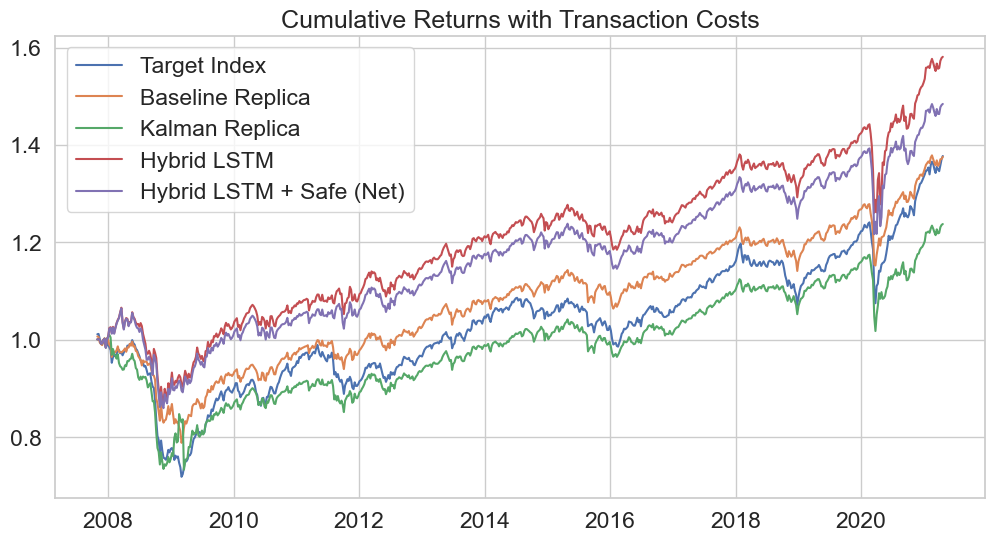

In [86]:
plt.figure(figsize=(12, 6))
plt.plot(cumulative_target, label='Target Index')
plt.plot(cumulative_baseline, label='Baseline Replica')
plt.plot(cumulative_replica, label='Kalman Replica')
plt.plot(cumulative_hybrid_lstm, label='Hybrid LSTM')
plt.plot(cumulative_hybrid_lstm_net, label='Hybrid LSTM + Safe (Net)')
plt.title("Cumulative Returns with Transaction Costs")
plt.legend()
plt.grid(True)
plt.show()

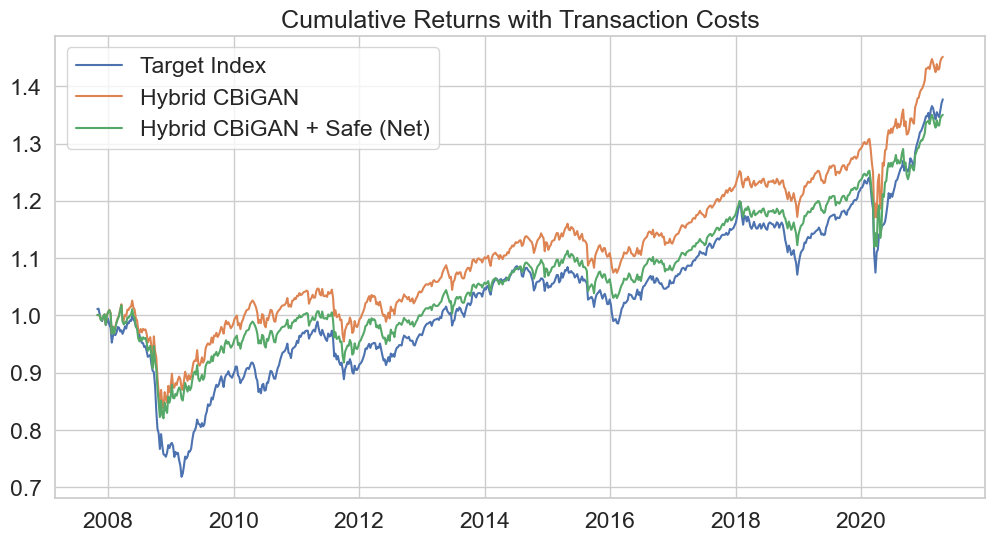

In [87]:
plt.figure(figsize=(12, 6))
plt.plot(cumulative_target, label='Target Index')
plt.plot(cumulative_hybrid, label='Hybrid CBiGAN')
plt.plot(cumulative_hybrid_net, label='Hybrid CBiGAN + Safe (Net)')
plt.title("Cumulative Returns with Transaction Costs")
plt.legend()
plt.grid(True)
plt.show()
